# PRIME online performance — average of pilot003 to pilot006

This notebook draws the figures of `PRIME_online_performance.ipynb` for the four closed-loop pilot
sessions **pilot003, pilot004, pilot005 and pilot006** together. Every quantity is first computed
for each session the way the single-session notebook computes it, then averaged across the four
sessions with **each pilot weighted equally**. Sections and items keep the single-session
notebook's numbering, so each figure here has a counterpart there.

How to read the figures:

- **Thick lines, bars and black markers are the mean over the four pilots.** Thin lines and
  coloured markers are the individual pilots. Each pilot keeps one colour and one marker shape
  throughout (legend in each figure).
- **Histograms:** bar height = mean over pilots of that bin's count (or density, where the
  single-session plot shows a density). Thin outlines are each pilot's own histogram.
- **Trend plots over `trial_order`:** each pilot's rolling mean is computed as in the
  single-session notebook, then the four curves are averaged on the shared 0–799 trial axis (every
  session has 4 blocks × 200 intervention trials).
- **Per-trial bar plots in trial order** (section 8.4) have no counterpart across sessions: each
  pilot's trials are sorted and drawn against the fraction of trials, and the sorted profiles are
  averaged.
- **Tables** give each pilot and the mean of the pilots ("mean" = mean of the four per-pilot values).
- **Statistics** (correlations, Mann-Whitney tests, AUCs) are computed within each pilot; tables
  give each pilot's value and their mean (correlations averaged via Fisher's z). Nothing is tested
  across pilots (n = 4).

What differs between the sessions (details in sections 1–4 and chapter 2):

| | pilot003 | pilot004 | pilot005 | pilot006 |
|---|---|---|---|---|
| session date | 2026-09-02 | 2026-09-04 | 2026-09-17 | 2026-10-15 |
| `prime/decider` commit that ran it | `b2447b1` | `b2447b1` | `f4fd395` | `007b932` |
| post-stimulus processing | 1 kHz | 1 kHz | 1 kHz | 5 kHz + 500 Hz low-pass |
| TEP baseline window | −25 to −15 ms | −25 to −15 ms | −25 to −15 ms | −15 to −5 ms |
| first artifact blank (`artifact_window_1`) | −14 to 14 ms | −14 to 14 ms | −14 to 14 ms | −2 to 14 ms |
| ocular z cutoff | 2.0 | 2.0 | 2.5 | 3.0 |
| `TARGET_WAIT` | 0.65 s | 0.65 s | 0.65 s | 0.50 s |

Each session calibrated its own dipole, at a different place each time (section 3), and raw dipole
amplitudes differ about threefold between pilots. So chapter 2 shows raw amplitudes per pilot and
adds each pilot's amplitudes relative to its own baseline block.

**Chapter 2 replays each session with the settings it ran with.** `prime/decider` has changed since
these sessions, and the baseline window, first artifact blank and ocular z cutoff are not stored in
the calibration bundles. The notebook applies each session's own values to its restored
preprocessor in memory (nothing in `prime/` is modified). Before using the replay, it checks the
values: it reprocesses all 320 intervention single pulses of every session from their raw buffers
and compares the result with what the decider saved online.

Runtime: chapter 2's replay takes a few minutes the first time. Its results are cached in
`scripts_analysis/PRIME_online_performance_avg_outputs/cache/`, so later runs take about as long
as the plotting. Set `RECOMPUTE_REPLAY = True` in section 1 to redo it.

## 1 · Sessions and setup

The sessions are found as in the single-session notebook:
`<LOOP_ROOT>/BIDS/sub-<pilot>/ses-prime/<run>/prime`. `LOOP_ROOT` comes from the `LOOP_ROOT`
environment variable, else `D:\Linus\Loop`, else `~/Desktop/Loop`, else the first parent of the
working directory that contains both `BIDS/` and `prime/`.

`AS_RUN` holds, per session, the settings that are **not** stored in its calibration bundle and
have changed in `prime/decider` since:

- the TEP baseline window and the first artifact blank (`prime_core/preprocessing/config.py`),
- the ocular z cutoff (same file; `preprocess_post` reads it from the config, not from the bundle),
- `TARGET_WAIT` (`2_intervention.py`; only used here to label reference lines in section 8.7).

The values come from the decider commit that was checked out on each session's day (`git log`
against the write times of the session's files), read with `git show <commit>:<file>`. Chapter 2
verifies the first three against each session's online data before using them.

In [1]:
from __future__ import annotations

import os, sys, time, pickle, platform, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
import mne

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 100, "figure.figsize": (10, 3.4),
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})

# Condition colours, as in PRIME_online_performance.ipynb.
COLOR_PREDETERMINED = "#5b8ff9"   # blue
COLOR_PRIME_SINGLE  = "#e8684a"   # orange
COLOR_PRIME_TRIPLET = "#9270ca"   # purple
COLOR_MEAN          = "#0b0b0b"   # mean over pilots, wherever the pilots themselves are coloured

# One colour and one marker shape per pilot, everywhere the pilots are told apart. The four colours
# were checked as a set for colour-vision deficiencies; the marker shape is the second cue.
PILOT_COLORS  = {"pilot003": "#008300", "pilot004": "#e87ba4", "pilot005": "#eda100", "pilot006": "#6250d6"}
PILOT_MARKERS = {"pilot003": "o", "pilot004": "s", "pilot005": "^", "pilot006": "D"}

print(f"python {platform.python_version()}  numpy {np.__version__}  pandas {pd.__version__}  "
      f"scipy {scipy.__version__}  matplotlib {matplotlib.__version__}  mne {mne.__version__}")

python 3.10.12  numpy 2.2.6  pandas 2.3.3  scipy 1.15.3  matplotlib 3.10.9  mne 1.10.0


In [2]:
# ---------------------------------------------------------------- the four sessions and their as-run settings
PILOTS = ["pilot003", "pilot004", "pilot005", "pilot006"]

AS_RUN = {
    # BIDS session/run; decider commit checked out that day; settings not stored in the bundle
    "pilot003": dict(session="ses-prime", run="103", commit="b2447b1",
                     baseline=(-0.025, -0.015), artifact_window_1=(-0.014, 0.014), ocular_z=2.0,
                     target_wait=0.65),
    "pilot004": dict(session="ses-prime", run="104", commit="b2447b1",
                     baseline=(-0.025, -0.015), artifact_window_1=(-0.014, 0.014), ocular_z=2.0,
                     target_wait=0.65),
    "pilot005": dict(session="ses-prime", run="105", commit="f4fd395",
                     baseline=(-0.025, -0.015), artifact_window_1=(-0.014, 0.014), ocular_z=2.5,
                     target_wait=0.65),
    "pilot006": dict(session="ses-prime", run="106", commit="007b932",
                     baseline=(-0.015, -0.005), artifact_window_1=(-0.002, 0.014), ocular_z=3.0,
                     target_wait=0.50),
}

RECOMPUTE_REPLAY = False     # True: redo chapter 2's replay and its check even if cached results exist
STRICT_REPLAY_CHECK = True   # True: stop in chapter 2 if a session's replay does not reproduce its online data

def _find_loop_root() -> Path:
    env = os.environ.get("LOOP_ROOT")
    candidates = [env] if env else []
    candidates += [r"D:\Linus\Loop", str(Path.home() / "Desktop" / "Loop")]
    for c in candidates:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError(
        "Could not locate the Loop root (a folder containing both 'BIDS' and 'prime'). "
        "Set the LOOP_ROOT environment variable, or edit _find_loop_root()."
    )

LOOP_ROOT = _find_loop_root()
SESSION_DIRS = {p: LOOP_ROOT / "BIDS" / f"sub-{p}" / AS_RUN[p]["session"] / AS_RUN[p]["run"] / "prime"
                for p in PILOTS}
for p, d in SESSION_DIRS.items():
    if not d.is_dir():
        raise FileNotFoundError(f"Session folder not found: {d}")

# This notebook's outputs (combined trial table, chapter 2's replay cache). The single-session
# notebook's own output folder is only read: item 2 reuses its cached classifier predictions.
OUTPUT_DIR = Path(os.environ.get("PRIME_AVG_OUTPUT_DIR",
                                 LOOP_ROOT / "scripts_analysis" / "PRIME_online_performance_avg_outputs"))
CACHE_DIR = OUTPUT_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
SINGLE_SESSION_OUTPUT_DIR = LOOP_ROOT / "scripts_analysis" / "PRIME_online_performance_outputs"

def bundle_path(d: Path) -> Path:
    """calibration_bundle.npy, or calibration_bunble.npy (the spelling before decider commit 6501b2b)."""
    for name in ("calibration_bundle.npy", "calibration_bunble.npy"):
        if (d / name).is_file():
            return d / name
    raise FileNotFoundError(f"no calibration bundle in {d}")

def _rel(path: Path) -> str:
    """Path relative to the Loop root when it lies inside it (shorter, and the same on every machine)."""
    try:
        return str(Path(path).relative_to(LOOP_ROOT))
    except ValueError:
        return str(path)

print(f"Loop root : {LOOP_ROOT}")
for p in PILOTS:
    print(f"{p}  : {_rel(SESSION_DIRS[p])}")
print(f"output dir: {_rel(OUTPUT_DIR)}")

Loop root : /sessions/rcw-01t3lqdpz6uyjpff4fqguftc/mnt/Loop
pilot003  : BIDS/sub-pilot003/ses-prime/103/prime
pilot004  : BIDS/sub-pilot004/ses-prime/104/prime
pilot005  : BIDS/sub-pilot005/ses-prime/105/prime
pilot006  : BIDS/sub-pilot006/ses-prime/106/prime
output dir: scripts_analysis/PRIME_online_performance_avg_outputs


In [3]:
# ---------------------------------------------------------------- inventory of the four session folders
_BUFFER_SUFFIXES = ("_pre_raw.npy", "_post_raw.npy", "_post_proc.npy", "_pre_proc.npy", "_baseline.npy",
                    "_trial_raw.npy")
_READ = ["calibration_summary.csv", "dipole_fitting_info.npy", "proc_info.npy", "prime_predictions.csv",
         "trials_baseline.csv", "trials_intervention.csv", "classifier_after_calibration.pt"]
rows = []
for p in PILOTS:
    names = [f.name for f in SESSION_DIRS[p].iterdir()]
    rows.append({
        "pilot": p,
        "files": len(names),
        "per-trial buffers": sum(n.endswith(_BUFFER_SUFFIXES) for n in names),
        "per-trial checkpoints": sum(n.startswith("classifier_after_trial_") for n in names),
        "trials_evaluation_*.csv": sum(n.startswith("trials_evaluation_") for n in names),
        "profile_*.csv": sum(n.startswith("profile_") for n in names),
        "bundle file": bundle_path(SESSION_DIRS[p]).name,
        "missing": ", ".join(f for f in _READ if f not in names) or "-",
    })
display(pd.DataFrame(rows).set_index("pilot"))

,files,per-trial buffers,per-trial checkpoints,trials_evaluation_*.csv,profile_*.csv,bundle file,missing
pilot,,,,,,,
pilot003,6182,5365,800,4,5,calibration_bundle.npy,-
pilot004,6185,5368,800,4,5,calibration_bundle.npy,-
pilot005,6186,5369,800,4,5,calibration_bundle.npy,-
pilot006,6189,5372,800,4,5,calibration_bundle.npy,-


In [4]:
# ---------------------------------------------------------------- helpers for averaging over pilots
def with_mean(df: pd.DataFrame, label: str = "mean") -> pd.DataFrame:
    """Pilots as columns -> the same table plus a column with the mean of the pilots."""
    out = df.copy()
    out[label] = df.mean(axis=1, numeric_only=True)
    return out

def mean_r(rs) -> float:
    """Mean of correlation coefficients via Fisher's z."""
    rs = np.asarray([r for r in rs if np.isfinite(r)], float)
    if len(rs) == 0:
        return np.nan
    return float(np.tanh(np.mean(np.arctanh(np.clip(rs, -0.999999, 0.999999)))))

def describe_mean(series_by_pilot: dict, **kw) -> pd.DataFrame:
    """describe() per pilot (columns) plus the mean of each statistic over the pilots."""
    return with_mean(pd.DataFrame({p: pd.Series(s, dtype=float).describe(**kw)
                                   for p, s in series_by_pilot.items()}))

def pilot_line_handles(pilots=PILOTS):
    return [Line2D([], [], color=PILOT_COLORS[p], lw=1.2, label=p) for p in pilots]

def pilot_marker_handles(pilots=PILOTS, color=None):
    return [Line2D([], [], ls="none", marker=PILOT_MARKERS[p], color=color or PILOT_COLORS[p],
                   markeredgecolor="black", markeredgewidth=0.5, markersize=6, label=p) for p in pilots]

def hist_by_pilot(values_by_pilot: dict, bins, density=False) -> np.ndarray:
    """One histogram per pilot on shared bins -> array (pilots x bins)."""
    rows = []
    for v in values_by_pilot.values():
        v = np.asarray(pd.Series(v, dtype=float).dropna())
        rows.append(np.histogram(v, bins=bins, density=density)[0].astype(float) if len(v)
                    else np.full(len(bins) - 1, np.nan))
    return np.vstack(rows)

def plot_mean_hist(ax, values_by_pilot: dict, bins, color, label=None, density=False, alpha=0.55,
                   outline="pilot"):
    """Bars = mean over pilots of each bin's count (or density). Thin outlines = each pilot's own
    histogram: outline="pilot" draws them in pilot colours, a colour string in that colour, None not at all."""
    h = hist_by_pilot(values_by_pilot, bins, density=density)
    mean = np.nanmean(h, axis=0)
    ax.bar(bins[:-1], mean, width=np.diff(bins), align="edge", color=color, alpha=alpha, label=label,
           linewidth=0)
    if outline is not None:
        for p, row in zip(values_by_pilot, h):
            if outline == "pilot":
                ax.stairs(row, bins, color=PILOT_COLORS[p], lw=0.9, alpha=0.9)
            else:
                ax.stairs(row, bins, color=outline, lw=0.8, alpha=0.4)
    return mean, h

BLOCK_NAMES = [f"intervention_block_{i}" for i in range(1, 5)]
BLOCK_TICKLABELS = [f"block {i}" for i in range(1, 5)]
TRIAL_GRID = np.arange(800)          # trial_order of the 800 intervention trials, the same in every session
BLOCK_EDGES = [200, 400, 600]

def rolling_on_grid(df, ycol, cond, window):
    """One pilot's rolling mean of ycol over trial_order for one condition (as in the single-session
    notebook's trend_plot), interpolated onto TRIAL_GRID; NaN outside the condition's first/last trial."""
    d = df.loc[df.condition == cond, ["trial_order", ycol]].dropna().sort_values("trial_order")
    if d.empty:
        return None
    roll = d[ycol].rolling(window, min_periods=max(3, window // 3), center=True).mean().to_numpy()
    x = d.trial_order.to_numpy(float)
    ok = np.isfinite(roll)
    if ok.sum() < 2:
        return None
    return np.interp(TRIAL_GRID, x[ok], roll[ok], left=np.nan, right=np.nan)

def trend_plot_avg(ax, frames: dict, ycol, conditions, colors, window=25):
    """Thin lines = each pilot's rolling mean; thick line = mean of those curves on the shared trial axis."""
    for cond, color in zip(conditions, colors):
        curves = [c for c in (rolling_on_grid(frames[p], ycol, cond, window) for p in frames) if c is not None]
        if not curves:
            continue
        for c in curves:
            ax.plot(TRIAL_GRID, c, color=color, lw=0.8, alpha=0.35)
        ax.plot(TRIAL_GRID, np.nanmean(np.vstack(curves), axis=0), color=color, lw=2.0,
                label=f"{cond} (mean of {len(curves)} pilots' rolling means, w={window})")
    for edge in BLOCK_EDGES:
        ax.axvline(edge, color="grey", lw=0.7, ls=":")
    ax.set_xlabel("trial order")
    ax.set_ylabel(ycol)
    ax.legend(fontsize=8)

def block_bars_with_pilots(ax, per_block: pd.DataFrame, color, ylabel, title, extra_handles=()):
    """per_block: rows = intervention blocks, columns = pilots. Bars = mean of pilots, markers = pilots.
    The legend goes below the axes, so it never covers a bar or a marker."""
    per_block = per_block.reindex(BLOCK_NAMES)
    x = np.arange(len(BLOCK_NAMES))
    ax.bar(x, per_block.mean(axis=1), color=color, alpha=0.6, label="mean of pilots")
    for off, p in zip(np.linspace(-0.24, 0.24, per_block.shape[1]), per_block.columns):
        ax.scatter(x + off, per_block[p], marker=PILOT_MARKERS[p], color=PILOT_COLORS[p],
                   edgecolor="black", linewidth=0.5, s=32, zorder=3, label=p)
    ax.set_xticks(x)
    ax.set_xticklabels(BLOCK_TICKLABELS)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    h, l = ax.get_legend_handles_labels()
    h = list(h) + list(extra_handles)
    ax.legend(handles=h, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=min(len(h), 5),
              frameon=False)

FRACTION_GRID = np.linspace(0, 1, 201)

def sorted_profile(values, descending=True):
    """A pilot's values sorted (largest first by default) and resampled onto FRACTION_GRID,
    so that sessions with different numbers of trials can be averaged."""
    v = np.sort(np.asarray(pd.Series(values, dtype=float).dropna()))
    if descending:
        v = v[::-1]
    if len(v) == 0:
        return np.full(len(FRACTION_GRID), np.nan)
    if len(v) == 1:
        return np.full(len(FRACTION_GRID), v[0])
    return np.interp(FRACTION_GRID, (np.arange(len(v)) + 0.5) / len(v), v)

## 2 · Calibration bundle (`calibration_bundle.npy`) and `calibration_summary.csv`

At the end of each session's 125-trial calibration block, `Preprocessor.calibrate()`
(`prime_core/preprocessing/preprocessor.py`) fits every parameter the online pipeline needs for
the rest of that session — bad channels, the pre-stimulus artifact filter, ICA, spatial filters,
and per-stage rejection statistics — and saves them as `calibration_bundle.npy`
(`calibration_bunble.npy` in decider versions before commit `6501b2b`; both spellings are read).
`calibration_summary.csv` records how many trials it used.

Trials are dropped from the 125 in three sequential stages (a trial dropped at one stage is not
re-considered at the next): **ocular** (the trial's activity in the eye-blink ICA components),
**qc** (pre-stimulus window, global/local MAD) and **post** (post-stimulus window, MAD). Each table
below has one column per pilot and the mean of the four.

In [5]:
bundles, n_used = {}, {}
for p in PILOTS:
    bundles[p] = np.load(bundle_path(SESSION_DIRS[p]), allow_pickle=True).item()
    n_used[p] = int(pd.read_csv(SESSION_DIRS[p] / "calibration_summary.csv")["num_calibration_trials"].iloc[0])

N_DELIVERED = 125  # calibration pulses per session (protocol parameter, not read from disk)
calib = pd.DataFrame({p: {"num_calibration_trials": n_used[p], "delivered": N_DELIVERED,
                          "rejection rate (%)": 100 * (1 - n_used[p] / N_DELIVERED)} for p in PILOTS})
print("calibration_summary.csv:")
display(with_mean(calib).round(1))

calibration_summary.csv:


,pilot003,pilot004,pilot005,pilot006,mean
num_calibration_trials,108.0,113.0,107.0,115.0,110.8
delivered,125.0,125.0,125.0,125.0,125.0
rejection rate (%),13.6,9.6,14.4,8.0,11.4


In [6]:
# ---------------------------------------------------------------- rejection cascade
cascade = {}
for p in PILOTS:
    dropped, kept = bundles[p]["trials_dropped"], bundles[p]["trials_kept"]
    n_oc, n_qc, n_post = len(dropped["ocular"]), len(dropped["qc"]), len(dropped["post"])
    cascade[p] = {
        "delivered": N_DELIVERED,
        "after ocular check": N_DELIVERED - n_oc,
        "after qc check": N_DELIVERED - n_oc - n_qc,
        "after post check": N_DELIVERED - n_oc - n_qc - n_post,
        "dropped at ocular": n_oc, "dropped at qc": n_qc, "dropped at post": n_post,
    }
    assert cascade[p]["after post check"] == len(kept) == n_used[p], \
        f"{p}: cascade does not reconcile with trials_kept / calibration_summary"
print("Calibration-trial rejection cascade (sequential; a trial dropped at one stage is not "
      "re-evaluated at the next):")
display(with_mean(pd.DataFrame(cascade)).round(2))

Calibration-trial rejection cascade (sequential; a trial dropped at one stage is not re-evaluated at the next):


,pilot003,pilot004,pilot005,pilot006,mean
delivered,125,125,125,125,125.00
after ocular check,117,117,112,121,116.75
after qc check,114,114,108,115,112.75
after post check,108,113,107,115,110.75
dropped at ocular,8,8,13,4,8.25
dropped at qc,3,3,4,6,4.00
dropped at post,6,1,1,0,2.00


In [7]:
# ---------------------------------------------------------------- bad channels & interpolation
rows, bad_count = [], Counter()
for p in PILOTS:
    bads = [str(c) for c in bundles[p]["bad_channels"]]
    bad_count.update(bads)
    rows.append({"pilot": p, "n bad": len(bads), "bad channels": ", ".join(bads) or "(none)",
                 "interpolation matrix": str(bundles[p]["channel_interpolation_info"]["interpolation_matrix"].shape)})
display(pd.DataFrame(rows).set_index("pilot"))
print(f"mean number of bad channels per pilot: {np.mean([r['n bad'] for r in rows]):.2f}")
print("bad in more than one pilot: "
      + (", ".join(f"{c} ({n}/4)" for c, n in bad_count.most_common() if n > 1) or "none"))

,n bad,bad channels,interpolation matrix
pilot,,,
pilot003,5,"C3, CP3, FC1, P4, T7","(5, 55)"
pilot004,3,"Fz, P4, P8","(3, 57)"
pilot005,3,"C3, CP3, T8","(3, 57)"
pilot006,7,"C3, F3, FC1, FC3, FT7, T7, T8","(7, 53)"


mean number of bad channels per pilot: 4.50
bad in more than one pilot: C3 (3/4), CP3 (2/4), FC1 (2/4), P4 (2/4), T7 (2/4), T8 (2/4)


In [8]:
# ---------------------------------------------------------------- QC filter + MAD rejection stats
rows = {}
for p in PILOTS:
    b = bundles[p]
    row = {}
    for label, key in [("pre", "good_trial_stats_qc"), ("post", "good_trial_stats_post")]:
        s = b[key]
        row[f"{label}: n trials fit"] = len(s["mads"])
        row[f"{label}: mean(MAD)"] = s["mads_mean"]
        row[f"{label}: std(MAD)"] = s["mads_std"]
    rows[p] = row
print("MAD statistics of the calibration trials (online: z = (MAD(trial) - mean(MAD)) / std(MAD), "
      "compared against a fixed threshold, section 8.3):")
display(with_mean(pd.DataFrame(rows)).round(4))
print("pre-stimulus artifact filter, (b, a) coefficient shapes: "
      + "; ".join(f"{p} {[np.asarray(a).shape for a in bundles[p]['qc_filter']]}" for p in PILOTS))

MAD statistics of the calibration trials (online: z = (MAD(trial) - mean(MAD)) / std(MAD), compared against a fixed threshold, section 8.3):


,pilot003,pilot004,pilot005,pilot006,mean
pre: n trials fit,114.0000,114.0000,108.0000,115.0000,112.7500
pre: mean(MAD),3.3515,3.5282,3.6416,2.1652,3.1716
pre: std(MAD),0.6962,1.2446,1.5672,0.6855,1.0484
post: n trials fit,108.0000,113.0000,107.0000,115.0000,110.7500
post: mean(MAD),2.0919,4.9416,1.6715,4.3093,3.2536
post: std(MAD),0.5654,1.6706,0.6191,1.1699,1.0062


pre-stimulus artifact filter, (b, a) coefficient shapes: pilot003 [(5,), (5,)]; pilot004 [(5,), (5,)]; pilot005 [(5,), (5,)]; pilot006 [(5,), (5,)]


In [9]:
# ---------------------------------------------------------------- ocular ICA components
rows = []
for p in PILOTS:
    for comp_idx, info in bundles[p]["ocular_threshold_post"].items():
        rows.append({"pilot": p, "ICA component": int(comp_idx),
                     "n time samples characterised": len(info["time_indices_of_interest"]),
                     "calibration mean |activation|": info["mean"],
                     "calibration std |activation|": info["std"],
                     "ocular z cutoff (as run)": AS_RUN[p]["ocular_z"]})
ocular_tab = pd.DataFrame(rows)
print("Eye-blink ICA components characterised at calibration. Online, a trial is ocular-rejected if "
      "its median z-score in any of them (over the same samples) exceeds that session's z cutoff:")
display(ocular_tab.set_index(["pilot", "ICA component"]).round(4))
n_oc = ocular_tab.groupby("pilot").size()
print(f"ocular components per pilot: {n_oc.to_dict()}  (mean {n_oc.mean():.2f})")
print("The sample counts differ because the post epoch is sampled at 1 kHz in pilot003-005 and at "
      "5 kHz in pilot006 (section 4).")

Eye-blink ICA components characterised at calibration. Online, a trial is ocular-rejected if its median z-score in any of them (over the same samples) exceeds that session's z cutoff:


n time samples characterised  calibration mean |activation|  calibration std |activation|  ocular z cutoff (as run)
pilot    ICA component                                                                                                                     
pilot003 0                                        86                         0.2876                        0.7764                       2.0
         6                                        86                         0.5651                        0.7386                       2.0
pilot004 0                                        86                         0.6580                        1.1368                       2.0
         3                                        86                         0.4993                        0.5348                       2.0
pilot005 0                                        86                         0.5003                        0.7840                       2.5
         1                                        86                         0.5427                        0.8091                       2.5
         2                                        86                         0.3220                        0.6462                       2.5
pilot006 0                                       426                         0.8999                        1.6006                       3.0
         4                                       426                         2.1003                        4.4726                       3.0

ocular components per pilot: {'pilot003': 2, 'pilot004': 2, 'pilot005': 3, 'pilot006': 2}  (mean 2.25)
The sample counts differ because the post epoch is sampled at 1 kHz in pilot003-005 and at 5 kHz in pilot006 (section 4).


In [10]:
# ---------------------------------------------------------------- ICA and spatial filters
rows = []
for p in PILOTS:
    b, ica = bundles[p], bundles[p]["ica"]
    rows.append({"pilot": p, "ICA method": ica.method, "n_components": ica.n_components_,
                 "excluded": ", ".join(str(int(c)) for c in ica.exclude), "n excluded": len(ica.exclude),
                 "fit on n samples": ica.n_samples_,
                 **{key: str(np.asarray(b[key]).shape) for key in
                    ["sound_filter", "sspsir_suppression_matrix_P", "sspsir_filter_kernel",
                     "sspsir_sir_projmat_suppr", "sspsir_sir_projmat_orig"]}})
ica_tab = pd.DataFrame(rows).set_index("pilot")
display(ica_tab)
print(f"mean over pilots: n_components {ica_tab['n_components'].mean():.2f}, "
      f"excluded {ica_tab['n excluded'].mean():.2f}")

,ICA method,n_components,excluded,n excluded,fit on n samples,sound_filter,sspsir_suppression_matrix_P,sspsir_filter_kernel,sspsir_sir_projmat_suppr,sspsir_sir_projmat_orig
pilot,,,,,,,,,,
pilot003,infomax,29,"0, 6",2,137000,"(60, 60)","(60, 60)","(60, 100)","(60, 60)","(60, 60)"
pilot004,infomax,24,"0, 3",2,137000,"(60, 60)","(60, 60)","(60, 100)","(60, 60)","(60, 60)"
pilot005,infomax,11,"0, 1, 2",3,137000,"(60, 60)","(60, 60)","(60, 100)","(60, 60)","(60, 60)"
pilot006,infomax,21,"0, 4",2,137000,"(60, 60)","(60, 60)","(60, 496)","(60, 60)","(60, 60)"


mean over pilots: n_components 21.25, excluded 2.25


## 3 · Dipole fitting info (`dipole_fitting_info.npy`)

`DipoleFitter.calibrate()` fixes, for the rest of each session, the position (one fsaverage
source-space vertex), the orientation and the time window every single-trial dipole amplitude is
computed from (see section 3 of the single-session notebook for how the window is chosen). The
window is counted in samples at the fit's own rate: 1 kHz for pilot003–005, 5 kHz for pilot006.

Each session fits its own dipole. The table lists the four, the next tables give the distances and
angles between them, and the figure shows all four together with their **mean position** (centroid
of the four positions) and **mean orientation** (normalised sum of the four unit vectors). The
mean dipole summarises where the four fits lie; no session used it.

In [11]:
def _window_sfreq(proc_info, window):
    """Sampling rate (Hz) of one proc_info window ('pre', 'post', 'dipole'). Since the 5 kHz decider
    (pilot006 on) every window carries its own 'sfreq'; pilot001-005 store one top-level 'sfreq'."""
    w = proc_info[window]
    return float(w["sfreq"]) if "sfreq" in w else float(proc_info["sfreq"])

dipole_info = {p: np.load(SESSION_DIRS[p] / "dipole_fitting_info.npy", allow_pickle=True).item() for p in PILOTS}
proc_info = {p: np.load(SESSION_DIRS[p] / "proc_info.npy", allow_pickle=True).item() for p in PILOTS}

rows = []
for p in PILOTS:
    di, pi = dipole_info[p], proc_info[p]
    sf = _window_sfreq(pi, "dipole")
    fit_sf = float(di.get("sfreq", 1000.0))   # legacy dipole_fitting_info.npy has no 'sfreq' (1 kHz)
    assert abs(fit_sf - sf) < 1e-6, f"{p}: fit at {fit_sf:.0f} Hz but proc_info's dipole window is {sf:.0f} Hz"
    i0, i1 = di["index_range"]                # i1 is exclusive
    t0, dt = pi["dipole"]["tmin"] * 1000, 1000.0 / sf
    rows.append({"pilot": p, "vertex": int(di["position_index"]),
                 "orientation (x, y, z)": np.round(np.asarray(di["orientation"]), 3),
                 "index_range": f"[{i0}, {i1})", "rate (Hz)": sf, "samples": i1 - i0,
                 "window start (ms)": t0 + i0 * dt, "window end (ms)": t0 + (i1 - 1) * dt})
dip_tab = pd.DataFrame(rows).set_index("pilot")
display(dip_tab)
print(f"window start {dip_tab['window start (ms)'].mean():.1f} ms and end {dip_tab['window end (ms)'].mean():.1f} ms "
      f"on average (range of starts {dip_tab['window start (ms)'].min():.1f}-{dip_tab['window start (ms)'].max():.1f} ms)")

fwd_path = LOOP_ROOT / "prime" / "offline_data" / "fsaverage" / "fsaverage-fwd.fif"
source_rr = None
if not fwd_path.is_file():
    print(f"forward solution not found at {fwd_path} -- offline_data syncs separately from the rest of "
          f"the Loop tree; skipping distances, the figure and chapter 2.")
else:
    source_rr = mne.read_forward_solution(str(fwd_path), verbose=False)["source_rr"]  # (20484, 3) m
    dip_pos = {p: source_rr[int(dipole_info[p]["position_index"])] for p in PILOTS}
    dip_ori = {p: np.asarray(dipole_info[p]["orientation"], float) for p in PILOTS}
    dip_ori = {p: o / np.linalg.norm(o) for p, o in dip_ori.items()}
    dist_mm = pd.DataFrame({a: {b: 1000 * np.linalg.norm(dip_pos[a] - dip_pos[b]) for b in PILOTS} for a in PILOTS})
    angle_deg = pd.DataFrame({a: {b: np.degrees(np.arccos(np.clip(dip_ori[a] @ dip_ori[b], -1, 1)))
                                  for b in PILOTS} for a in PILOTS})
    mean_pos = np.mean([dip_pos[p] for p in PILOTS], axis=0)
    ori_sum = np.sum([dip_ori[p] for p in PILOTS], axis=0)
    mean_ori = ori_sum / np.linalg.norm(ori_sum)
    resultant = np.linalg.norm(ori_sum) / len(PILOTS)
    nearest = int(np.argmin(np.linalg.norm(source_rr - mean_pos, axis=1)))
    print("\ndistance between the fitted dipole positions (mm):")
    display(dist_mm.round(1))
    print("angle between the fitted orientations (degrees):")
    display(angle_deg.round(1))
    off = [np.linalg.norm(dip_pos[a] - dip_pos[b]) * 1000 for i, a in enumerate(PILOTS) for b in PILOTS[i + 1:]]
    print(f"pairwise distance: mean {np.mean(off):.1f} mm (range {np.min(off):.1f}-{np.max(off):.1f})")
    print(f"mean position {np.round(mean_pos, 4)} m (MNE head coordinates); nearest vertex {nearest}, "
          f"{1000 * np.linalg.norm(source_rr[nearest] - mean_pos):.1f} mm away")
    print(f"mean orientation {np.round(mean_ori, 3)}; resultant length {resultant:.2f} "
          f"(1 = all four point the same way, 0 = they cancel)")

,vertex,"orientation (x, y, z)",index_range,rate (Hz),samples,window start (ms),window end (ms)
pilot,,,,,,,
pilot003,3998,"[-0.514, -0.675, -0.53]","[3, 9)",1000.0,6,41.0,46.0
pilot004,7558,"[-0.135, -0.919, -0.371]","[6, 12)",1000.0,6,44.0,49.0
pilot005,4641,"[-0.763, -0.329, -0.557]","[1, 5)",1000.0,4,39.0,42.0
pilot006,6179,"[-0.925, -0.256, 0.279]","[22, 51)",5000.0,29,42.4,48.0


window start 41.6 ms and end 46.2 ms on average (range of starts 39.0-44.0 ms)

distance between the fitted dipole positions (mm):


,pilot003,pilot004,pilot005,pilot006
pilot003,0.0,44.4,43.4,20.3
pilot004,44.4,0.0,33.9,28.5
pilot005,43.4,33.9,0.0,27.0
pilot006,20.3,28.5,27.0,0.0


angle between the fitted orientations (degrees):


,pilot003,pilot004,pilot005,pilot006
pilot003,0.0,27.7,24.7,60.0
pilot004,27.7,0.0,52.3,75.1
pilot005,24.7,52.3,0.0,50.6
pilot006,60.0,75.1,50.6,0.0


pairwise distance: mean 32.9 mm (range 20.3-44.4)
mean position [-0.0211  0.0224  0.0984] m (MNE head coordinates); nearest vertex 6184, 0.3 mm away
mean orientation [-0.686 -0.64  -0.346]; resultant length 0.85 (1 = all four point the same way, 0 = they cancel)


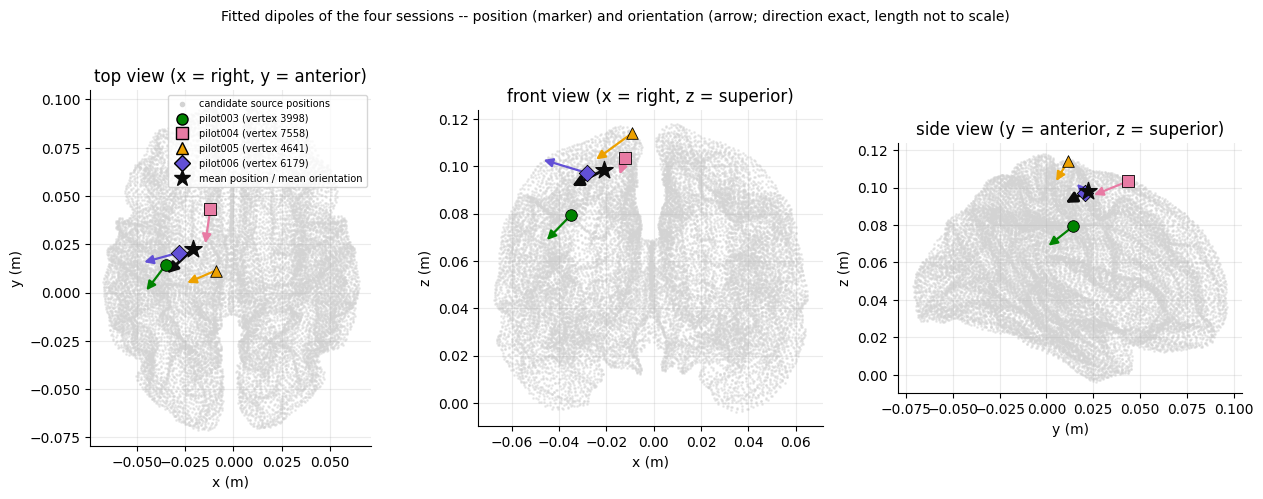

In [12]:
# ---------------------------------------------------------------- dipole positions + orientations, all four pilots
if source_rr is not None:
    arrow_len = 0.15 * np.ptp(source_rr, axis=0).mean()   # visibility only; orientations are unit vectors
    views = [("x", "y", "top view (x = right, y = anterior)"),
             ("x", "z", "front view (x = right, z = superior)"),
             ("y", "z", "side view (y = anterior, z = superior)")]
    axis_idx = {"x": 0, "y": 1, "z": 2}

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
    for ax, (h, v, title) in zip(axes, views):
        hi, vi = axis_idx[h], axis_idx[v]
        ax.scatter(source_rr[:, hi], source_rr[:, vi], s=1, color="lightgray", alpha=0.4)
        for p in PILOTS:
            P, O = dip_pos[p], dip_ori[p] * arrow_len
            ax.annotate("", xy=(P[hi] + O[hi], P[vi] + O[vi]), xytext=(P[hi], P[vi]),
                        arrowprops=dict(arrowstyle="-|>", color=PILOT_COLORS[p], lw=1.6, mutation_scale=13))
            ax.scatter(P[hi], P[vi], s=70, color=PILOT_COLORS[p], marker=PILOT_MARKERS[p],
                       edgecolor="black", linewidth=0.6, zorder=5)
        MO = mean_ori * arrow_len
        ax.annotate("", xy=(mean_pos[hi] + MO[hi], mean_pos[vi] + MO[vi]), xytext=(mean_pos[hi], mean_pos[vi]),
                    arrowprops=dict(arrowstyle="-|>", color=COLOR_MEAN, lw=2.2, mutation_scale=16))
        ax.scatter(mean_pos[hi], mean_pos[vi], s=170, color=COLOR_MEAN, marker="*", zorder=6)
        ax.set_xlabel(f"{h} (m)")
        ax.set_ylabel(f"{v} (m)")
        ax.set_title(title)
        ax.set_aspect("equal")
    handles = ([Line2D([], [], ls="none", marker=".", color="lightgray", label="candidate source positions")]
               + [Line2D([], [], ls="none", marker=PILOT_MARKERS[p], color=PILOT_COLORS[p], markeredgecolor="black",
                         markersize=8, label=f"{p} (vertex {int(dipole_info[p]['position_index'])})") for p in PILOTS]
               + [Line2D([], [], ls="none", marker="*", color=COLOR_MEAN, markersize=12,
                         label="mean position / mean orientation")])
    axes[0].legend(handles=handles, fontsize=7, loc="upper right")
    fig.suptitle("Fitted dipoles of the four sessions -- position (marker) and orientation (arrow; direction "
                 "exact, length not to scale)", y=1.03, fontsize=10)
    fig.tight_layout()
    plt.show()

## 4 · Processing info (`proc_info.npy`)

Written next to each calibration bundle: the channel layout and the time windows the online
pipeline uses, each at its own sampling rate. pilot006 is the first session run by the 5 kHz
decider: its post-stimulus and dipole windows are processed at 5 kHz (with the 500 Hz low-pass
after the first artifact blank), while pilot003–005 ran every window at 1 kHz. The pre-stimulus
window (QC gate and classifier input) is at 1 kHz in all four.

In [13]:
ch_lists = {p: tuple(proc_info[p]["ch_names"]) for p in PILOTS}
assert len(set(ch_lists.values())) == 1, "the channel lists differ between sessions"
CH_NAMES = list(ch_lists[PILOTS[0]])
print(f"channels ({len(CH_NAMES)}), identical in all four sessions: {', '.join(CH_NAMES)}\n")

rows = {}
for p in PILOTS:
    pi = proc_info[p]
    row = {}
    for k in ("pre", "post", "dipole"):
        sf = _window_sfreq(pi, k)
        row[f"{k} window (ms)"] = f"{pi[k]['tmin'] * 1000:.0f} to {pi[k]['tmax'] * 1000:.0f}"
        row[f"{k} rate (Hz)"] = f"{sf:.0f}"
        row[f"{k} samples"] = round((pi[k]["tmax"] - pi[k]["tmin"]) * sf) + 1
    row["calibration ICA rate (Hz)"] = f"{float(pi.get('ica_sfreq', _window_sfreq(pi, 'pre'))):.0f}"
    row["post 500 Hz low-pass"] = bool(pi.get("post_lowpass", False))
    rows[p] = row
display(pd.DataFrame(rows))
print(f"units: {proc_info[PILOTS[0]]['units']};  array layout: {proc_info[PILOTS[0]]['proc_shape']}")

channels (60), identical in all four sessions: AF3, AF4, AF7, AF8, C1, C2, C3, C4, C5, C6, CP1, CP2, CP3, CP4, CP5, CP6, CPz, Cz, F1, F2, F3, F4, F5, F6, F7, F8, FC1, FC2, FC3, FC4, FC5, FC6, FT7, FT8, Fp1, Fp2, Fpz, Fz, Iz, O1, O2, Oz, P1, P2, P3, P4, P5, P6, P7, P8, PO3, PO4, PO7, PO8, POz, Pz, T7, T8, TP7, TP8



,pilot003,pilot004,pilot005,pilot006
pre window (ms),-210 to -10,-210 to -10,-210 to -10,-210 to -10
pre rate (Hz),1000,1000,1000,1000
pre samples,201,201,201,201
post window (ms),1 to 100,1 to 100,1 to 100,1 to 100
post rate (Hz),1000,1000,1000,5000
post samples,100,100,100,496
dipole window (ms),38 to 50,38 to 50,38 to 50,38 to 50
dipole rate (Hz),1000,1000,1000,5000
dipole samples,13,13,13,61
calibration ICA rate (Hz),1000,1000,1000,1000


units: as received from the acquisition stream (microvolt-scale, uncalibrated);  array layout: ('n_channels', 'n_times')


## 5 · `prime_predictions.csv`

One row per **prediction attempt**, written by `process_periodic` every time the rolling QC gate
passes during the search phase of a PRIME-guided trial; a trial ends in one `triggered=True` row
(a threshold crossing, or a forced trigger at 5.5 s with `probability` = `NaN`). The file only
contains `prime_triplet` and `prime_single_pulse` trials — predetermined and calibration trials
never enter the search loop.

In [14]:
predictions_log = {p: pd.read_csv(SESSION_DIRS[p] / "prime_predictions.csv") for p in PILOTS}
tab = pd.DataFrame({p: {"prediction attempts": len(df), "blocks": df.stage.nunique(),
                        "forced attempts (probability NaN)": int(df.forced.sum())}
                    for p, df in predictions_log.items()})
display(with_mean(tab).round(1))
print("conditions present: " + "; ".join(f"{p} {sorted(df.condition.unique())}" for p, df in predictions_log.items()))

,pilot003,pilot004,pilot005,pilot006,mean
prediction attempts,47975,48000,47949,37066,45247.5
blocks,4,4,4,4,4.0
forced attempts (probability NaN),50,78,23,18,42.2


conditions present: pilot003 ['prime_single_pulse', 'prime_triplet']; pilot004 ['prime_single_pulse', 'prime_triplet']; pilot005 ['prime_single_pulse', 'prime_triplet']; pilot006 ['prime_single_pulse', 'prime_triplet']


### 5.1 · Development of PRIME's predicted probability across blocks

In [15]:
# ---------------------------------------------------------------- per-block summary
attempts = {}
for p, df in predictions_log.items():
    a = df.dropna(subset=["probability"]).copy()
    a["stage"] = pd.Categorical(a.stage, categories=BLOCK_NAMES, ordered=True)
    attempts[p] = a

def _per_block_stats(frames, only_triggered=False):
    out = []
    for p, a in frames.items():
        d = a[a.triggered] if only_triggered else a
        s = d.groupby(["stage", "condition"], observed=True).probability.agg(
            n="count", mean="mean", median="median", std="std")
        out.append(s.reset_index().assign(pilot=p))
    return pd.concat(out, ignore_index=True)

all_stats = _per_block_stats(attempts)
print("Predicted probability, every QC-passing attempt, per block and condition -- mean over pilots of "
      "each pilot's statistic:")
display(all_stats.groupby(["stage", "condition"], observed=True)[["n", "mean", "median", "std"]].mean().round(3))
print("\nmean probability per pilot:")
display(all_stats.pivot_table(index=["stage", "condition"], columns="pilot", values="mean", observed=True).round(3))

trig_stats = _per_block_stats(attempts, only_triggered=True)
print("\nPredicted probability of the triggering attempt only -- mean over pilots:")
display(trig_stats.groupby(["stage", "condition"], observed=True)[["n", "mean", "median"]].mean().round(3))

Predicted probability, every QC-passing attempt, per block and condition -- mean over pilots of each pilot's statistic:


n   mean  median    std
stage                condition                                        
intervention_block_1 prime_single_pulse  3412.00  0.552   0.554  0.103
                     prime_triplet       8049.75  0.548   0.550  0.103
intervention_block_2 prime_single_pulse  3796.50  0.452   0.451  0.085
                     prime_triplet       7405.50  0.451   0.449  0.084
intervention_block_3 prime_single_pulse  3590.25  0.407   0.404  0.083
                     prime_triplet       7459.00  0.409   0.406  0.084
intervention_block_4 prime_single_pulse  3747.25  0.361   0.355  0.087
                     prime_triplet       7745.00  0.360   0.355  0.086


mean probability per pilot:


pilot                                    pilot003  pilot004  pilot005  pilot006
stage                condition                                                 
intervention_block_1 prime_single_pulse     0.565     0.563     0.549     0.532
                     prime_triplet          0.562     0.561     0.550     0.521
intervention_block_2 prime_single_pulse     0.480     0.453     0.452     0.425
                     prime_triplet          0.482     0.457     0.444     0.422
intervention_block_3 prime_single_pulse     0.424     0.403     0.400     0.402
                     prime_triplet          0.430     0.405     0.398     0.402
intervention_block_4 prime_single_pulse     0.361     0.351     0.354     0.378
                     prime_triplet          0.365     0.356     0.350     0.371


Predicted probability of the triggering attempt only -- mean over pilots:


n   mean  median
stage                condition                                
intervention_block_1 prime_single_pulse   57.50  0.781   0.785
                     prime_triplet       112.75  0.779   0.782
intervention_block_2 prime_single_pulse   57.00  0.666   0.663
                     prime_triplet       114.25  0.667   0.661
intervention_block_3 prime_single_pulse   55.25  0.633   0.625
                     prime_triplet       112.00  0.633   0.625
intervention_block_4 prime_single_pulse   57.00  0.607   0.594
                     prime_triplet       113.00  0.606   0.594

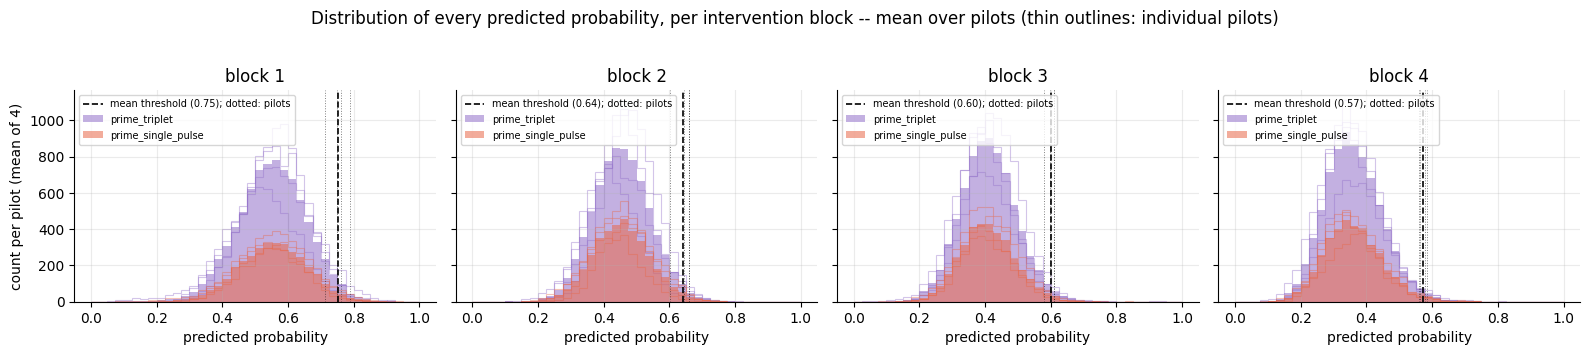

mean threshold over each block's attempts:


,pilot003,pilot004,pilot005,pilot006,mean
intervention_block_1,0.762,0.750,0.788,0.712,0.753
intervention_block_2,0.660,0.645,0.660,0.600,0.641
intervention_block_3,0.611,0.597,0.610,0.581,0.600
intervention_block_4,0.559,0.562,0.585,0.578,0.571


In [16]:
# ---------------------------------------------------------------- per-block histograms
fig, axes = plt.subplots(1, len(BLOCK_NAMES), figsize=(4 * len(BLOCK_NAMES), 3.4), sharey=True)
bins = np.linspace(0, 1, 41)
thresholds = {}
for ax, blk in zip(axes, BLOCK_NAMES):
    for cond, color in [("prime_triplet", COLOR_PRIME_TRIPLET), ("prime_single_pulse", COLOR_PRIME_SINGLE)]:
        vals = {p: attempts[p].loc[(attempts[p].stage == blk) & (attempts[p].condition == cond), "probability"]
                for p in PILOTS}
        plot_mean_hist(ax, vals, bins, color, label=cond, outline=color)
    thresholds[blk] = {p: attempts[p].loc[attempts[p].stage == blk, "threshold"].mean() for p in PILOTS}
    for p in PILOTS:
        ax.axvline(thresholds[blk][p], color="k", ls=":", lw=0.7, alpha=0.5)
    m = np.mean(list(thresholds[blk].values()))
    ax.axvline(m, color="k", ls="--", lw=1.2, label=f"mean threshold ({m:.2f}); dotted: pilots")
    ax.set_title(blk.replace("intervention_block_", "block "))
    ax.set_xlabel("predicted probability")
    ax.legend(fontsize=7, loc="upper left")
axes[0].set_ylabel("count per pilot (mean of 4)")
fig.suptitle("Distribution of every predicted probability, per intervention block -- mean over pilots "
             "(thin outlines: individual pilots)", y=1.03)
fig.tight_layout()
plt.show()

print("mean threshold over each block's attempts:")
display(with_mean(pd.DataFrame(thresholds).T).round(3))

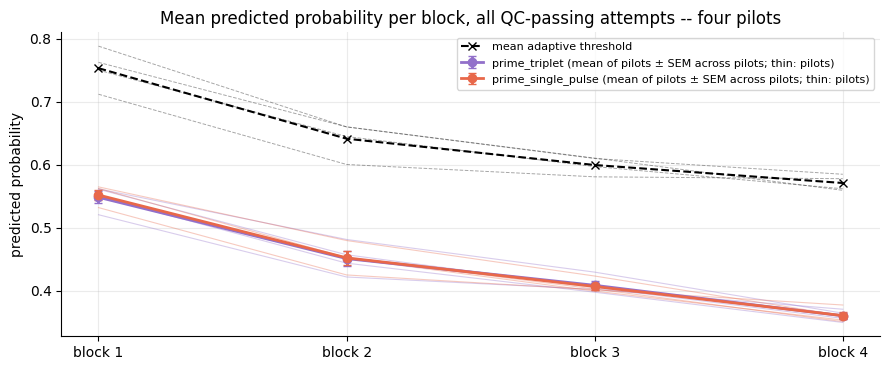

prime_triplet: mean probability per block


,pilot003,pilot004,pilot005,pilot006,mean
stage,,,,,
intervention_block_1,0.562,0.561,0.550,0.521,0.548
intervention_block_2,0.482,0.457,0.444,0.422,0.451
intervention_block_3,0.430,0.405,0.398,0.402,0.409
intervention_block_4,0.365,0.356,0.350,0.371,0.360


prime_single_pulse: mean probability per block


,pilot003,pilot004,pilot005,pilot006,mean
stage,,,,,
intervention_block_1,0.565,0.563,0.549,0.532,0.552
intervention_block_2,0.480,0.453,0.452,0.425,0.452
intervention_block_3,0.424,0.403,0.400,0.402,0.407
intervention_block_4,0.361,0.351,0.354,0.378,0.361


In [17]:
# ---------------------------------------------------------------- trend across the session
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(BLOCK_NAMES))
block_means = {}
for cond, color in [("prime_triplet", COLOR_PRIME_TRIPLET), ("prime_single_pulse", COLOR_PRIME_SINGLE)]:
    M_ = pd.DataFrame({p: attempts[p][attempts[p].condition == cond].groupby("stage", observed=True)
                       .probability.mean().reindex(BLOCK_NAMES) for p in PILOTS})
    block_means[cond] = M_
    for p in PILOTS:
        ax.plot(x, M_[p], color=color, lw=0.8, alpha=0.35)
    ax.errorbar(x, M_.mean(axis=1), yerr=M_.sem(axis=1), marker="o", color=color, capsize=3, lw=2,
                label=f"{cond} (mean of pilots ± SEM across pilots; thin: pilots)")
T = pd.DataFrame({p: attempts[p].groupby("stage", observed=True).threshold.mean().reindex(BLOCK_NAMES) for p in PILOTS})
for p in PILOTS:
    ax.plot(x, T[p], color="k", lw=0.7, ls="--", alpha=0.35)
ax.plot(x, T.mean(axis=1), color="k", ls="--", marker="x", label="mean adaptive threshold")
ax.set_xticks(x)
ax.set_xticklabels(BLOCK_TICKLABELS)
ax.set_ylabel("predicted probability")
ax.set_title("Mean predicted probability per block, all QC-passing attempts -- four pilots")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for cond, M_ in block_means.items():
    print(f"{cond}: mean probability per block")
    display(with_mean(M_).round(3))

### 5.2 · Predictions on the predetermined singles

`prime_predictions.csv` has no rows for `predetermined_single` trials, but `2_intervention.py`
runs the classifier retrospectively on them right after the pulse and stores the result in the
`prediction_probability` column of `trials_intervention.csv` — only if the trial's post-stimulus
processing succeeded and its pre-stimulus window preprocessed cleanly. `tep_amplitude` only needs
the post-stimulus processing to succeed, so it is available for a few more trials.

In [18]:
ti_raw = {p: pd.read_csv(SESSION_DIRS[p] / "trials_intervention.csv") for p in PILOTS}
predet = {p: df[df.condition == "predetermined_single"].copy() for p, df in ti_raw.items()}

rows = {}
for p, d in predet.items():
    n_total, n_post = len(d), int(d.postprocessing_failed.sum())
    n_pre, n_pred = int(d.preprocessing_failed.sum()), int(d.prediction_probability.notna().sum())
    assert n_pred == n_total - n_post - n_pre, f"{p}: retrospective predictions do not reconcile"
    rows[p] = {"delivered": n_total, "lost to postprocessing_failed": n_post,
               "then lost to preprocessing_failed": n_pre, "with a retrospective prediction_probability": n_pred,
               "with a tep_amplitude": int(d.tep_amplitude.notna().sum())}
display(with_mean(pd.DataFrame(rows)).round(2))

pred_predet = {p: d.prediction_probability.dropna() for p, d in predet.items()}
amp_predet = {p: d.tep_amplitude.dropna() for p, d in predet.items()}
print("descriptive statistics, retrospective prediction_probability on predetermined singles:")
display(describe_mean(pred_predet).round(3))

,pilot003,pilot004,pilot005,pilot006,mean
delivered,80,80,80,80,80.0
lost to postprocessing_failed,10,7,6,3,6.5
then lost to preprocessing_failed,6,3,0,3,3.0
with a retrospective prediction_probability,64,70,74,74,70.5
with a tep_amplitude,70,73,74,77,73.5


descriptive statistics, retrospective prediction_probability on predetermined singles:


,pilot003,pilot004,pilot005,pilot006,mean
count,64.000,70.000,74.000,74.000,70.500
mean,0.478,0.440,0.471,0.440,0.457
std,0.126,0.113,0.134,0.122,0.124
min,0.181,0.166,0.195,0.242,0.196
25%,0.396,0.361,0.359,0.351,0.367
50%,0.466,0.442,0.471,0.424,0.451
75%,0.573,0.520,0.567,0.493,0.538
max,0.787,0.805,0.798,0.816,0.801


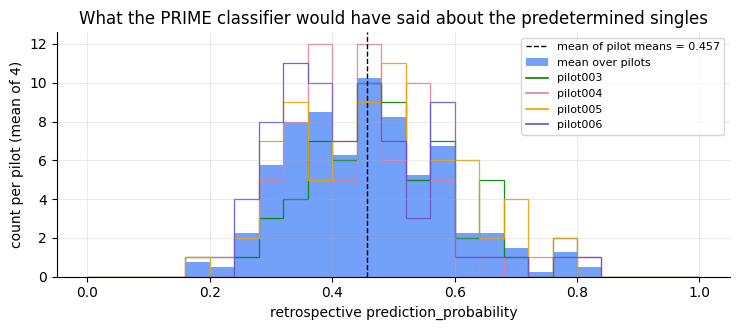

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
bins = np.linspace(0, 1, 26)
plot_mean_hist(ax, pred_predet, bins, COLOR_PREDETERMINED, label="mean over pilots", alpha=0.85)
m = np.mean([s.mean() for s in pred_predet.values()])
ax.axvline(m, color="k", ls="--", lw=1, label=f"mean of pilot means = {m:.3f}")
ax.set_xlabel("retrospective prediction_probability")
ax.set_ylabel("count per pilot (mean of 4)")
ax.set_title("What the PRIME classifier would have said about the predetermined singles")
h, l = ax.get_legend_handles_labels()
ax.legend(handles=h + pilot_line_handles(), fontsize=8)
fig.tight_layout()
plt.show()

descriptive statistics, actual tep_amplitude on predetermined singles:


,pilot003,pilot004,pilot005,pilot006,mean
count,70.000,73.000,74.000,77.000,73.500
mean,0.444,0.389,0.434,0.423,0.422
std,0.287,0.309,0.319,0.290,0.301
min,0.000,0.011,0.000,0.000,0.003
25%,0.232,0.125,0.110,0.244,0.178
50%,0.434,0.284,0.488,0.378,0.396
75%,0.593,0.659,0.707,0.622,0.646
max,1.000,0.977,0.988,1.000,0.991


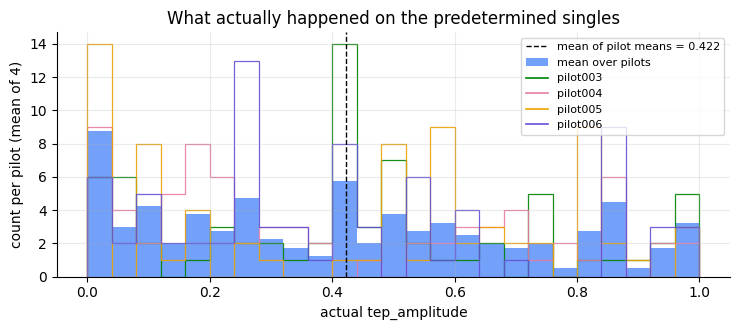

In [20]:
print("descriptive statistics, actual tep_amplitude on predetermined singles:")
display(describe_mean(amp_predet).round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_mean_hist(ax, amp_predet, np.linspace(0, 1, 26), COLOR_PREDETERMINED, label="mean over pilots", alpha=0.85)
m = np.mean([s.mean() for s in amp_predet.values()])
ax.axvline(m, color="k", ls="--", lw=1, label=f"mean of pilot means = {m:.3f}")
ax.set_xlabel("actual tep_amplitude")
ax.set_ylabel("count per pilot (mean of 4)")
ax.set_title("What actually happened on the predetermined singles")
h, l = ax.get_legend_handles_labels()
ax.legend(handles=h + pilot_line_handles(), fontsize=8)
fig.tight_layout()
plt.show()

## 6 · Inter-trial intervals (ITI)

Every **predetermined** trial (baseline, evaluation, and the intervention blocks'
`predetermined_single` condition) draws its ITI from `util/iti.py`'s `sample_iti`: a scaled Beta
distribution on [2.5, 5.5] s plus a 2% point mass at 5.5 s, solved for a mixture mean of 3.15 s.
The decider commits that ran all four sessions used these values (the current `util/iti.py` has
since moved the mean to 3.0 s). **PRIME-triggered trials have no drawn ITI**; their interval is
the empirical gap between consecutive pulses within the same intervention block.

In [21]:
# ---------------------------------------------------------------- load the ITI sources
trials_baseline, trials_evaluation = {}, {}
for p in PILOTS:
    trials_baseline[p] = pd.read_csv(SESSION_DIRS[p] / "trials_baseline.csv")
    files = sorted(SESSION_DIRS[p].glob("trials_evaluation_*.csv"), key=lambda f: int(f.stem.rsplit("_", 1)[1]))
    trials_evaluation[p] = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

prime_triggered_iti = {}
for p, df in ti_raw.items():
    iv = df[df.stage.str.startswith("intervention_block")].sort_values(["stage", "trial_in_stage"]).copy()
    iv["empirical_iti"] = iv.groupby("stage")["pulse_time"].diff()     # within each block only
    prime_triggered_iti[p] = iv.loc[iv.condition.isin(["prime_triplet", "prime_single_pulse"]),
                                    "empirical_iti"].dropna()

display(pd.DataFrame({p: {"trials_baseline.csv": len(trials_baseline[p]),
                          "trials_evaluation_*.csv": len(trials_evaluation[p]),
                          "evaluation runs": trials_evaluation[p].run_index.nunique(),
                          "predetermined_single (intervention)": len(predet[p]),
                          "PRIME-triggered with an empirical ITI": len(prime_triggered_iti[p])} for p in PILOTS}))

,pilot003,pilot004,pilot005,pilot006
trials_baseline.csv,100,100,100,100
trials_evaluation_*.csv,400,400,400,400
evaluation runs,4,4,4,4
predetermined_single (intervention),80,80,80,80
PRIME-triggered with an empirical ITI,716,717,717,716


### 6.1 · Predetermined ITI — baseline, evaluation, and intervention predetermined singles

`3_evaluation.py` seeds its random generator with `np.random.default_rng(SEED + subject_id)` each
time an evaluation run starts. So the cell also checks whether a session's four evaluation runs
drew fresh ITIs or repeated one sequence, and which sessions share a sequence.

descriptive statistics, drawn ITI (s), by source -- mean over pilots of each pilot's statistic:


,baseline,evaluation (all runs),"intervention, predetermined_single"
count,100.000,400.000,80.000
mean,3.138,3.200,3.174
std,0.571,0.655,0.586
min,2.507,2.500,2.504
25%,2.713,2.734,2.748
50%,2.982,3.061,3.079
75%,3.463,3.437,3.411
max,5.119,5.500,5.500


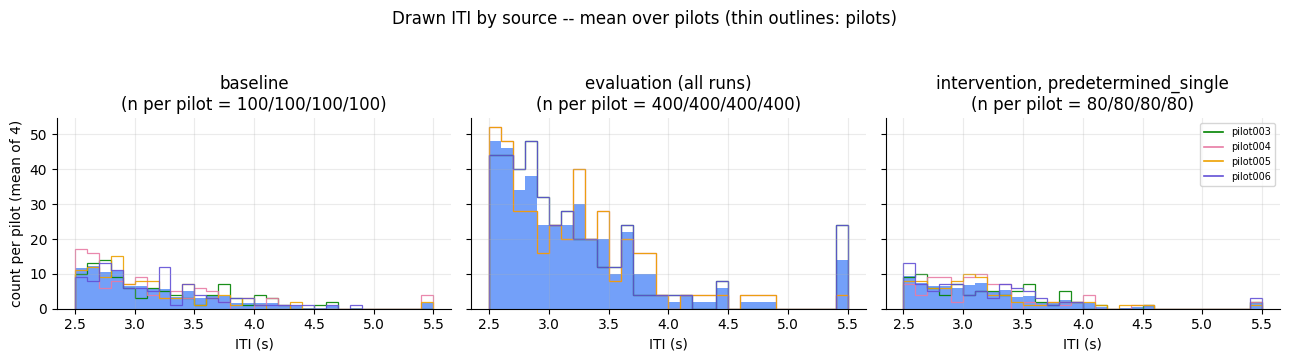

,pilot003,pilot004,pilot005,pilot006
evaluation runs 2-4 repeat run 1's ITIs,True,True,True,True
same evaluation sequence as,pilot006,pilot005,pilot004,pilot003
same baseline sequence as,-,-,-,-


In [22]:
iti_by_source = {
    "baseline": {p: trials_baseline[p].iti for p in PILOTS},
    "evaluation (all runs)": {p: trials_evaluation[p].iti for p in PILOTS},
    "intervention, predetermined_single": {p: predet[p].iti for p in PILOTS},
}
desc = pd.DataFrame({src: describe_mean(by_p)["mean"] for src, by_p in iti_by_source.items()})
print("descriptive statistics, drawn ITI (s), by source -- mean over pilots of each pilot's statistic:")
display(desc.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True, sharex=True)
bins = np.linspace(2.5, 5.5, 31)
for ax, (src, by_p) in zip(axes, iti_by_source.items()):
    plot_mean_hist(ax, by_p, bins, COLOR_PREDETERMINED, alpha=0.85)
    n = "/".join(str(int(pd.Series(s).notna().sum())) for s in by_p.values())
    ax.set_title(f"{src}\n(n per pilot = {n})")
    ax.set_xlabel("ITI (s)")
axes[0].set_ylabel("count per pilot (mean of 4)")
axes[-1].legend(handles=pilot_line_handles(), fontsize=7)
fig.suptitle("Drawn ITI by source -- mean over pilots (thin outlines: pilots)", y=1.05)
fig.tight_layout()
plt.show()

# Fresh draws, or one sequence repeated? Compare every evaluation run with run 1, and run 1 across sessions.
first_run = {}
rows = {}
for p in PILOTS:
    runs = [g.iti.to_numpy() for _, g in trials_evaluation[p].groupby("run_index")]
    first_run[p] = runs[0]
    rows[p] = {"evaluation runs 2-4 repeat run 1's ITIs": all(len(r) == len(runs[0]) and np.allclose(r, runs[0])
                                                               for r in runs[1:])}
_same = lambda a, b: len(a) == len(b) and np.allclose(a, b)
for p in PILOTS:
    rows[p]["same evaluation sequence as"] = ", ".join(q for q in PILOTS if q != p and _same(first_run[q], first_run[p])) or "-"
    rows[p]["same baseline sequence as"] = ", ".join(
        q for q in PILOTS if q != p and _same(trials_baseline[q].iti.to_numpy(), trials_baseline[p].iti.to_numpy())) or "-"
display(pd.DataFrame(rows))

### 6.1.1 · Empirical ITI of PRIME-triggered trials

descriptive statistics, empirical inter-pulse interval (s) ending in a PRIME-triggered pulse:


,pilot003,pilot004,pilot005,pilot006,mean
count,716.000,717.000,717.000,716.000,716.500
mean,3.382,3.513,3.216,3.098,3.302
std,0.889,0.979,0.790,0.680,0.834
min,2.500,2.500,2.500,2.500,2.500
25%,2.680,2.710,2.610,2.620,2.655
50%,3.080,3.160,2.900,2.850,2.998
75%,3.723,4.060,3.570,3.310,3.666
max,5.501,5.501,5.500,5.501,5.501


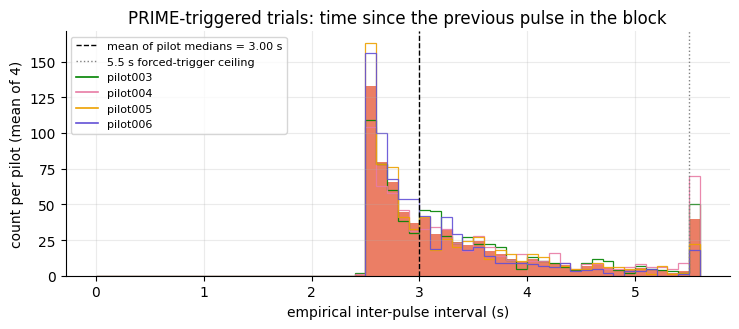

In [23]:
print("descriptive statistics, empirical inter-pulse interval (s) ending in a PRIME-triggered pulse:")
display(describe_mean(prime_triggered_iti).round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_mean_hist(ax, prime_triggered_iti, np.linspace(0, 5.6, 57), COLOR_PRIME_SINGLE, alpha=0.85)
med = np.mean([s.median() for s in prime_triggered_iti.values()])
ax.axvline(med, color="k", ls="--", lw=1, label=f"mean of pilot medians = {med:.2f} s")
ax.axvline(5.5, color="grey", ls=":", lw=1, label="5.5 s forced-trigger ceiling")
ax.set_xlabel("empirical inter-pulse interval (s)")
ax.set_ylabel("count per pilot (mean of 4)")
ax.set_title("PRIME-triggered trials: time since the previous pulse in the block")
h, l = ax.get_legend_handles_labels()
ax.legend(handles=h + pilot_line_handles(), fontsize=8)
fig.tight_layout()
plt.show()

### 6.2 · Overlay: predetermined (drawn) vs. PRIME-triggered (empirical) ITI

Each pilot's predetermined sources are pooled (one generative distribution, section 6.1) and
turned into a density; the bars are the mean of the four pilots' densities, for each kind of
interval. The dashed curve is the Beta component of `sample_iti` with the parameters that ran in
all four sessions. The test below is run within each pilot.

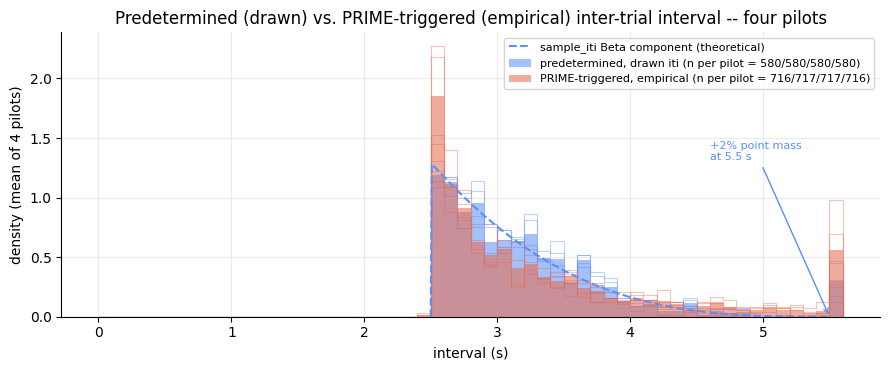

within each pilot (descriptive check that the two distributions differ; not a claim about why):


,pilot003,pilot004,pilot005,pilot006,mean
predetermined median (s),2.9916,3.0700,3.0652,2.9948,3.0304
PRIME-triggered median (s),3.0800,3.1600,2.9000,2.8500,2.9975
difference (s),0.0884,0.0900,-0.1652,-0.1448,-0.0329
Mann-Whitney p,0.0466,0.0003,0.0056,0.0000,NaN


In [24]:
# ---------------------------------------------------------------- util/iti.py's Beta, as run in pilot003-006
ITI_MIN, ITI_MAX = 2.5, 5.5
TARGET_MEAN, SPIKE_VALUE, SPIKE_WEIGHT, CONCENTRATION = 3.15, 5.5, 0.02, 5.0
_beta_mean = (TARGET_MEAN - SPIKE_WEIGHT * SPIKE_VALUE) / (1 - SPIKE_WEIGHT)
_p = (_beta_mean - ITI_MIN) / (ITI_MAX - ITI_MIN)
_alpha, _beta = _p * CONCENTRATION, (1 - _p) * CONCENTRATION
x = np.linspace(ITI_MIN, ITI_MAX, 400)
pdf_beta_component = ((1 - SPIKE_WEIGHT) * stats.beta.pdf((x - ITI_MIN) / (ITI_MAX - ITI_MIN), _alpha, _beta)
                      / (ITI_MAX - ITI_MIN))

predetermined_pooled = {p: pd.concat([trials_baseline[p].iti, trials_evaluation[p].iti, predet[p].iti],
                                     ignore_index=True).dropna() for p in PILOTS}

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0, 5.6, 57)
plot_mean_hist(ax, predetermined_pooled, bins, COLOR_PREDETERMINED, density=True, outline=COLOR_PREDETERMINED,
               label=f"predetermined, drawn iti (n per pilot = {'/'.join(str(len(s)) for s in predetermined_pooled.values())})")
plot_mean_hist(ax, prime_triggered_iti, bins, COLOR_PRIME_SINGLE, density=True, outline=COLOR_PRIME_SINGLE,
               label=f"PRIME-triggered, empirical (n per pilot = {'/'.join(str(len(s)) for s in prime_triggered_iti.values())})")
ax.plot(x, pdf_beta_component, color=COLOR_PREDETERMINED, ls="--", lw=1.5, label="sample_iti Beta component (theoretical)")
ax.annotate(f"+{SPIKE_WEIGHT:.0%} point mass\nat {SPIKE_VALUE} s", xy=(5.5, 0), xytext=(4.6, ax.get_ylim()[1] * 0.55),
            arrowprops=dict(arrowstyle="->", color=COLOR_PREDETERMINED), fontsize=8, color=COLOR_PREDETERMINED)
ax.set_xlabel("interval (s)")
ax.set_ylabel("density (mean of 4 pilots)")
ax.set_title("Predetermined (drawn) vs. PRIME-triggered (empirical) inter-trial interval -- four pilots")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

rows = {}
for p in PILOTS:
    a, b = predetermined_pooled[p], prime_triggered_iti[p]
    rows[p] = {"predetermined median (s)": a.median(), "PRIME-triggered median (s)": b.median(),
               "difference (s)": b.median() - a.median(), "Mann-Whitney p": stats.mannwhitneyu(a, b).pvalue}
tab = with_mean(pd.DataFrame(rows))
tab.loc["Mann-Whitney p", "mean"] = np.nan   # a mean of p-values is not meaningful
print("within each pilot (descriptive check that the two distributions differ; not a claim about why):")
display(tab.round(4))

## 7 · Latency profiles (`profile_*.csv`)

One wall-clock latency (ms) per call of the named function, recorded during the session and
written at teardown (see the single-session notebook for what each file measures). pilot006 ran the
post-stimulus chain at 5 kHz, so its `process_pulse` latencies are not quite the same quantity as
in pilot003–005. The histograms use shared bins over the range of all four sessions.

In [25]:
profiles = {p: {f.stem.replace("profile_", ""): pd.read_csv(f)["duration_ms"]
                for f in sorted(SESSION_DIRS[p].glob("profile_*.csv"))} for p in PILOTS}
PROFILE_NAMES = sorted(set.intersection(*(set(v) for v in profiles.values())))
desc = pd.DataFrame({name: describe_mean({p: profiles[p][name] for p in PILOTS},
                                         percentiles=[.5, .95, .99])["mean"] for name in PROFILE_NAMES})
print("descriptive statistics, latency (ms), per profiled function -- mean over pilots of each pilot's statistic:")
display(desc.round(4))
print("\nmedian latency (ms) per pilot:")
display(pd.DataFrame({name: {p: profiles[p][name].median() for p in PILOTS} for name in PROFILE_NAMES}).round(4))

descriptive statistics, latency (ms), per profiled function -- mean over pilots of each pilot's statistic:


,check_qc,finetune,predict,preprocess_pre,process_pulse
count,58450.7500,289.5000,45205.2500,93822.0000,925.0000
mean,0.0021,25.2381,1.3599,1.5426,57.6148
std,0.0005,11.2522,0.3064,0.0720,17.6716
min,0.0010,0.5618,1.1673,1.2030,26.4482
50%,0.0020,30.6075,1.2810,1.5458,52.0670
95%,0.0030,31.7597,1.8594,1.6162,85.4385
99%,0.0040,33.6134,2.2657,1.7793,87.1589
max,0.0222,35.5557,32.6265,2.5212,205.9382



median latency (ms) per pilot:


,check_qc,finetune,predict,preprocess_pre,process_pulse
pilot003,0.002,30.873,1.299,1.572,51.076
pilot004,0.002,30.641,1.290,1.554,50.276
pilot005,0.002,30.486,1.269,1.530,50.080
pilot006,0.002,30.430,1.266,1.527,56.836


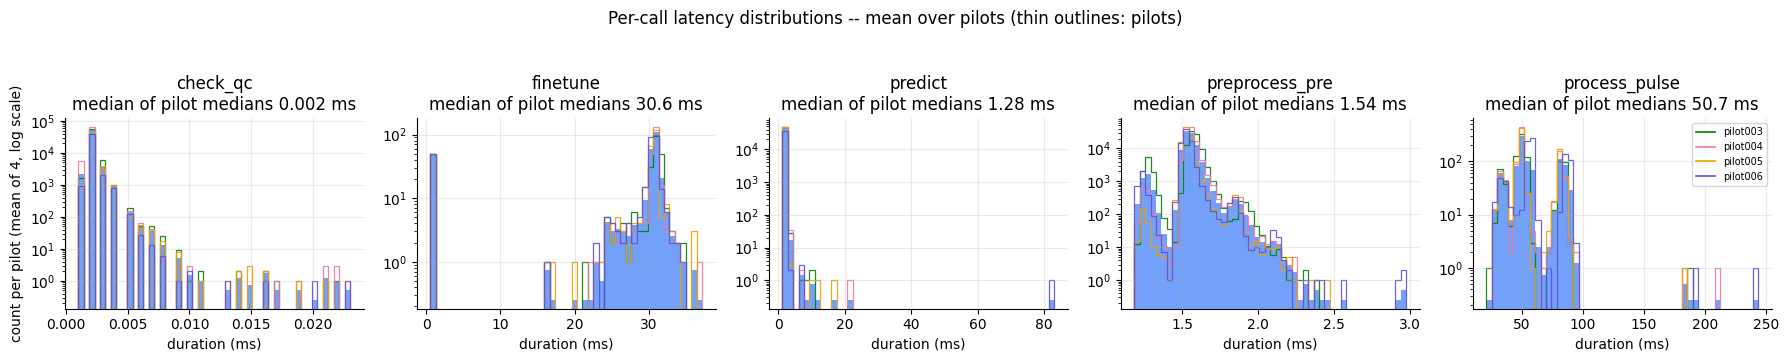

In [26]:
fig, axes = plt.subplots(1, len(PROFILE_NAMES), figsize=(3.6 * len(PROFILE_NAMES), 3.4))
for ax, name in zip(axes, PROFILE_NAMES):
    vals = {p: profiles[p][name] for p in PILOTS}
    bins = np.linspace(min(v.min() for v in vals.values()), max(v.max() for v in vals.values()), 51)
    plot_mean_hist(ax, vals, bins, "#5b8ff9", alpha=0.85)
    ax.set_yscale("log")
    ax.set_title(f"{name}\nmedian of pilot medians {np.median([v.median() for v in vals.values()]):.3g} ms")
    ax.set_xlabel("duration (ms)")
axes[0].set_ylabel("count per pilot (mean of 4, log scale)")
axes[-1].legend(handles=pilot_line_handles(), fontsize=7)
fig.suptitle("Per-call latency distributions -- mean over pilots (thin outlines: pilots)", y=1.05)
fig.tight_layout()
plt.show()

## 8 · `trials_intervention.csv` — per-trial breakdown

The rest of chapter 1 works from the 800 intervention-block rows of each session's
`trials_intervention.csv`. `trial_order` is the trial's position in the session (0–799, sorted by
block then `trial_in_stage`), identical in layout across sessions, which is what lets the trend
plots average the four pilots trial by trial. Vertical dotted lines mark the block boundaries.

In [27]:
IVS = {}
for p, df in ti_raw.items():
    iv = df[df.stage.str.startswith("intervention_block")].copy()
    iv = iv.sort_values(["stage", "trial_in_stage"]).reset_index(drop=True)
    iv["trial_order"] = np.arange(len(iv))
    iv["t_min"] = (iv.pulse_time - iv.pulse_time.min()) / 60
    iv["is_forced"] = iv.is_forced.astype(bool)
    assert len(iv) == 800 and list(iv.stage.unique()) == BLOCK_NAMES, f"{p}: unexpected intervention layout"
    assert list(iv.groupby("stage", sort=False).size().cumsum().values[:-1]) == BLOCK_EDGES
    IVS[p] = iv

CONDS = ["predetermined_single", "prime_single_pulse", "prime_triplet"]
COND_COLORS = [COLOR_PREDETERMINED, COLOR_PRIME_SINGLE, COLOR_PRIME_TRIPLET]
print("intervention trials per condition:")
display(with_mean(pd.DataFrame({p: iv.condition.value_counts() for p, iv in IVS.items()}).reindex(CONDS)))

intervention trials per condition:


,pilot003,pilot004,pilot005,pilot006,mean
condition,,,,,
predetermined_single,80,80,80,80,80.0
prime_single_pulse,240,240,240,240,240.0
prime_triplet,480,480,480,480,480.0


### 8.1 · `target_time` vs. `pulse_time`

`target_time` is when the pulse was supposed to fire (`trial_start_time + iti` for predetermined
trials, `trigger_time + 0.01 s` for a PRIME trial that crossed threshold); forced PRIME trials never
get one, so the difference is only defined for non-forced trials.

In [28]:
forced = pd.DataFrame({p: iv.groupby("condition").is_forced.sum() for p, iv in IVS.items()}).reindex(CONDS).astype(int)
forced.loc["total"] = forced.sum()
print("forced trials (excluded from this comparison):")
display(with_mean(forced).round(2))
pct = 100 * forced.loc["total"] / 720
print("forced, % of the 720 PRIME-guided trials: " + ", ".join(f"{p} {v:.1f}" for p, v in pct.items())
      + f"; mean {pct.mean():.1f}")

nonforced = {}
for p, iv in IVS.items():
    nf = iv[~iv.is_forced].copy()
    nf["target_pulse_diff_ms"] = (nf.pulse_time - nf.target_time) * 1000
    assert nf.target_time.notna().all()
    nonforced[p] = nf
desc = pd.concat({p: nf.groupby("condition").target_pulse_diff_ms.describe() for p, nf in nonforced.items()},
                 names=["pilot"])
print("\ntarget_time -> pulse_time difference (ms), non-forced trials, by condition -- mean over pilots of "
      "each pilot's statistic:")
display(desc.groupby(level="condition").mean().reindex(CONDS).round(3))

forced trials (excluded from this comparison):


,pilot003,pilot004,pilot005,pilot006,mean
condition,,,,,
predetermined_single,0,0,0,0,0.00
prime_single_pulse,18,21,9,5,13.25
prime_triplet,32,57,14,13,29.00
total,50,78,23,18,42.25


forced, % of the 720 PRIME-guided trials: pilot003 6.9, pilot004 10.8, pilot005 3.2, pilot006 2.5; mean 5.9

target_time -> pulse_time difference (ms), non-forced trials, by condition -- mean over pilots of each pilot's statistic:


,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
predetermined_single,80.00,0.042,0.203,-0.204,-0.047,0.0,0.074,1.173
prime_single_pulse,226.75,0.047,0.179,-0.200,0.000,0.0,0.050,1.100
prime_triplet,451.00,0.048,0.181,-0.200,0.000,0.0,0.000,1.350


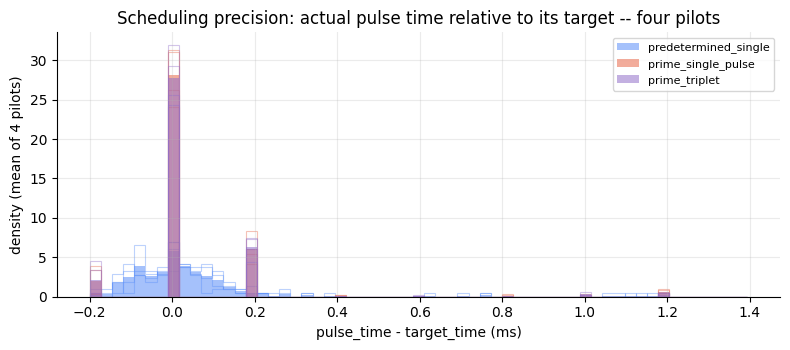

In [29]:
fig, ax = plt.subplots(figsize=(8, 3.6))
lo, hi = pd.concat([nf.target_pulse_diff_ms for nf in nonforced.values()]).quantile([0.001, 0.999])
bins = np.linspace(lo, hi, 60)
for cond, color in zip(CONDS, COND_COLORS):
    plot_mean_hist(ax, {p: nf.loc[nf.condition == cond, "target_pulse_diff_ms"] for p, nf in nonforced.items()},
                   bins, color, label=cond, density=True, outline=color)
ax.set_xlabel("pulse_time - target_time (ms)")
ax.set_ylabel("density (mean of 4 pilots)")
ax.set_title("Scheduling precision: actual pulse time relative to its target -- four pilots")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 8.2 · `preprocessing_failed`

Set when the trial's pre-stimulus window (used for finetuning and the retrospective prediction)
fails to preprocess. Only forced `prime_single_pulse` and `predetermined_single` trials attempt
this step; it is always `False` for `prime_triplet`.

In [30]:
n_failed = pd.DataFrame({p: iv.groupby("condition").preprocessing_failed.sum() for p, iv in IVS.items()}).reindex(CONDS)
rate = pd.DataFrame({p: 100 * iv.groupby("condition").preprocessing_failed.mean() for p, iv in IVS.items()}).reindex(CONDS)
print("n trials with preprocessing_failed:")
display(with_mean(n_failed).round(2))
print("rate (%):")
display(with_mean(rate).round(2))
overall = {p: 100 * iv.preprocessing_failed.mean() for p, iv in IVS.items()}
print("overall (% of 800): " + ", ".join(f"{p} {v:.2f}" for p, v in overall.items()) + f"; mean {np.mean(list(overall.values())):.2f}")

n trials with preprocessing_failed:


,pilot003,pilot004,pilot005,pilot006,mean
condition,,,,,
predetermined_single,6,3,0,3,3.00
prime_single_pulse,1,0,0,0,0.25
prime_triplet,0,0,0,0,0.00


rate (%):


,pilot003,pilot004,pilot005,pilot006,mean
condition,,,,,
predetermined_single,7.50,3.75,0.0,3.75,3.75
prime_single_pulse,0.42,0.00,0.0,0.00,0.10
prime_triplet,0.00,0.00,0.0,0.00,0.00


overall (% of 800): pilot003 0.88, pilot004 0.38, pilot005 0.00, pilot006 0.38; mean 0.41


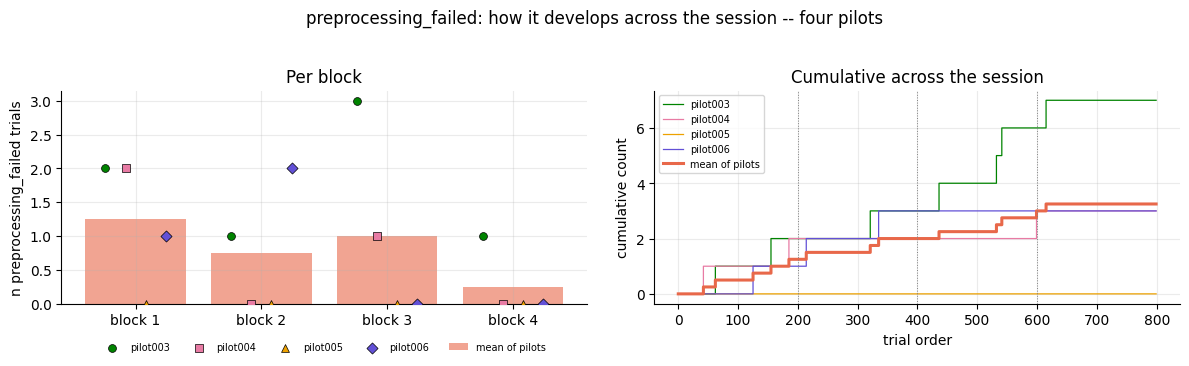

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
per_block = pd.DataFrame({p: iv.groupby("stage", sort=False).preprocessing_failed.sum() for p, iv in IVS.items()})
block_bars_with_pilots(axes[0], per_block, COLOR_PRIME_SINGLE, "n preprocessing_failed trials", "Per block")

cum = {p: iv.sort_values("trial_order").preprocessing_failed.cumsum().to_numpy() for p, iv in IVS.items()}
for p in PILOTS:
    axes[1].step(TRIAL_GRID, cum[p], where="post", color=PILOT_COLORS[p], lw=0.9, label=p)
axes[1].step(TRIAL_GRID, np.mean([cum[p] for p in PILOTS], axis=0), where="post", color=COLOR_PRIME_SINGLE,
             lw=2.2, label="mean of pilots")
for edge in BLOCK_EDGES:
    axes[1].axvline(edge, color="grey", lw=0.7, ls=":")
axes[1].set_xlabel("trial order")
axes[1].set_ylabel("cumulative count")
axes[1].set_title("Cumulative across the session")
axes[1].legend(fontsize=7)
fig.suptitle("preprocessing_failed: how it develops across the session -- four pilots", y=1.03)
fig.tight_layout()
plt.show()

### 8.3 · `postprocessing_failed` and `post_reject_reason`

Set when the post-stimulus window fails `Preprocessor.preprocess_post`'s cascade (first failure
wins): **ocular** (median z of an eye-blink component above the session's ocular z cutoff —
2.0 / 2.0 / 2.5 / 3.0 in pilot003 / 004 / 005 / 006), **global_mad** (whole-epoch MAD z above 6) and
**local_mad** (any channel's MAD z above 5). As in the single-session notebook, **triplet trials are
left out**: their window is dominated by the burst's 2nd and 3rd pulses.

In [32]:
IV_NT = {p: iv[~iv.condition.str.contains("triplet")] for p, iv in IVS.items()}
rate = pd.DataFrame({p: 100 * d.groupby("condition").postprocessing_failed.mean() for p, d in IV_NT.items()})
print("postprocessing_failed rate (%), single-pulse intervention trials:")
display(with_mean(rate).round(2))
overall = {p: 100 * d.postprocessing_failed.mean() for p, d in IV_NT.items()}
print("overall (% of 320 single pulses): " + ", ".join(f"{p} {v:.2f}" for p, v in overall.items())
      + f"; mean {np.mean(list(overall.values())):.2f}")

reason_counts = pd.DataFrame({p: d.post_reject_reason.value_counts() for p, d in IV_NT.items()}).fillna(0).astype(int)
reason_counts = reason_counts.loc[reason_counts.sum(axis=1).sort_values(ascending=False).index]
print("\nrejection reason, n trials:")
display(with_mean(reason_counts).round(2))

xt = pd.concat({p: pd.crosstab(d.condition, d.post_reject_reason.fillna("(kept)")) for p, d in IV_NT.items()},
               names=["pilot"]).fillna(0)
print("\nreason by condition -- mean n trials per pilot:")
display(xt.groupby(level="condition").mean().round(2))

postprocessing_failed rate (%), single-pulse intervention trials:


,pilot003,pilot004,pilot005,pilot006,mean
condition,,,,,
predetermined_single,12.50,8.75,7.50,3.75,8.12
prime_single_pulse,15.42,9.58,7.92,1.67,8.65


overall (% of 320 single pulses): pilot003 14.69, pilot004 9.38, pilot005 7.81, pilot006 2.19; mean 8.52

rejection reason, n trials:


,pilot003,pilot004,pilot005,pilot006,mean
post_reject_reason,,,,,
ocular,40,27,22,4,23.25
local_mad,4,1,2,3,2.50
global_mad,3,2,1,0,1.50



reason by condition -- mean n trials per pilot:


post_reject_reason,(kept),global_mad,local_mad,ocular
condition,,,,
predetermined_single,73.50,0.25,1.5,4.75
prime_single_pulse,219.25,1.25,1.0,18.50


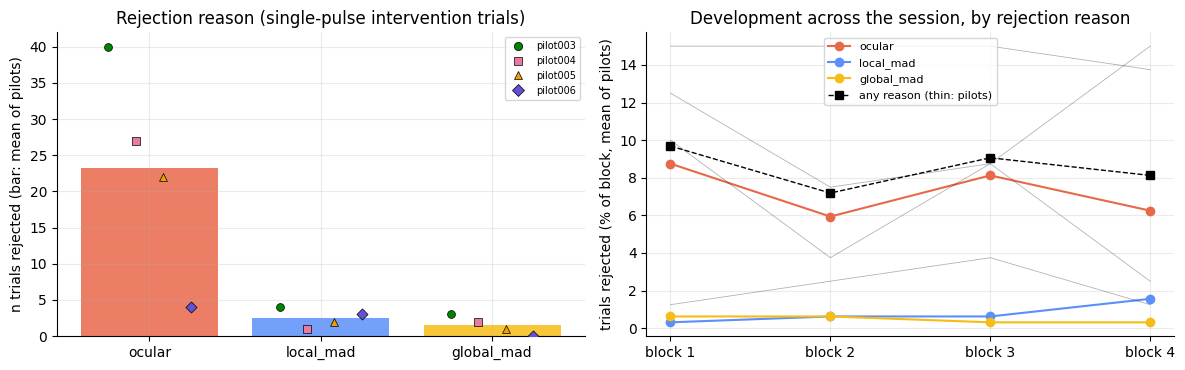

In [33]:
REASON_COLORS = {"ocular": "#e8684a", "global_mad": "#f6bd16", "local_mad": "#5b8ff9"}
reasons_present = list(reason_counts.index)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(reasons_present))
axes[0].bar(x, reason_counts.mean(axis=1), color=[REASON_COLORS.get(r, "grey") for r in reasons_present], alpha=0.85)
for off, p in zip(np.linspace(-0.24, 0.24, len(PILOTS)), PILOTS):
    axes[0].scatter(x + off, reason_counts[p], marker=PILOT_MARKERS[p], color=PILOT_COLORS[p],
                    edgecolor="black", linewidth=0.5, s=32, zorder=3)
axes[0].set_xticks(x)
axes[0].set_xticklabels(reasons_present)
axes[0].set_ylabel("n trials rejected (bar: mean of pilots)")
axes[0].set_title("Rejection reason (single-pulse intervention trials)")
axes[0].legend(handles=pilot_marker_handles(), fontsize=7)

per_block_by_reason = []
for p, d in IV_NT.items():
    n_per_block = d.groupby("stage", sort=False).size().reindex(BLOCK_NAMES)
    per_block_by_reason.append(pd.crosstab(d.stage, d.post_reject_reason)
                               .reindex(index=BLOCK_NAMES, columns=reasons_present).fillna(0)
                               .div(n_per_block, axis=0) * 100)
mean_by_reason = sum(per_block_by_reason) / len(per_block_by_reason)
total = pd.DataFrame({p: d.groupby("stage", sort=False).postprocessing_failed.mean().reindex(BLOCK_NAMES) * 100
                      for p, d in IV_NT.items()})
xb = np.arange(len(BLOCK_NAMES))
for reason in reasons_present:
    axes[1].plot(xb, mean_by_reason[reason], marker="o", color=REASON_COLORS.get(reason, "grey"), label=reason)
for p in PILOTS:
    axes[1].plot(xb, total[p], color="k", lw=0.6, alpha=0.3)
axes[1].plot(xb, total.mean(axis=1), marker="s", color="k", ls="--", lw=1, label="any reason (thin: pilots)")
axes[1].set_xticks(xb)
axes[1].set_xticklabels(BLOCK_TICKLABELS)
axes[1].set_ylabel("trials rejected (% of block, mean of pilots)")
axes[1].set_title("Development across the session, by rejection reason")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

### 8.4 · `qc_failures`

The number of rolling-window QC gate failures counted during the search for that trial (one per
10 ms tick that fails `check_qc()`). Only defined for PRIME-guided trials.

,pilot003,pilot004,pilot005,pilot006,mean
PRIME-guided trials,720.0,720.00,720.00,720.00,720.0
had >=1 qc failure,252.0,423.00,205.00,154.00,258.5
% with >=1,35.0,58.75,28.47,21.39,35.9


qc_failures, all PRIME-guided trials (0s included):


,pilot003,pilot004,pilot005,pilot006,mean
count,720.00,720.00,720.00,720.00,720.00
mean,22.42,35.41,6.15,9.21,18.30
std,50.93,55.27,18.20,22.98,36.84
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00
50%,0.00,8.00,0.00,0.00,2.00
75%,12.00,52.00,5.00,0.00,17.25
max,300.00,296.00,300.00,174.00,267.50


qc_failures, only trials where it happened (>0):


,pilot003,pilot004,pilot005,pilot006,mean
count,252.00,423.00,205.00,154.00,258.50
mean,64.06,60.26,21.59,43.06,47.24
std,68.94,60.85,28.85,31.84,47.62
min,1.00,1.00,1.00,2.00,1.25
25%,10.00,13.00,6.00,16.00,11.25
50%,40.00,40.00,12.00,38.00,32.50
75%,96.25,84.00,25.00,62.00,66.81
max,300.00,296.00,300.00,174.00,267.50


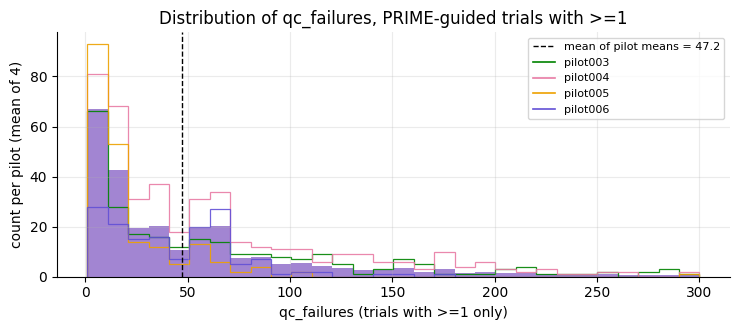

In [34]:
prime_guided = {p: iv[iv.condition.isin(["prime_triplet", "prime_single_pulse"])].copy() for p, iv in IVS.items()}
summ = pd.DataFrame({p: {"PRIME-guided trials": len(d), "had >=1 qc failure": int((d.qc_failures > 0).sum()),
                         "% with >=1": 100 * (d.qc_failures > 0).mean()} for p, d in prime_guided.items()})
display(with_mean(summ).round(2))
print("qc_failures, all PRIME-guided trials (0s included):")
display(describe_mean({p: d.qc_failures for p, d in prime_guided.items()}).round(2))
qc_pos = {p: d.loc[d.qc_failures > 0, "qc_failures"] for p, d in prime_guided.items()}
print("qc_failures, only trials where it happened (>0):")
display(describe_mean(qc_pos).round(2))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
bins = np.linspace(min(s.min() for s in qc_pos.values()), max(s.max() for s in qc_pos.values()), 31)
plot_mean_hist(ax, qc_pos, bins, COLOR_PRIME_TRIPLET, alpha=0.85)
m = np.mean([s.mean() for s in qc_pos.values()])
ax.axvline(m, color="k", ls="--", lw=1, label=f"mean of pilot means = {m:.1f}")
ax.set_xlabel("qc_failures (trials with >=1 only)")
ax.set_ylabel("count per pilot (mean of 4)")
ax.set_title("Distribution of qc_failures, PRIME-guided trials with >=1")
h, l = ax.get_legend_handles_labels()
ax.legend(handles=h + pilot_line_handles(), fontsize=8)
fig.tight_layout()
plt.show()

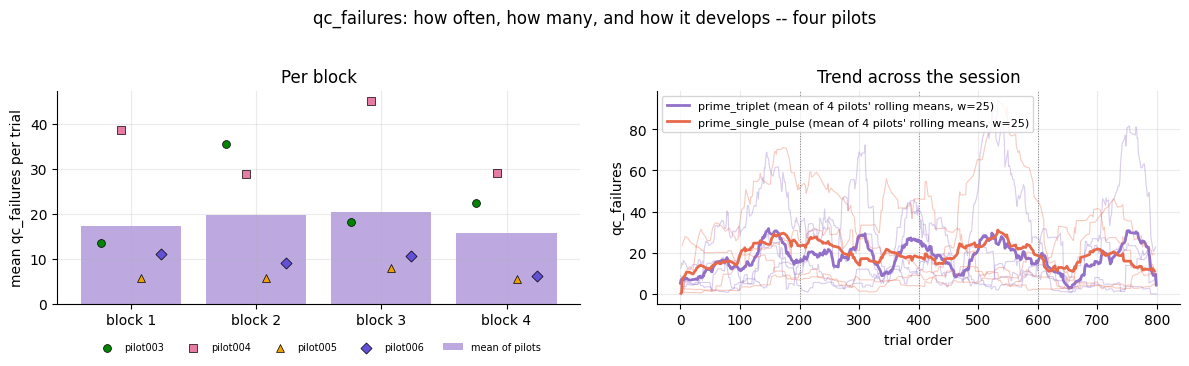

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
per_block = pd.DataFrame({p: d.groupby("stage", sort=False).qc_failures.mean() for p, d in prime_guided.items()})
block_bars_with_pilots(axes[0], per_block, COLOR_PRIME_TRIPLET, "mean qc_failures per trial", "Per block")
trend_plot_avg(axes[1], prime_guided, "qc_failures", ["prime_triplet", "prime_single_pulse"],
               [COLOR_PRIME_TRIPLET, COLOR_PRIME_SINGLE])
axes[1].set_title("Trend across the session")
fig.suptitle("qc_failures: how often, how many, and how it develops -- four pilots", y=1.03)
fig.tight_layout()
plt.show()

Does `qc_failures` predict whether a trial got forced? The single-session notebook draws one bar per
trial, in trial order. Trial order has no counterpart across sessions, so here each pilot's forced
(and not-forced) trials are sorted by `qc_failures`, largest first, and drawn against the fraction
of that pilot's trials. The filled area is the mean of the four sorted profiles. The same is done
for the search-time budget further down (sorted by `search_time`, as in the single-session plot).
The point-biserial correlation and the AUC (Mann-Whitney U / (n_forced × n_not_forced)) are
computed within each pilot.

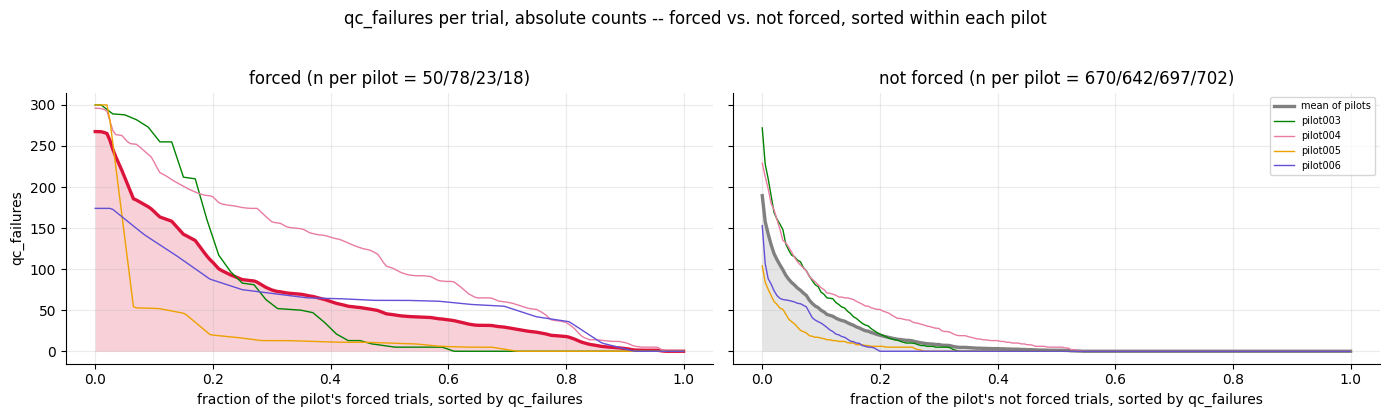

qc_failures by forced status -- mean over pilots of each pilot's statistic:


,forced,not_forced
count,42.25,677.75
mean,67.76,14.57
std,71.93,30.15
min,0.00,0.00
25%,24.12,0.00
50%,45.12,1.25
75%,86.50,13.19
max,267.50,189.50



within each pilot (mean r via Fisher's z; AUC 0.5 = chance, 1.0 = perfect separation):


,pilot003,pilot004,pilot005,pilot006,mean
n forced,50.0000,78.0000,23.0000,18.0000,42.250
n not forced,670.0000,642.0000,697.0000,702.0000,677.750
point-biserial r,0.2326,0.4988,0.1918,0.3925,0.335
p (r),0.0000,0.0000,0.0000,0.0000,NaN
AUC,0.6548,0.8525,0.7236,0.8930,0.781
p (Mann-Whitney),0.0000,0.0000,0.0000,0.0000,NaN


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, flag, color, name in [(axes[0], True, "crimson", "forced"), (axes[1], False, "grey", "not forced")]:
    profs = {p: sorted_profile(d.loc[d.is_forced == flag, "qc_failures"]) for p, d in prime_guided.items()}
    ns = "/".join(str(int((d.is_forced == flag).sum())) for d in prime_guided.values())
    mean_prof = np.nanmean(np.vstack(list(profs.values())), axis=0)
    ax.fill_between(FRACTION_GRID, 0, mean_prof, color=color, alpha=0.2, linewidth=0)
    ax.plot(FRACTION_GRID, mean_prof, color=color, lw=2.4, label="mean of pilots")
    for p, prof in profs.items():
        ax.plot(FRACTION_GRID, prof, color=PILOT_COLORS[p], lw=1.0, label=p)
    ax.set_title(f"{name} (n per pilot = {ns})")
    ax.set_xlabel(f"fraction of the pilot's {name} trials, sorted by qc_failures")
axes[0].set_ylabel("qc_failures")
axes[1].legend(fontsize=7)
fig.suptitle("qc_failures per trial, absolute counts -- forced vs. not forced, sorted within each pilot", y=1.03)
fig.tight_layout()
plt.show()

print("qc_failures by forced status -- mean over pilots of each pilot's statistic:")
display(pd.DataFrame({
    "forced": describe_mean({p: d.loc[d.is_forced, "qc_failures"] for p, d in prime_guided.items()})["mean"],
    "not_forced": describe_mean({p: d.loc[~d.is_forced, "qc_failures"] for p, d in prime_guided.items()})["mean"],
}).round(2))

rows = {}
for p, d in prime_guided.items():
    f, nf = d.loc[d.is_forced, "qc_failures"], d.loc[~d.is_forced, "qc_failures"]
    r_pb, p_pb = stats.pointbiserialr(d.is_forced.astype(int), d.qc_failures)
    u_stat, p_u = stats.mannwhitneyu(f, nf, alternative="two-sided")
    rows[p] = {"n forced": len(f), "n not forced": len(nf), "point-biserial r": r_pb, "p (r)": p_pb,
               "AUC": u_stat / (len(f) * len(nf)), "p (Mann-Whitney)": p_u}
qc_forced_tab = pd.DataFrame(rows)
qc_forced_tab["mean"] = qc_forced_tab.mean(axis=1)
qc_forced_tab.loc["point-biserial r", "mean"] = mean_r(qc_forced_tab.loc["point-biserial r", PILOTS])
qc_forced_tab.loc[["p (r)", "p (Mann-Whitney)"], "mean"] = np.nan
print("\nwithin each pilot (mean r via Fisher's z; AUC 0.5 = chance, 1.0 = perfect separation):")
display(qc_forced_tab.round(4))

search_time budget (s), mean / median, forced vs. not forced -- mean over pilots:


search_time        qc_fail_time        active_search_time       
                 mean median         mean median               mean median
is_forced                                                                 
False           0.677  0.455        0.146  0.012              0.532  0.319
True            3.010  3.010        0.678  0.451              2.332  2.559

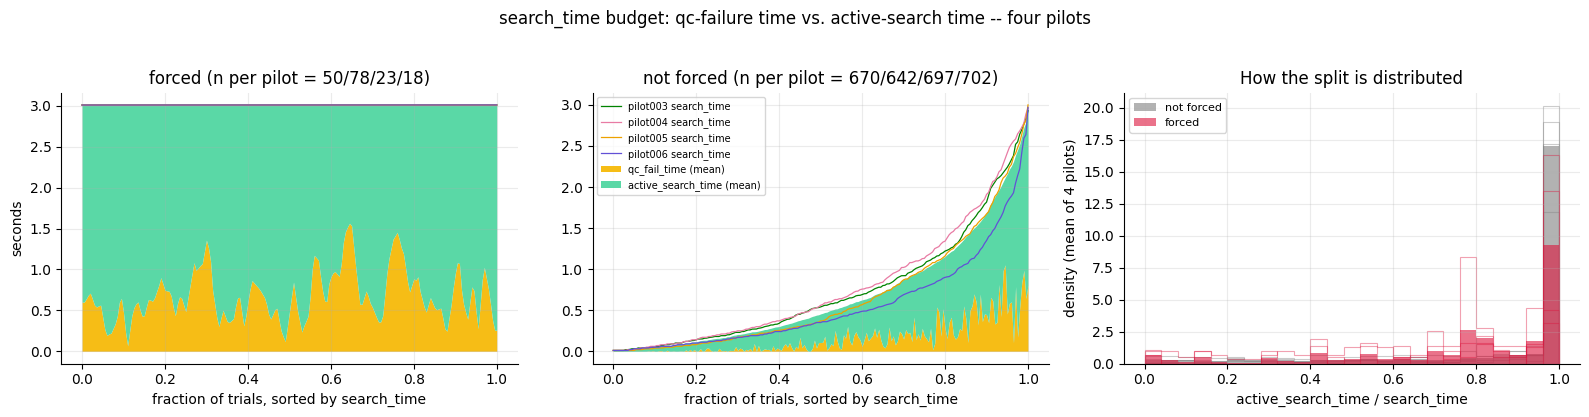

In [37]:
# In seconds rather than counts: process_periodic ticks every PERIODIC_INTERVAL = 10 ms
# (2_intervention.py), so qc_failures converts directly to time -- the same split update_threshold()
# makes internally ("active" = search_time minus QC-blocked time drives the adaptive threshold).
PERIODIC_INTERVAL = 0.01  # s
for d in prime_guided.values():
    d["qc_fail_time"] = d.qc_failures * PERIODIC_INTERVAL
    d["active_search_time"] = (d.search_time - d.qc_fail_time).clip(lower=0)
    d["active_fraction"] = d.active_search_time / d.search_time.replace(0, np.nan)

budget = pd.concat({p: d.groupby("is_forced")[["search_time", "qc_fail_time", "active_search_time"]]
                    .agg(["mean", "median"]) for p, d in prime_guided.items()}, names=["pilot"])
print("search_time budget (s), mean / median, forced vs. not forced -- mean over pilots:")
display(budget.groupby(level="is_forced").mean().round(3))

COLOR_QC_FAIL = "#f6bd16"
COLOR_ACTIVE = "#5ad8a6"
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, flag, name in [(axes[0], True, "forced"), (axes[1], False, "not forced")]:
    qc_prof, act_prof, ns = [], [], []
    for p, d in prime_guided.items():
        g = d.loc[d.is_forced == flag].sort_values("search_time", ascending=True)
        ns.append(str(len(g)))
        frac = (np.arange(len(g)) + 0.5) / len(g)
        qc_prof.append(np.interp(FRACTION_GRID, frac, g.qc_fail_time.to_numpy()))
        act_prof.append(np.interp(FRACTION_GRID, frac, g.active_search_time.to_numpy()))
        ax.plot(FRACTION_GRID, np.interp(FRACTION_GRID, frac, g.search_time.to_numpy()),
                color=PILOT_COLORS[p], lw=0.9, label=f"{p} search_time")
    qc_m, act_m = np.mean(qc_prof, axis=0), np.mean(act_prof, axis=0)
    ax.fill_between(FRACTION_GRID, 0, qc_m, color=COLOR_QC_FAIL, linewidth=0, label="qc_fail_time (mean)")
    ax.fill_between(FRACTION_GRID, qc_m, qc_m + act_m, color=COLOR_ACTIVE, linewidth=0,
                    label="active_search_time (mean)")
    ax.set_title(f"{name} (n per pilot = {'/'.join(ns)})")
    ax.set_xlabel("fraction of trials, sorted by search_time")
axes[0].set_ylabel("seconds")
axes[1].legend(fontsize=7, loc="upper left")   # the not-forced panel has room in its upper left

bins = np.linspace(0, 1, 26)
plot_mean_hist(axes[2], {p: d.loc[~d.is_forced, "active_fraction"] for p, d in prime_guided.items()}, bins,
               "grey", label="not forced", density=True, alpha=0.6, outline="grey")
plot_mean_hist(axes[2], {p: d.loc[d.is_forced, "active_fraction"] for p, d in prime_guided.items()}, bins,
               "crimson", label="forced", density=True, alpha=0.6, outline="crimson")
axes[2].set_xlabel("active_search_time / search_time")
axes[2].set_ylabel("density (mean of 4 pilots)")
axes[2].set_title("How the split is distributed")
axes[2].legend(fontsize=8)
fig.suptitle("search_time budget: qc-failure time vs. active-search time -- four pilots", y=1.03)
fig.tight_layout()
plt.show()

### 8.5 · `prediction_probability` (as recorded per trial)

The value attached to each row of `trials_intervention.csv`: for a non-forced PRIME trial the
probability of the triggering attempt, for a forced PRIME trial `NaN`, for `predetermined_single`
the retrospective prediction of section 5.2.

trials with a non-null prediction_probability, by condition:


,pilot003,pilot004,pilot005,pilot006,mean
condition,,,,,
predetermined_single,64,70,74,74,70.50
prime_single_pulse,222,219,231,235,226.75
prime_triplet,448,423,466,467,451.00


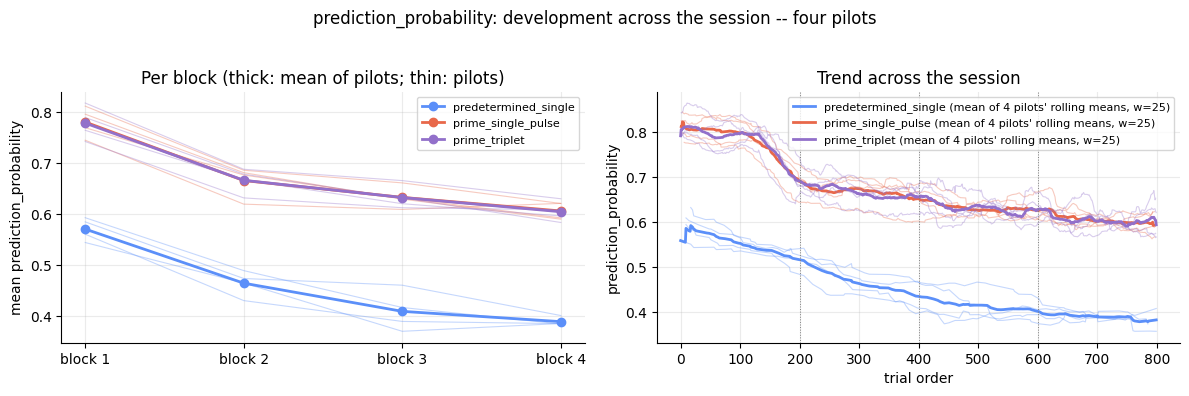

In [38]:
avail = pd.DataFrame({p: iv.groupby("condition").prediction_probability.apply(lambda s: s.notna().sum())
                      for p, iv in IVS.items()}).reindex(CONDS)
print("trials with a non-null prediction_probability, by condition:")
display(with_mean(avail).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
xb = np.arange(len(BLOCK_NAMES))
for cond, color in zip(CONDS, COND_COLORS):
    M_ = pd.DataFrame({p: iv[iv.condition == cond].groupby("stage", sort=False).prediction_probability.mean()
                       .reindex(BLOCK_NAMES) for p, iv in IVS.items()})
    for p in PILOTS:
        axes[0].plot(xb, M_[p], color=color, lw=0.8, alpha=0.35)
    axes[0].plot(xb, M_.mean(axis=1), marker="o", color=color, lw=2, label=cond)
axes[0].set_xticks(xb)
axes[0].set_xticklabels(BLOCK_TICKLABELS)
axes[0].set_ylabel("mean prediction_probability")
axes[0].set_title("Per block (thick: mean of pilots; thin: pilots)")
axes[0].legend(fontsize=8)
trend_plot_avg(axes[1], IVS, "prediction_probability", CONDS, COND_COLORS)
axes[1].set_title("Trend across the session")
fig.suptitle("prediction_probability: development across the session -- four pilots", y=1.03)
fig.tight_layout()
plt.show()

### 8.6 · `prime_attempts`

The number of QC-passing prediction attempts made before the trial triggered (forced or not);
`NaN` for predetermined trials.

prime_attempts, PRIME-guided trials, by condition -- mean over pilots of each pilot's statistic:


,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
prime_single_pulse,240.0,60.61,69.04,1.0,11.19,34.12,85.31,294.5
prime_triplet,480.0,63.87,70.52,0.5,13.19,37.00,89.44,300.0


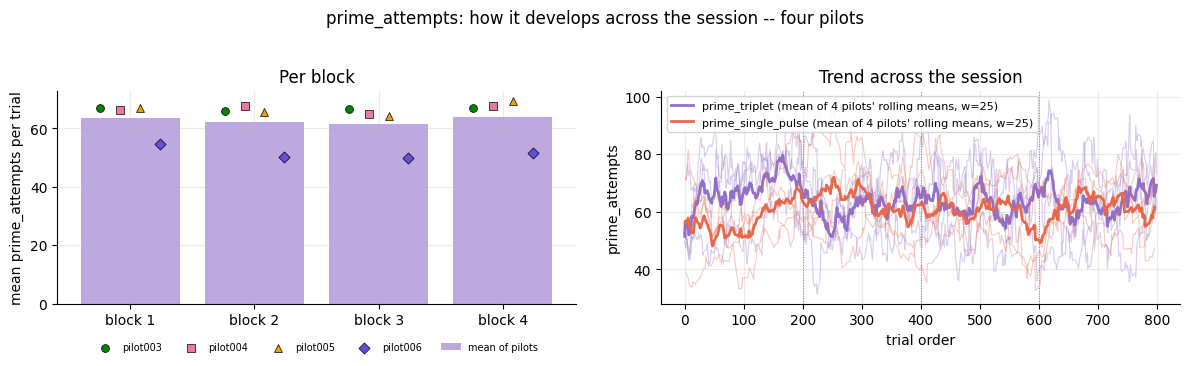

In [39]:
desc = pd.concat({p: d.groupby("condition").prime_attempts.describe() for p, d in prime_guided.items()},
                 names=["pilot"])
print("prime_attempts, PRIME-guided trials, by condition -- mean over pilots of each pilot's statistic:")
display(desc.groupby(level="condition").mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
per_block = pd.DataFrame({p: d.groupby("stage", sort=False).prime_attempts.mean() for p, d in prime_guided.items()})
block_bars_with_pilots(axes[0], per_block, COLOR_PRIME_TRIPLET, "mean prime_attempts per trial", "Per block")
trend_plot_avg(axes[1], prime_guided, "prime_attempts", ["prime_triplet", "prime_single_pulse"],
               [COLOR_PRIME_TRIPLET, COLOR_PRIME_SINGLE])
axes[1].set_title("Trend across the session")
fig.suptitle("prime_attempts: how it develops across the session -- four pilots", y=1.03)
fig.tight_layout()
plt.show()

### 8.7 · `search_time`

`search_time = pulse_time - search_start_time`; with QC-blocked time subtracted it drives the
adaptive threshold towards `TARGET_WAIT`, which was **0.65 s in pilot003–005 and 0.50 s in
pilot006** (both drawn below). Forced trials hit the 5.5 s `PRIME_MAX_WAIT` ceiling.

search_time (s), PRIME-guided trials, by condition and forced status -- mean over pilots:


count   mean    50%    std    max
condition          is_forced                                    
prime_single_pulse False      226.75  0.673  0.443  0.670  2.780
                   True        13.25  3.010  3.010  0.000  3.011
prime_triplet      False      451.00  0.679  0.458  0.669  2.965
                   True        29.00  3.010  3.010  0.000  3.010

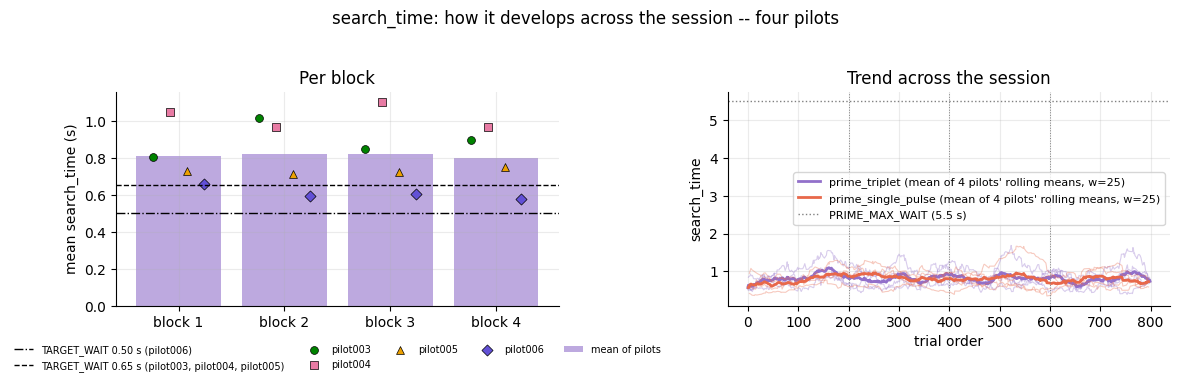

mean search_time per block:


,pilot003,pilot004,pilot005,pilot006,mean
stage,,,,,
intervention_block_1,0.804,1.049,0.727,0.656,0.809
intervention_block_2,1.015,0.965,0.711,0.592,0.821
intervention_block_3,0.849,1.102,0.722,0.604,0.819
intervention_block_4,0.895,0.967,0.750,0.576,0.797


In [40]:
desc = pd.concat({p: d.groupby(["condition", "is_forced"]).search_time.describe()[["count", "mean", "50%", "std", "max"]]
                  for p, d in prime_guided.items()}, names=["pilot"])
print("search_time (s), PRIME-guided trials, by condition and forced status -- mean over pilots:")
display(desc.groupby(level=["condition", "is_forced"]).mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
per_block = pd.DataFrame({p: d.groupby("stage", sort=False).search_time.mean() for p, d in prime_guided.items()})
target_waits = pd.Series({p: AS_RUN[p]["target_wait"] for p in PILOTS})
for (value, group), ls in zip(target_waits.groupby(target_waits), ["-.", "--"]):
    axes[0].axhline(value, color="k", ls=ls, lw=1, zorder=4,
                    label=f"TARGET_WAIT {value:.2f} s ({', '.join(group.index)})")
block_bars_with_pilots(axes[0], per_block, COLOR_PRIME_TRIPLET, "mean search_time (s)", "Per block")
trend_plot_avg(axes[1], prime_guided, "search_time", ["prime_triplet", "prime_single_pulse"],
               [COLOR_PRIME_TRIPLET, COLOR_PRIME_SINGLE])
axes[1].axhline(5.5, color="grey", ls=":", lw=1, label="PRIME_MAX_WAIT (5.5 s)")
axes[1].set_title("Trend across the session")
axes[1].legend(fontsize=8)
fig.suptitle("search_time: how it develops across the session -- four pilots", y=1.03)
fig.tight_layout()
plt.show()
print("mean search_time per block:")
display(with_mean(per_block.reindex(BLOCK_NAMES)).round(3))

### 8.8 · `tep_amplitude`: `prime_single_pulse` vs. `predetermined_single`

`tep_amplitude` is the CDF-normalised label from `TEPNormalizer.transform_verbose`: the raw dipole
amplitude detrended against its own EWMA, z-scored against the session's calibration, then mapped
through the calibration CDF — a number in [0, 1] relative to that session's own calibration. All
four sessions ran the same normaliser, so the label is on one scale across pilots, and the box
plot pools their trials (each pilot's own median is drawn on top). `prime_triplet` never gets this
label.

In [41]:
TWO = ["predetermined_single", "prime_single_pulse"]
TWO_COLORS = [COLOR_PREDETERMINED, COLOR_PRIME_SINGLE]
singles = {p: iv[iv.condition.isin(TWO)].copy() for p, iv in IVS.items()}
avail = pd.DataFrame({p: d.groupby("condition").tep_amplitude.apply(lambda s: s.notna().sum()) for p, d in singles.items()})
print("trials with a non-null tep_amplitude, by condition:")
display(with_mean(avail).round(2))
desc = pd.concat({p: d.groupby("condition").tep_amplitude.describe() for p, d in singles.items()}, names=["pilot"])
print("\ntep_amplitude, descriptive statistics -- mean over pilots of each pilot's statistic:")
display(desc.groupby(level="condition").mean().round(3))

trials with a non-null tep_amplitude, by condition:


,pilot003,pilot004,pilot005,pilot006,mean
condition,,,,,
predetermined_single,70,73,74,77,73.50
prime_single_pulse,203,217,221,236,219.25



tep_amplitude, descriptive statistics -- mean over pilots of each pilot's statistic:


,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
predetermined_single,73.50,0.422,0.301,0.003,0.178,0.396,0.646,0.991
prime_single_pulse,219.25,0.496,0.316,0.000,0.190,0.509,0.784,0.997


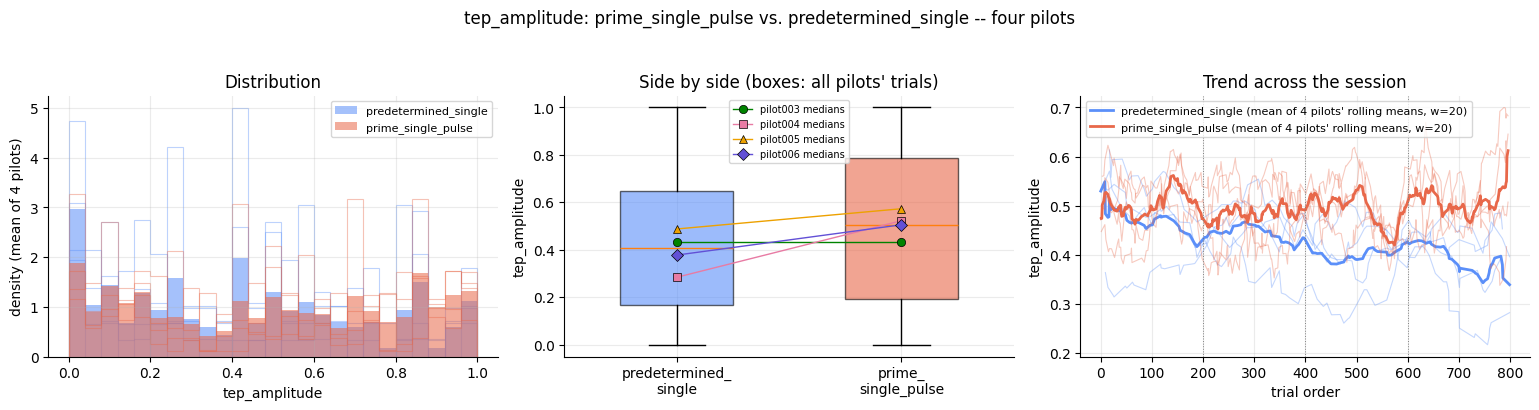

,pilot003,pilot004,pilot005,pilot006,mean
prime_single_pulse median,0.434,0.523,0.573,0.506,0.509
n prime_single_pulse,203.000,217.000,221.000,236.000,219.250
predetermined_single median,0.434,0.284,0.488,0.378,0.396
n predetermined_single,70.000,73.000,74.000,77.000,73.500
difference in medians (prime - predetermined),0.000,0.239,0.085,0.128,0.113


In [42]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.9))
bins = np.linspace(0, 1, 26)
for cond, color in zip(TWO, TWO_COLORS):
    plot_mean_hist(axes[0], {p: d.loc[d.condition == cond, "tep_amplitude"] for p, d in singles.items()}, bins,
                   color, label=cond, density=True, outline=color)
axes[0].set_xlabel("tep_amplitude")
axes[0].set_ylabel("density (mean of 4 pilots)")
axes[0].set_title("Distribution")
axes[0].legend(fontsize=8)

pooled = [pd.concat([d.loc[d.condition == c, "tep_amplitude"] for d in singles.values()]).dropna() for c in TWO]
bp = axes[1].boxplot(pooled, positions=[1, 2], widths=0.5, patch_artist=True)
for patch, color in zip(bp["boxes"], TWO_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
medians = pd.DataFrame({p: d.groupby("condition").tep_amplitude.median().reindex(TWO) for p, d in singles.items()})
for p in PILOTS:
    axes[1].plot([1, 2], medians[p].values, color=PILOT_COLORS[p], marker=PILOT_MARKERS[p], markeredgecolor="black",
                 markeredgewidth=0.5, lw=1, zorder=4, label=f"{p} medians")
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["predetermined_\nsingle", "prime_\nsingle_pulse"])
axes[1].set_ylabel("tep_amplitude")
axes[1].set_title("Side by side (boxes: all pilots' trials)")
axes[1].legend(fontsize=7)

trend_plot_avg(axes[2], singles, "tep_amplitude", TWO, TWO_COLORS, window=20)
axes[2].set_title("Trend across the session")
fig.suptitle("tep_amplitude: prime_single_pulse vs. predetermined_single -- four pilots", y=1.04)
fig.tight_layout()
plt.show()

rows = {}
for p, d in singles.items():
    a = d.loc[d.condition == "prime_single_pulse", "tep_amplitude"].dropna()
    b = d.loc[d.condition == "predetermined_single", "tep_amplitude"].dropna()
    rows[p] = {"prime_single_pulse median": a.median(), "n prime_single_pulse": len(a),
               "predetermined_single median": b.median(), "n predetermined_single": len(b),
               "difference in medians (prime - predetermined)": a.median() - b.median()}
display(with_mean(pd.DataFrame(rows)).round(3))

### 8.9 · Correlation: `prediction_probability` vs. `tep_amplitude`

Computed on single-pulse trials with both values, within each pilot. As in the single-session
notebook: for `prime_single_pulse`, `prediction_probability >= threshold` is why the pulse fired
(range restriction, not corrected for); `predetermined_single` trials fire on a clock. In the
figure, colour is the condition and the marker shape the pilot; thin lines are each pilot's fit
and the thick line the mean of the four fits (mean intercept and slope).

trials with both prediction_probability and tep_amplitude:


,pilot003,pilot004,pilot005,pilot006,mean
condition,,,,,
predetermined_single,64,70,74,74,70.50
prime_single_pulse,186,198,212,231,206.75


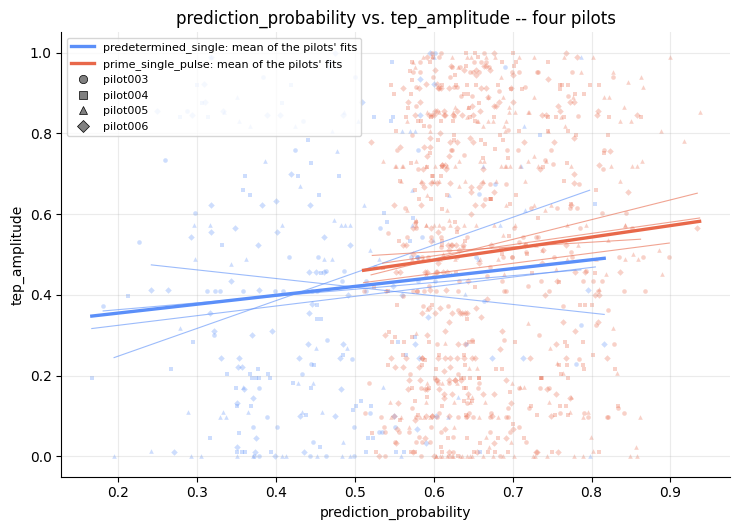

Pearson r, within each pilot:


pilot,pilot003,pilot004,pilot005,pilot006,mean (Fisher z)
subset,,,,,
combined,0.112,0.164,0.187,0.118,0.145
predetermined_single only,0.078,0.086,0.288,-0.090,0.092
prime_single_pulse only,0.072,0.029,0.081,0.122,0.076


Spearman rho, within each pilot:


pilot,pilot003,pilot004,pilot005,pilot006,mean (Fisher z)
subset,,,,,
combined,0.165,0.155,0.163,0.140,0.156
predetermined_single only,0.155,0.030,0.273,-0.088,0.095
prime_single_pulse only,0.112,0.028,0.078,0.137,0.089


p-values and n, within each pilot:


n  p_pearson  p_spearman
subset                    pilot                               
combined                  pilot003  250     0.0777      0.0090
                          pilot004  268     0.0073      0.0110
                          pilot005  286     0.0015      0.0057
                          pilot006  305     0.0402      0.0141
predetermined_single only pilot003   64     0.5407      0.2200
                          pilot004   70     0.4775      0.8024
                          pilot005   74     0.0129      0.0184
                          pilot006   74     0.4474      0.4546
prime_single_pulse only   pilot003  186     0.3280      0.1289
                          pilot004  198     0.6818      0.6970
                          pilot005  212     0.2420      0.2560
                          pilot006  231     0.0636      0.0380

In [43]:
corr_df = {p: d.dropna(subset=["prediction_probability", "tep_amplitude"]) for p, d in singles.items()}
print("trials with both prediction_probability and tep_amplitude:")
display(with_mean(pd.DataFrame({p: c.groupby("condition").size() for p, c in corr_df.items()})).round(2))

fig, ax = plt.subplots(figsize=(7.5, 5.4))
for cond, color in zip(TWO, TWO_COLORS):
    fits, xs_all = [], []
    for p, c in corr_df.items():
        d = c[c.condition == cond]
        ax.scatter(d.prediction_probability, d.tep_amplitude, s=11, alpha=0.3, color=color, marker=PILOT_MARKERS[p],
                   linewidths=0)
        if len(d) > 2:
            b1, b0 = np.polyfit(d.prediction_probability, d.tep_amplitude, 1)
            fits.append((b0, b1))
            xs_all.append(d.prediction_probability)
            xs = np.linspace(d.prediction_probability.min(), d.prediction_probability.max(), 20)
            ax.plot(xs, b0 + b1 * xs, color=color, lw=0.8, alpha=0.6)
    if fits:
        b0m, b1m = np.mean(fits, axis=0)
        xa = pd.concat(xs_all)
        xs = np.linspace(xa.min(), xa.max(), 20)
        ax.plot(xs, b0m + b1m * xs, color=color, lw=2.4, label=f"{cond}: mean of the pilots' fits")
ax.set_xlabel("prediction_probability")
ax.set_ylabel("tep_amplitude")
ax.set_title("prediction_probability vs. tep_amplitude -- four pilots")
h, l = ax.get_legend_handles_labels()
ax.legend(handles=h + pilot_marker_handles(color="grey"), fontsize=8)
fig.tight_layout()
plt.show()

rows = []
for p, c in corr_df.items():
    for label, d in [("combined", c), ("predetermined_single only", c[c.condition == "predetermined_single"]),
                     ("prime_single_pulse only", c[c.condition == "prime_single_pulse"])]:
        if len(d) < 3:
            continue
        r, p_r = stats.pearsonr(d.prediction_probability, d.tep_amplitude)
        rho, p_rho = stats.spearmanr(d.prediction_probability, d.tep_amplitude)
        rows.append({"pilot": p, "subset": label, "n": len(d), "pearson_r": r, "p_pearson": p_r,
                     "spearman_rho": rho, "p_spearman": p_rho})
corr_tab = pd.DataFrame(rows)
SUBSETS = ["combined", "predetermined_single only", "prime_single_pulse only"]
for value, name in [("pearson_r", "Pearson r"), ("spearman_rho", "Spearman rho")]:
    t = corr_tab.pivot(index="subset", columns="pilot", values=value).reindex(SUBSETS)
    t["mean (Fisher z)"] = [mean_r(t.loc[s, PILOTS]) for s in SUBSETS]
    print(f"{name}, within each pilot:")
    display(t.round(3))
print("p-values and n, within each pilot:")
display(corr_tab.set_index(["subset", "pilot"])[["n", "p_pearson", "p_spearman"]].sort_index().round(4))

# Chapter 2 · Offline replay, intervention comparison, and sensor-space TEPs

Baseline and the four evaluation runs are open-loop blocks whose deciders (`1_baseline.py`,
`3_evaluation.py`) only save raw pre/post buffers. Item 1 replays them offline, together with the
calibration trials, with each session's saved calibration state and the actual `prime_core`
classes — the single-session notebook's approach, run once per session. The intervention blocks'
`predetermined_single` trials (item 1.1) and the PRIME single pulses grouped by prediction
probability (item 4.5) come from the post-stimulus epochs the decider saved online (`_post_proc.npy`,
no replay).

**As-run settings.** Three settings that `preprocess_post` reads from `prime/decider`'s config at
call time, not from the bundle, have changed since these sessions (section 1). With today's values
the replay does not reproduce pilot003–005: pilot003's saved intervention epochs differ by up to
about 32 µV and 24 of its 320 single-pulse reject decisions change. So `restore_session()` below
sets each session's own values on its restored `Preprocessor` (in memory only). The **replay check**
then reprocesses every intervention single pulse of every session from `_post_raw.npy` and
compares it with what the decider saved online:

1. the processed epoch against `_post_proc.npy` (saved before the reject gates, so rejected trials
   have one too),
2. the reject decision and reason against `post_reject_reason`,
3. the dipole amplitude against `tep_amplitude_raw`,
4. for predetermined singles, the pre-stimulus path as well: `preprocess_pre` on `_pre_raw.npy`
   against `preprocessing_failed`, and its epoch against `_pre_proc.npy`.

The replay is used only if all of these match for every session (`STRICT_REPLAY_CHECK`).

**Evaluation runs** are numbered by the order they were started; runs 1–4 are labelled
`evaluation_t0` … `evaluation_t60`, as in the single-session notebook. The timing check below
prints when each run's CSV was written relative to the last intervention pulse.

**Caching.** The check and the replay are stored per session in `cache/` (keyed on the as-run
settings, the checked-out decider commit and the session's bundle/trial-table file sizes). They are
recomputed automatically when any of these change, or when `RECOMPUTE_REPLAY = True`.

In [44]:
# ---------------------------------------------------------------- import the actual online code
sys.dont_write_bytecode = True   # do not leave __pycache__ folders inside prime/
DECIDER_DIR = LOOP_ROOT / "prime" / "decider"
if str(DECIDER_DIR) not in sys.path:
    sys.path.insert(0, str(DECIDER_DIR))
from prime_core.preprocessing.preprocessor import Preprocessor
from prime_core.preprocessing.dipole_fitter import DipoleFitter
from prime_core.preprocessing.config import get_default_config
from prime_core.prime_config import (
    get_raw_sfreq, get_qc_time_range, get_post_initial_time_range,
    get_post_time_range, get_dipole_time_range, epoch_n_times,
)

RAW_SFREQ = get_raw_sfreq()
QC_TMIN, QC_TMAX = get_qc_time_range()                     # pre-stim saved-buffer window (s)
POST_I_TMIN, POST_I_TMAX = get_post_initial_time_range()   # post-stim saved-buffer window (s)
POST_TMIN, POST_TMAX = get_post_time_range()                # preprocess_post's final crop (s)
DIPOLE_TMIN, DIPOLE_TMAX = get_dipole_time_range()          # dipole-fitting epoch (s)

def _decider_head() -> str:
    """Commit checked out in prime/decider, read from .git without running git."""
    git = DECIDER_DIR / ".git"
    try:
        head = (git / "HEAD").read_text().strip()
        if not head.startswith("ref:"):
            return head[:7]
        ref = head.split(" ", 1)[1].strip()
        if (git / ref).is_file():
            return (git / ref).read_text().strip()[:7]
        for line in (git / "packed-refs").read_text().splitlines():
            if line.endswith(" " + ref):
                return line.split()[0][:7]
    except OSError:
        pass
    return "unknown"

DECIDER_HEAD = _decider_head()
print(f"prime/decider checked out at {DECIDER_HEAD}")
print(f"raw_sfreq = {RAW_SFREQ:.0f} Hz; saved buffers: pre [{QC_TMIN}, {QC_TMAX}] s, post [{POST_I_TMIN}, {POST_I_TMAX}] s; "
      f"post window [{POST_TMIN}, {POST_TMAX}] s; dipole window [{DIPOLE_TMIN}, {DIPOLE_TMAX}] s")

prime/decider checked out at c62d04a
raw_sfreq = 5000 Hz; saved buffers: pre [-0.21, -0.01] s, post [-0.03, 0.1] s; post window [0.001, 0.1] s; dipole window [0.038, 0.05] s


In [45]:
# ---------------------------------------------------------------- as-run settings vs. the current decider
_cur = get_default_config()
_ms = lambda w: f"{w[0] * 1000:g} to {w[1] * 1000:g} ms"
settings = pd.DataFrame({
    f"current prime/decider ({DECIDER_HEAD})": {
        "TEP baseline window": _ms(_cur.baseline), "artifact_window_1": _ms(_cur.artifact_window_1),
        "ocular z cutoff": f"{_cur.trial_reject_opts.ocular.z_threshold:g}",
        "post rate (Hz)": "-", "post 500 Hz low-pass": "-", "bad channels": "-"},
    **{p: {"TEP baseline window": _ms(AS_RUN[p]["baseline"]), "artifact_window_1": _ms(AS_RUN[p]["artifact_window_1"]),
           "ocular z cutoff": f"{AS_RUN[p]['ocular_z']:g}",
           "post rate (Hz)": f"{Preprocessor.bundle_post_sfreq(bundles[p]):.0f}",
           "post 500 Hz low-pass": str(bool(bundles[p].get("post_lowpass", False))),
           "bad channels": ", ".join(str(c) for c in bundles[p]["bad_channels"])} for p in PILOTS},
})
print("Settings used for each session's replay (from AS_RUN; post rate, low-pass and bad channels from its bundle):")
display(settings)
print(f"artifact_window_2 (second blank) in every session: [post_tmin, {_cur.artifact_window_2[1] * 1000:g}] ms")

# Evaluation run order: minutes between the last intervention pulse's buffer and each run's CSV.
rows = {}
for p in PILOTS:
    d = SESSION_DIRS[p]
    last_iv = d / "intervention_block_4_0199_post_raw.npy"
    if last_iv.is_file():
        rows[p] = {f"run {r}": ((d / f"trials_evaluation_{r}.csv").stat().st_mtime - last_iv.stat().st_mtime) / 60
                   for r in range(1, 5)}
print("\nminutes from the last intervention pulse to each evaluation run's CSV (t0/t15/t30/t60 expected, "
      "each CSV written when its 100-trial run ends):")
display(pd.DataFrame(rows).T.round(1))

Settings used for each session's replay (from AS_RUN; post rate, low-pass and bad channels from its bundle):


,current prime/decider (c62d04a),pilot003,pilot004,pilot005,pilot006
TEP baseline window,-15 to -5 ms,-25 to -15 ms,-25 to -15 ms,-25 to -15 ms,-15 to -5 ms
artifact_window_1,-2 to 14 ms,-14 to 14 ms,-14 to 14 ms,-14 to 14 ms,-2 to 14 ms
ocular z cutoff,2.5,2,2,2.5,3
post rate (Hz),-,1000,1000,1000,5000
post 500 Hz low-pass,-,False,False,False,True
bad channels,-,"C3, CP3, FC1, P4, T7","Fz, P4, P8","C3, CP3, T8","C3, F3, FC1, FC3, FT7, T7, T8"


artifact_window_2 (second blank) in every session: [post_tmin, 15] ms

minutes from the last intervention pulse to each evaluation run's CSV (t0/t15/t30/t60 expected, each CSV written when its 100-trial run ends):


,run 1,run 2,run 3,run 4
pilot003,6.5,22.4,36.6,65.9
pilot004,8.8,21.4,35.8,64.6
pilot005,6.7,21.4,36.7,65.7
pilot006,9.7,26.4,43.1,70.3


In [46]:
# ---------------------------------------------------------------- restore, check, replay (one session at a time)
BLOCKS = [
    ("baseline",   None, "baseline"),
    ("evaluation", 1,    "evaluation_t0"),
    ("evaluation", 2,    "evaluation_t15"),
    ("evaluation", 3,    "evaluation_t30"),
    ("evaluation", 4,    "evaluation_t60"),
]
BLOCK_LABELS = [label for _, _, label in BLOCKS]
INTERVENTION_LABEL = "intervention_predetermined_single"
ALL_BLOCK_LABELS = ["baseline", INTERVENTION_LABEL] + BLOCK_LABELS[1:]          # item 4
BOXPLOT_LABELS = ["baseline", "calibration", INTERVENTION_LABEL] + BLOCK_LABELS[1:]   # item 1.1

def _stem(stage, run, trial):
    prefix = stage if run is None else f"{stage}_{run}"
    return f"{prefix}_{trial:04d}"

def _n_trials(d, stage, run):
    prefix = stage if run is None else f"{stage}_{run}"
    return len(list(d.glob(f"{prefix}_*_pre_raw.npy")))

_RESTORED = {}

def restore_session(p):
    """Calibrated Preprocessor + DipoleFitter of session p, as in the single-session notebook
    (Preprocessor.from_bundle; fitting_info assigned directly, since DipoleFitter has no restore
    method), plus the session's as-run settings from AS_RUN, set in memory."""
    if p in _RESTORED:
        return _RESTORED[p]
    pp = Preprocessor.from_bundle(bundles[p], fwd_path)
    pp._cfg.baseline = list(AS_RUN[p]["baseline"])
    pp._cfg.artifact_window_1 = list(AS_RUN[p]["artifact_window_1"])
    pp._cfg.trial_reject_opts.ocular.z_threshold = float(AS_RUN[p]["ocular_z"])
    pp._opts = pp._cfg.to_dicts()     # preprocess_pre reads this snapshot taken in __init__
    pp.keep_full_epochs = True        # fills last_post_full / last_post_baselines
    post_sfreq = pp.post_sfreq        # from the bundle: 1 kHz for pilot001-005, 5 kHz since pilot006
    assert abs(post_sfreq - _window_sfreq(proc_info[p], "post")) < 1e-6
    fitter = DipoleFitter(fwd_path, sfreq=post_sfreq)
    fitter._fitting_info = dipole_info[p]
    assert list(pp._info["ch_names"]) == CH_NAMES, f"{p}: channel order differs from proc_info.npy"
    t_ms = np.linspace(POST_TMIN * 1000, POST_TMAX * 1000, epoch_n_times(POST_TMIN, POST_TMAX, post_sfreq))
    mask = (t_ms >= DIPOLE_TMIN * 1000 - 1e-6) & (t_ms <= DIPOLE_TMAX * 1000 + 1e-6)
    assert mask.sum() == epoch_n_times(DIPOLE_TMIN, DIPOLE_TMAX, post_sfreq)
    _RESTORED[p] = dict(preprocessor=pp, fitter=fitter, post_sfreq=post_sfreq, post_time_ms=t_ms, dipole_mask=mask)
    return _RESTORED[p]

def check_session(p):
    """Replay every intervention single pulse from _post_raw.npy and compare with what the decider
    saved online: processed epoch vs _post_proc.npy, reject reason vs post_reject_reason, dipole
    amplitude vs tep_amplitude_raw. For predetermined singles whose post window passed, the
    pre-stimulus path too: preprocess_pre on _pre_raw.npy vs preprocessing_failed, and its epoch
    (before the MAD gates) vs _pre_proc.npy -- the same pre path item 2's predictions rest on."""
    d, R = SESSION_DIRS[p], restore_session(p)
    pp, fitter = R["preprocessor"], R["fitter"]
    trials = IVS[p][IVS[p].condition.isin(["prime_single_pulse", "predetermined_single"])]
    max_epoch, max_amp, mismatches = 0.0, 0.0, []
    n_pre, max_pre, pre_mismatches = 0, 0.0, []
    for r in trials.itertuples():
        stem = f"{r.stage}_{int(r.trial_in_stage):04d}"
        raw = np.load(d / f"{stem}_post_raw.npy")
        post = pp.preprocess_post(raw, POST_I_TMIN + np.arange(raw.shape[0]) / RAW_SFREQ)
        max_epoch = max(max_epoch, float(np.max(np.abs(pp.last_post_full - np.load(d / f"{stem}_post_proc.npy")))))
        online = r.post_reject_reason if isinstance(r.post_reject_reason, str) else None
        if online != pp.last_post_reject_reason:
            mismatches.append((stem, online, pp.last_post_reject_reason))
        if post is not None and np.isfinite(r.tep_amplitude_raw):
            max_amp = max(max_amp, abs(float(fitter.fit_trial(post)) - float(r.tep_amplitude_raw)))
        if r.condition == "predetermined_single" and post is not None:
            pre_raw = np.load(d / f"{stem}_pre_raw.npy")
            buf = pp.preprocess_pre(pre_raw, QC_TMIN + np.arange(pre_raw.shape[0]) / RAW_SFREQ, from_pulse=True)
            n_pre += 1
            if (buf is None) != bool(r.preprocessing_failed):
                pre_mismatches.append((stem, bool(r.preprocessing_failed), buf is None))
            fp = d / f"{stem}_pre_proc.npy"
            if fp.is_file():
                max_pre = max(max_pre, float(np.max(np.abs(pp.last_pre_full - np.load(fp)))))
    return dict(n=len(trials), max_epoch_diff=max_epoch, max_amp_diff=max_amp, mismatches=mismatches,
                n_pre=n_pre, max_pre_diff=max_pre, pre_mismatches=pre_mismatches)

def replay_session(p):
    """Items 1, 1.1, 4 and 4.5 for session p: replay baseline, evaluation 1-4 and calibration from
    their raw buffers; read the intervention epochs saved online; average every group's full
    [post_tmin, post_tmax] epochs (running sums, so no trial arrays are kept)."""
    d, R = SESSION_DIRS[p], restore_session(p)
    pp, fitter, mask = R["preprocessor"], R["fitter"], R["dipole_mask"]
    sums, counts = {}, {}

    def _add(label, epoch):
        sums[label] = sums.get(label, 0.0) + epoch
        counts[label] = counts.get(label, 0) + 1

    records = []
    for stage, run, label in BLOCKS + [("calibration", None, "calibration")]:
        for trial in range(_n_trials(d, stage, run)):
            stem = _stem(stage, run, trial)
            pre_raw = np.load(d / f"{stem}_pre_raw.npy")
            post_raw = np.load(d / f"{stem}_post_raw.npy")
            model_buf = pp.preprocess_pre(pre_raw, QC_TMIN + np.arange(pre_raw.shape[0]) / RAW_SFREQ, from_pulse=True)
            post = pp.preprocess_post(post_raw, POST_I_TMIN + np.arange(post_raw.shape[0]) / RAW_SFREQ)
            rec = {"pilot": p, "block": label, "run_index": np.nan if run is None else float(run),
                   "trial_in_stage": trial, "preprocessing_success": model_buf is not None,
                   "postprocessing_success": post is not None,
                   "postprocessing_reject_reason": pp.last_post_reject_reason, "tep_amplitude": np.nan,
                   "baseline_correction_1_mean_abs": np.nan, "baseline_correction_2_mean_abs": np.nan}
            if pp.last_post_baselines is not None:
                b1, b2 = pp.last_post_baselines
                rec["baseline_correction_1_mean_abs"] = float(np.abs(b1).mean())
                rec["baseline_correction_2_mean_abs"] = float(np.abs(b2).mean())
            if post is not None:
                rec["tep_amplitude"] = float(fitter.fit_trial(post))
                _add(label, pp.last_post_full)
            records.append(rec)

    iv = IVS[p]
    # item 1.1: intervention predetermined singles, from the epochs processed online (no replay)
    predet_ok = iv[(iv.condition == "predetermined_single") & (~iv.postprocessing_failed)]
    amps, n_missing = [], 0
    for r in predet_ok.itertuples():
        fp = d / f"{r.stage}_{int(r.trial_in_stage):04d}_post_proc.npy"
        if not fp.is_file():
            n_missing += 1
            continue
        epoch = np.load(fp)
        if epoch.shape[1] != len(R["post_time_ms"]):
            raise ValueError(f"{fp.name}: {epoch.shape[1]} samples, expected {len(R['post_time_ms'])}")
        amps.append(float(fitter.fit_trial(epoch[:, mask])))
        _add(INTERVENTION_LABEL, epoch)

    # item 4.5: prime_single_pulse split at the quartiles of this session's own prediction_probability
    ps_all = iv[iv.condition == "prime_single_pulse"]
    usable = ps_all[ps_all.prediction_probability.notna() & (~ps_all.postprocessing_failed)]
    q25, q75 = usable.prediction_probability.quantile([0.25, 0.75])
    groups = {"prime_single_top25pct": usable[usable.prediction_probability >= q75],
              "prime_single_bottom25pct": usable[usable.prediction_probability <= q25]}
    group_missing = {}
    for name, df in groups.items():
        group_missing[name] = 0
        for r in df.itertuples():
            fp = d / f"{r.stage}_{int(r.trial_in_stage):04d}_post_proc.npy"
            if not fp.is_file():
                group_missing[name] += 1
                continue
            _add(name, np.load(fp))

    return dict(table=pd.DataFrame.from_records(records).to_dict("list"),
                intervention_tep_amplitude=np.asarray(amps), intervention_n_eligible=len(predet_ok),
                intervention_n_missing=n_missing,
                evoked={k: sums[k] / counts[k] for k in sums}, n=dict(counts),
                post_time_ms=R["post_time_ms"], post_sfreq=R["post_sfreq"],
                q25=float(q25), q75=float(q75), n_prime_single=len(ps_all), n_forced=int(ps_all.is_forced.sum()),
                n_no_prob=int(ps_all.prediction_probability.isna().sum()), n_usable=len(usable),
                group_sizes={k: len(v) for k, v in groups.items()}, group_missing=group_missing)

CACHE_VERSION = "2026-11-04.2"

def _cache_key(kind, p):
    files = [bundle_path(SESSION_DIRS[p]), SESSION_DIRS[p] / "trials_intervention.csv"]
    return dict(kind=kind, version=CACHE_VERSION, pilot=p, decider=DECIDER_HEAD,
                as_run={k: (list(v) if isinstance(v, tuple) else v) for k, v in AS_RUN[p].items()},
                files=[(f.name, f.stat().st_size) for f in files])

def cached(kind, p, compute):
    """compute(p), stored in CACHE_DIR; reused while the key matches and RECOMPUTE_REPLAY is False."""
    path = CACHE_DIR / f"{p}_{kind}.pkl"
    key = _cache_key(kind, p)
    if path.is_file() and not RECOMPUTE_REPLAY:
        with open(path, "rb") as f:
            stored = pickle.load(f)
        if stored.get("key") == key:
            return stored["result"], stored["made"], True
    t0 = time.time()
    result = compute(p)
    made = dict(when=time.strftime("%Y-%m-%d %H:%M %Z"), seconds=round(time.time() - t0, 1),
                system=platform.system(), python=platform.python_version(), numpy=np.__version__,
                scipy=scipy.__version__, mne=mne.__version__)
    with open(path, "wb") as f:
        pickle.dump(dict(key=key, result=result, made=made), f)
    return result, made, False

In [47]:
# ---------------------------------------------------------------- replay check, then replay (cached)
CHECKS, check_rows = {}, {}
for p in PILOTS:
    CHECKS[p], made, hit = cached("replay_check", p, check_session)
    c = CHECKS[p]
    check_rows[p] = {"single pulses replayed": str(c["n"]),
                     "max |epoch - _post_proc.npy|": f"{c['max_epoch_diff']:.1e}",
                     "reject decisions matching online": f"{c['n'] - len(c['mismatches'])}/{c['n']}",
                     "max |amplitude - tep_amplitude_raw|": f"{c['max_amp_diff']:.1e}",
                     "predetermined pre-stim: failures matching online": f"{c['n_pre'] - len(c['pre_mismatches'])}/{c['n_pre']}",
                     "max |pre epoch - _pre_proc.npy|": f"{c['max_pre_diff']:.1e}"}
    print(f"{p}: {'loaded from cache, computed' if hit else 'computed'} {made['when']} "
          f"({made['system']}, python {made['python']}, numpy {made['numpy']}, mne {made['mne']}; {made['seconds']} s)")
print("\nReplay check -- every intervention single pulse, replayed with the session's as-run settings:")
display(pd.DataFrame(check_rows))
failed = [p for p, c in CHECKS.items()
          if c["mismatches"] or c["pre_mismatches"] or c["max_epoch_diff"] > 1e-8 or c["max_amp_diff"] > 1e-8
          or c["max_pre_diff"] > 1e-8]
if failed:
    msg = (f"the replay does not reproduce the online processing for {failed}; first mismatches: "
           f"{ {p: (CHECKS[p]['mismatches'] + CHECKS[p]['pre_mismatches'])[:5] for p in failed} }. Check AS_RUN "
           f"for these sessions (or whether prime/decider changed in a way the as-run settings do not cover).")
    if STRICT_REPLAY_CHECK:
        raise AssertionError(msg + " Set STRICT_REPLAY_CHECK = False to continue anyway.")
    print("WARNING: " + msg)
else:
    print("All four sessions reproduce their online processing: chapter 2's replay below uses these settings.")

REPLAYS, replay_rows = {}, {}
for p in PILOTS:
    REPLAYS[p], made, hit = cached("replay", p, replay_session)
    replay_rows[p] = f"{'cache' if hit else 'computed now'} ({made['when']}, {made['seconds']} s)"
print("\nreplay: " + "; ".join(f"{p} {v}" for p, v in replay_rows.items()))

replay_all = pd.concat([pd.DataFrame(REPLAYS[p]["table"]) for p in PILOTS], ignore_index=True)
replay_all["run_index"] = pd.to_numeric(replay_all["run_index"])
replay = replay_all[replay_all.block != "calibration"].reset_index(drop=True)     # the 5 replayed blocks

pilot003: loaded from cache, computed 2026-11-04 17:17 UTC (Linux, python 3.10.12, numpy 2.2.6, mne 1.10.0; 18.9 s)
pilot004: loaded from cache, computed 2026-11-04 17:18 UTC (Linux, python 3.10.12, numpy 2.2.6, mne 1.10.0; 19.1 s)
pilot005: loaded from cache, computed 2026-11-04 17:18 UTC (Linux, python 3.10.12, numpy 2.2.6, mne 1.10.0; 18.5 s)
pilot006: loaded from cache, computed 2026-11-04 17:18 UTC (Linux, python 3.10.12, numpy 2.2.6, mne 1.10.0; 21.3 s)

Replay check -- every intervention single pulse, replayed with the session's as-run settings:


,pilot003,pilot004,pilot005,pilot006
single pulses replayed,320,320,320,320
max |epoch - _post_proc.npy|,0.0e+00,0.0e+00,0.0e+00,7.1e-14
reject decisions matching online,320/320,320/320,320/320,320/320
max |amplitude - tep_amplitude_raw|,9.7e-17,5.0e-10,9.7e-17,9.7e-17
predetermined pre-stim: failures matching online,70/70,73/73,74/74,77/77
max |pre epoch - _pre_proc.npy|,0.0e+00,0.0e+00,0.0e+00,0.0e+00


All four sessions reproduce their online processing: chapter 2's replay below uses these settings.

replay: pilot003 cache (2026-11-04 17:19 UTC, 32.0 s); pilot004 cache (2026-11-04 17:19 UTC, 31.9 s); pilot005 cache (2026-11-04 17:20 UTC, 31.4 s); pilot006 cache (2026-11-04 17:21 UTC, 36.0 s)


## Item 1 · `TEP_amplitude` from the post-stimulus buffers

For each trial of baseline and the four evaluation runs, `preprocess_post` runs the full online
post-stimulus pipeline on the saved buffer (rejection: `'ocular'`, `'global_mad'` or `'local_mad'`),
and `fit_trial` fits the session's fixed free-orientation dipole: that is `TEP_amplitude`, in raw
µAm with no further normalisation. `preprocess_pre` runs alongside on the pre-stimulus buffer (its
success is item 2's input). The tables give each pilot's block summary and the mean over pilots.

In [48]:
summary = replay.groupby(["pilot", "block"], sort=False).agg(
    n_trials=("trial_in_stage", "size"),
    preprocessing_failures=("preprocessing_success", lambda s: int((~s.astype(bool)).sum())),
    postprocessing_failures=("postprocessing_success", lambda s: int((~s.astype(bool)).sum())),
    tep_amplitude_n=("tep_amplitude", "count"),
    tep_amplitude_median=("tep_amplitude", "median"),
)
print(f"processed {len(replay)} trials ({len(replay) // len(PILOTS)} per pilot) across {len(BLOCKS)} blocks\n")
print("mean over pilots, per block:")
display(summary.groupby(level="block", sort=False).mean().reindex(BLOCK_LABELS).round(4))
print("per pilot:")
display(summary.round(4))

rej = replay.loc[~replay.postprocessing_success.astype(bool)]
print("\npostprocessing rejection reasons by block -- summed over the four pilots:")
display(pd.crosstab(rej.block, rej.postprocessing_reject_reason).reindex(BLOCK_LABELS).fillna(0).astype(int))
print("per pilot:")
display(pd.crosstab([rej.pilot, rej.block], rej.postprocessing_reject_reason))

processed 2000 trials (500 per pilot) across 5 blocks

mean over pilots, per block:


,n_trials,preprocessing_failures,postprocessing_failures,tep_amplitude_n,tep_amplitude_median
block,,,,,
baseline,100.0,3.00,7.00,93.00,0.0749
evaluation_t0,100.0,5.50,5.00,95.00,0.0835
evaluation_t15,100.0,4.00,10.00,90.00,0.0785
evaluation_t30,100.0,3.25,7.75,92.25,0.0732
evaluation_t60,100.0,4.75,9.25,90.75,0.0752


per pilot:


n_trials  preprocessing_failures  postprocessing_failures  tep_amplitude_n  tep_amplitude_median
pilot    block                                                                                                           
pilot003 baseline             100                       3                        5               95                0.0605
         evaluation_t0        100                       8                        8               92                0.0674
         evaluation_t15       100                       5                       10               90                0.0471
         evaluation_t30       100                       6                        4               96                0.0500
         evaluation_t60       100                       4                       10               90                0.0504
pilot004 baseline             100                       4                        5               95                0.1045
         evaluation_t0        100                       5                        9               91                0.0950
         evaluation_t15       100                       5                       12               88                0.0950
         evaluation_t30       100                       3                        8               92                0.0902
         evaluation_t60       100                       5                        5               95                0.1055
pilot005 baseline             100                       1                       17               83                0.0311
         evaluation_t0        100                       2                        3               97                0.0436
         evaluation_t15       100                       3                       16               84                0.0469
         evaluation_t30       100                       2                       18               82                0.0425
         evaluation_t60       100                       3                       20               80                0.0399
pilot006 baseline             100                       4                        1               99                0.1035
         evaluation_t0        100                       7                        0              100                0.1279
         evaluation_t15       100                       3                        2               98                0.1248
         evaluation_t30       100                       2                        1               99                0.1100
         evaluation_t60       100                       7                        2               98                0.1051


postprocessing rejection reasons by block -- summed over the four pilots:


postprocessing_reject_reason,global_mad,local_mad,ocular
block,,,
baseline,0,2,26
evaluation_t0,0,4,16
evaluation_t15,2,5,33
evaluation_t30,0,2,29
evaluation_t60,0,4,33


per pilot:


postprocessing_reject_reason  global_mad  local_mad  ocular
pilot    block                                             
pilot003 baseline                      0          0       5
         evaluation_t0                 0          3       5
         evaluation_t15                2          2       6
         evaluation_t30                0          0       4
         evaluation_t60                0          3       7
pilot004 baseline                      0          2       3
         evaluation_t0                 0          1       8
         evaluation_t15                0          2      10
         evaluation_t30                0          2       6
         evaluation_t60                0          0       5
pilot005 baseline                      0          0      17
         evaluation_t0                 0          0       3
         evaluation_t15                0          1      15
         evaluation_t30                0          0      18
         evaluation_t60                0          1      19
pilot006 baseline                      0          0       1
         evaluation_t15                0          0       2
         evaluation_t30                0          0       1
         evaluation_t60                0          0       2

### 1.1 · `TEP_amplitude` across baseline, calibration, intervention (predetermined singles), and evaluation

The single-session notebook draws one box per block. Raw amplitudes differ about threefold between
pilots (each session's dipole sits elsewhere), so pooling raw values would mostly show which pilot
has the largest amplitudes. The figure therefore has two panels:

- **left:** each pilot's median per block (thin lines) and the mean of the four medians (black,
  ± SEM across pilots), in raw µAm;
- **right:** every trial of every pilot divided by its own pilot's baseline median and pooled into
  one box per block; dots are the trials (pilot colour and marker), black diamonds the mean of the
  four pilots' median ratios.

Intervention `predetermined_single` amplitudes come from the online-computed `_post_proc.npy`
epochs. Calibration is replayed like baseline, but its trials are the ones the calibrated pipeline
was fit on — a self-consistency check, not an out-of-sample estimate.

n trials (of 80 predetermined singles and 125 calibration trials per session):


,pilot003,pilot004,pilot005,pilot006,mean
"intervention predetermined, post passed online",70,73,74,77,73.5
missing _post_proc.npy,0,0,0,0,0.0
TEP_amplitude values,70,73,74,77,73.5
"calibration, post passed in the replay",110,116,111,121,114.5


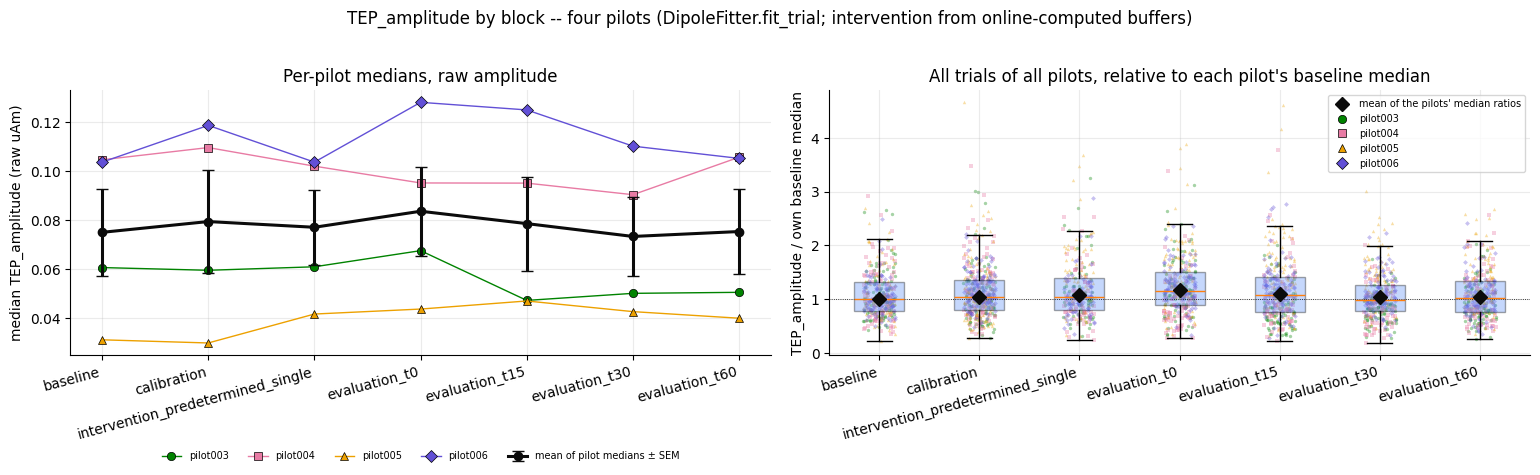

median TEP_amplitude (raw uAm):


,pilot003,pilot004,pilot005,pilot006,mean
baseline,0.0605,0.1045,0.0311,0.1035,0.0749
calibration,0.0594,0.1095,0.0298,0.1185,0.0793
intervention_predetermined_single,0.0608,0.1019,0.0416,0.1035,0.0770
evaluation_t0,0.0674,0.0950,0.0436,0.1279,0.0835
evaluation_t15,0.0471,0.0950,0.0469,0.1248,0.0785
evaluation_t30,0.0500,0.0902,0.0425,0.1100,0.0732
evaluation_t60,0.0504,0.1055,0.0399,0.1051,0.0752


median relative to the pilot's own baseline median:


,pilot003,pilot004,pilot005,pilot006,mean
baseline,1.000,1.000,1.000,1.000,1.000
calibration,0.982,1.048,0.958,1.145,1.033
intervention_predetermined_single,1.005,0.975,1.338,1.000,1.080
evaluation_t0,1.114,0.910,1.404,1.236,1.166
evaluation_t15,0.779,0.909,1.510,1.206,1.101
evaluation_t30,0.826,0.864,1.370,1.063,1.031
evaluation_t60,0.833,1.010,1.283,1.015,1.035


n per block:


,pilot003,pilot004,pilot005,pilot006
baseline,95,95,83,99
calibration,110,116,111,121
intervention_predetermined_single,70,73,74,77
evaluation_t0,92,91,97,100
evaluation_t15,90,88,84,98
evaluation_t30,96,92,82,99
evaluation_t60,90,95,80,98


In [49]:
calib_amp = {p: replay_all.loc[(replay_all.pilot == p) & (replay_all.block == "calibration"), "tep_amplitude"]
             .dropna().to_numpy() for p in PILOTS}
rows = {}
for p in PILOTS:
    R = REPLAYS[p]
    rows[p] = {"intervention predetermined, post passed online": R["intervention_n_eligible"],
               "  missing _post_proc.npy": R["intervention_n_missing"],
               "  TEP_amplitude values": len(R["intervention_tep_amplitude"]),
               "calibration, post passed in the replay": len(calib_amp[p])}
print("n trials (of 80 predetermined singles and 125 calibration trials per session):")
display(with_mean(pd.DataFrame(rows)).round(2))

def _amplitudes(p, label):
    if label == "calibration":
        return calib_amp[p]
    if label == INTERVENTION_LABEL:
        return REPLAYS[p]["intervention_tep_amplitude"]
    return replay.loc[(replay.pilot == p) & (replay.block == label), "tep_amplitude"].dropna().to_numpy()

AMP = {p: {b: _amplitudes(p, b) for b in BOXPLOT_LABELS} for p in PILOTS}
amp_median = pd.DataFrame({p: {b: np.median(AMP[p][b]) for b in BOXPLOT_LABELS} for p in PILOTS}).reindex(BOXPLOT_LABELS)
baseline_median = amp_median.loc["baseline"]
amp_ratio = amp_median / baseline_median

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5))
x = np.arange(len(BOXPLOT_LABELS))
ax = axes[0]
for p in PILOTS:
    ax.plot(x, amp_median[p], color=PILOT_COLORS[p], marker=PILOT_MARKERS[p], markeredgecolor="black",
            markeredgewidth=0.5, lw=1, label=p)
ax.errorbar(x, amp_median.mean(axis=1), yerr=amp_median.sem(axis=1), color=COLOR_MEAN, marker="o", lw=2.2,
            capsize=4, label="mean of pilot medians ± SEM")
ax.set_xticks(x)
ax.set_xticklabels(BOXPLOT_LABELS, rotation=15, ha="right")
ax.set_ylabel("median TEP_amplitude (raw uAm)")
ax.set_title("Per-pilot medians, raw amplitude")
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.33), ncol=5, frameon=False)

ax = axes[1]
pooled = [np.concatenate([AMP[p][b] / baseline_median[p] for p in PILOTS]) for b in BOXPLOT_LABELS]
bp = ax.boxplot(pooled, positions=x, widths=0.5, showfliers=False, patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor(COLOR_PREDETERMINED)
    patch.set_alpha(0.35)
rng = np.random.default_rng(0)
for i, b in enumerate(BOXPLOT_LABELS):
    for p in PILOTS:
        v = AMP[p][b] / baseline_median[p]
        ax.scatter(i + rng.uniform(-0.16, 0.16, len(v)), v, s=6, alpha=0.35, color=PILOT_COLORS[p],
                   marker=PILOT_MARKERS[p], linewidths=0)
ax.plot(x, amp_ratio.mean(axis=1), color=COLOR_MEAN, marker="D", lw=0, ms=7, zorder=5,
        label="mean of the pilots' median ratios")
ax.axhline(1.0, color="k", lw=0.6, ls=":")
ax.set_xticks(x)
ax.set_xticklabels(BOXPLOT_LABELS, rotation=15, ha="right")
ax.set_ylabel("TEP_amplitude / own baseline median")
ax.set_title("All trials of all pilots, relative to each pilot's baseline median")
h, l = ax.get_legend_handles_labels()
ax.legend(handles=h + pilot_marker_handles(), fontsize=7)
fig.suptitle("TEP_amplitude by block -- four pilots (DipoleFitter.fit_trial; intervention from online-computed "
             "buffers)", y=1.02)
fig.tight_layout()
plt.show()

print("median TEP_amplitude (raw uAm):")
display(with_mean(amp_median).round(4))
print("median relative to the pilot's own baseline median:")
display(with_mean(amp_ratio).round(3))
print("n per block:")
display(pd.DataFrame({p: {b: len(AMP[p][b]) for b in BOXPLOT_LABELS} for p in PILOTS}).reindex(BOXPLOT_LABELS))

## Item 2 · `prediction_probability` from the pre-stimulus buffers, via the 5 stored classifiers

As in the single-session notebook, each of the five stored checkpoints
(`classifier_after_calibration.pt`, `_after_trial_200/400/600/800.pt`) is evaluated as a frozen
snapshot on every baseline/evaluation trial whose pre-stimulus window preprocesses cleanly.
`OnlinePredictor` needs CUDA, so this cell first looks for each session's
`<pilot>_classifier_predictions.csv` — in this notebook's output folder, then in the single-session
notebook's (`PRIME_online_performance_outputs/`). It only computes a session that has neither, and
only in a kernel with CUDA-capable PyTorch (plus omegaconf, scikit-learn, mne_icalabel); results go
to this notebook's output folder. The pre-stimulus path does not depend on the as-run settings of
section 1 (the replay check verified it against the online data). The table below checks that each
file covers exactly the trials this replay preprocessed successfully.

In [50]:
CLASSIFIER_COLS = [
    "prediction_probability_after_calibration",
    "prediction_probability_after_trial_200",
    "prediction_probability_after_trial_400",
    "prediction_probability_after_trial_600",
    "prediction_probability_after_trial_800",
]
CHECKPOINTS = [c.replace("prediction_probability_", "") for c in CLASSIFIER_COLS]
SEED_PREDICTOR = 201   # prime/decider/2_intervention.py, module-level SEED constant

predictions, prediction_source = {}, {}
for p in PILOTS:
    for folder in (OUTPUT_DIR, SINGLE_SESSION_OUTPUT_DIR):
        f = folder / f"{p}_classifier_predictions.csv"
        if f.is_file():
            predictions[p], prediction_source[p] = pd.read_csv(f), f
            break

missing = [p for p in PILOTS if p not in predictions]
if missing:
    try:
        import torch
        _cuda_ok = torch.cuda.is_available()
    except ImportError:
        torch, _cuda_ok = None, False
    if not _cuda_ok:
        print(f"no cached predictions for {missing}, and {'PyTorch is not installed' if torch is None else 'CUDA is not available'} "
              f"in this kernel -- OnlinePredictor hardcodes torch.device('cuda'). Item 2.1 and the classifier "
              f"columns of item 3 stay empty for these sessions.")
    else:
        from prime_core.online_predictor import OnlinePredictor
        global_backrotation = np.load(DECIDER_DIR / "offline_results" / "train" / "global_backrotation_all.npy")
        for p in missing:
            d, pp = SESSION_DIRS[p], restore_session(p)["preprocessor"]
            keys, bufs = [], []
            for stage, run, label in BLOCKS:
                for trial in range(_n_trials(d, stage, run)):
                    pre_raw = np.load(d / f"{_stem(stage, run, trial)}_pre_raw.npy")
                    buf = pp.preprocess_pre(pre_raw, QC_TMIN + np.arange(pre_raw.shape[0]) / RAW_SFREQ, from_pulse=True)
                    if buf is not None:
                        keys.append((label, run, trial))
                        bufs.append(buf)
            df = pd.DataFrame(keys, columns=["block", "run_index", "trial_in_stage"])
            bufs = np.stack(bufs, axis=0)
            for name, col in zip(CHECKPOINTS, CLASSIFIER_COLS):
                predictor = OnlinePredictor(global_backrotation, model_path=d / f"classifier_{name}.pt", seed=SEED_PREDICTOR)
                df[col] = predictor.predict_batch(bufs, batch_size=50)
                del predictor
                torch.cuda.empty_cache()
            prediction_source[p] = OUTPUT_DIR / f"{p}_classifier_predictions.csv"
            df.to_csv(prediction_source[p], index=False)
            predictions[p] = df
            print(f"{p}: computed {len(df)} predictions -> {prediction_source[p].name}")

def _trial_keys(df):
    k = df[["block", "run_index", "trial_in_stage"]].copy()
    k["run_index"] = pd.to_numeric(k["run_index"]).fillna(0).astype(int)
    k["trial_in_stage"] = k["trial_in_stage"].astype(int)
    return set(map(tuple, k.itertuples(index=False)))

rows = {}
for p in predictions:
    predictions[p]["run_index"] = pd.to_numeric(predictions[p]["run_index"])
    ok = replay[(replay.pilot == p) & replay.preprocessing_success.astype(bool)]
    rows[p] = {"rows": len(predictions[p]), "replay: preprocessed successfully": len(ok),
               "same trials": _trial_keys(predictions[p]) == _trial_keys(ok), "folder": prediction_source[p].parent.name}
print("cached predictions vs. this replay's pre-stimulus successes:")
display(pd.DataFrame(rows))

cached predictions vs. this replay's pre-stimulus successes:


,pilot003,pilot004,pilot005,pilot006
rows,474,478,489,477
replay: preprocessed successfully,474,478,489,477
same trials,True,True,True,True
folder,PRIME_online_performance_outputs,PRIME_online_performance_outputs,PRIME_online_performance_outputs,PRIME_online_performance_outputs


### 2.1 · Correlating predictions with `TEP_amplitude`, per classifier

Pearson r is computed within each pilot (raw µAm); the panel title gives the mean over pilots
(Fisher's z). To put the four pilots on one axis, the scatter shows each trial's amplitude divided
by its pilot's baseline median; each pilot's fit line is drawn on that scale.

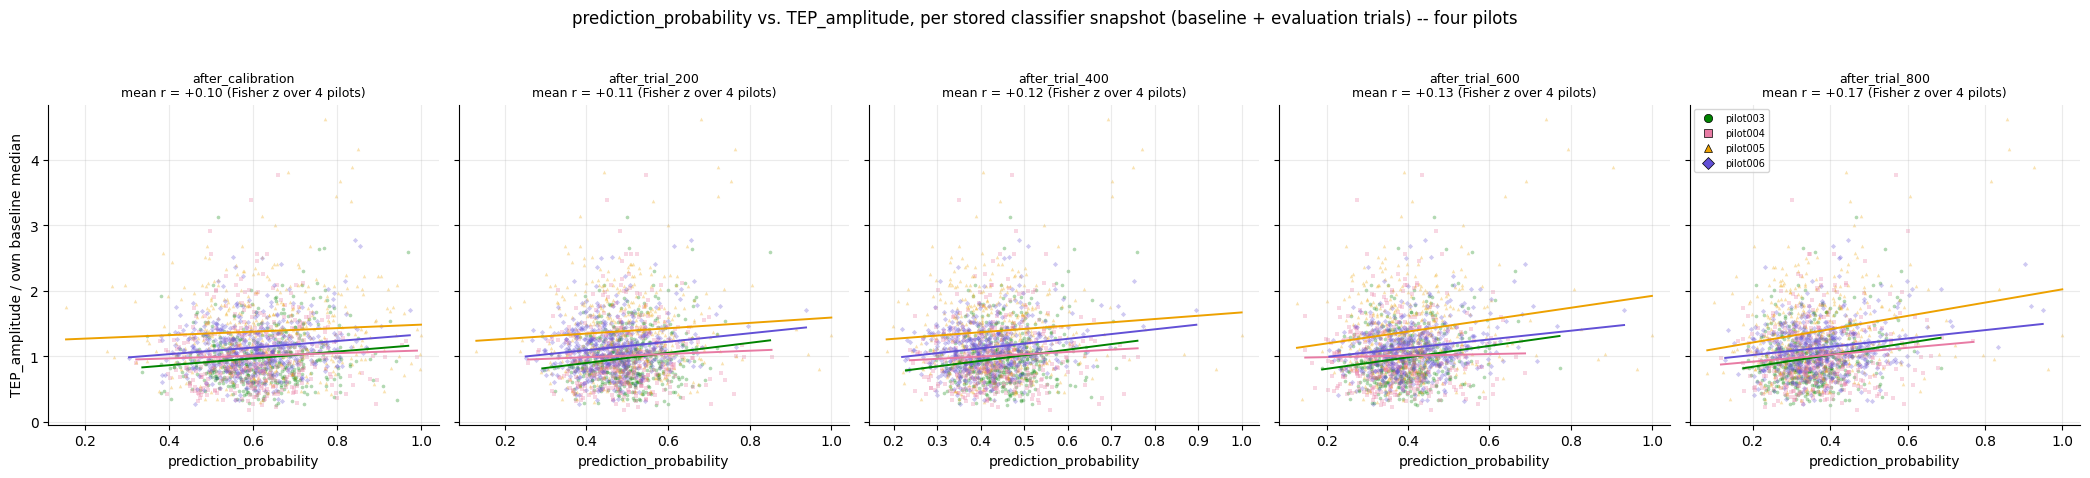

Pearson r(prediction_probability, TEP_amplitude), within each pilot:


,after_calibration,after_trial_200,after_trial_400,after_trial_600,after_trial_800
pilot003,0.134,0.148,0.159,0.168,0.180
pilot004,0.044,0.046,0.064,0.023,0.112
pilot005,0.061,0.075,0.087,0.168,0.218
pilot006,0.142,0.156,0.178,0.171,0.188
mean (Fisher z),0.095,0.107,0.122,0.133,0.175


n per pilot:


,after_calibration,after_trial_200,after_trial_400,after_trial_600,after_trial_800
pilot003,449,449,449,449,449
pilot004,449,449,449,449,449
pilot005,418,418,418,418,418
pilot006,471,471,471,471,471


In [51]:
merged = {p: replay[replay.pilot == p].merge(predictions[p], on=["block", "run_index", "trial_in_stage"], how="left")
          for p in predictions}
if not merged:
    print("skipped -- no classifier predictions available (item 2).")
else:
    base_med = {p: m.loc[m.block == "baseline", "tep_amplitude"].median() for p, m in merged.items()}
    fig, axes = plt.subplots(1, len(CLASSIFIER_COLS), figsize=(21, 4.6), sharey=True)
    r_tab, n_tab = {}, {}
    for ax, col in zip(axes, CLASSIFIER_COLS):
        rs, ns = {}, {}
        for p, m in merged.items():
            d = m.dropna(subset=[col, "tep_amplitude"])
            y = d.tep_amplitude / base_med[p]
            ax.scatter(d[col], y, s=7, alpha=0.3, color=PILOT_COLORS[p], marker=PILOT_MARKERS[p], linewidths=0)
            if len(d) > 2:
                rs[p] = stats.pearsonr(d[col], d.tep_amplitude)[0]
                ns[p] = len(d)
                b1, b0 = np.polyfit(d[col], y, 1)
                xs = np.linspace(d[col].min(), d[col].max(), 20)
                ax.plot(xs, b0 + b1 * xs, color=PILOT_COLORS[p], lw=1.4)
        name = col.replace("prediction_probability_", "")
        r_tab[name], n_tab[name] = rs, ns
        ax.set_title(f"{name}\nmean r = {mean_r(rs.values()):+.2f} (Fisher z over {len(rs)} pilots)", fontsize=9)
        ax.set_xlabel("prediction_probability")
    axes[0].set_ylabel("TEP_amplitude / own baseline median")
    axes[-1].legend(handles=pilot_marker_handles(), fontsize=7)
    fig.suptitle("prediction_probability vs. TEP_amplitude, per stored classifier snapshot (baseline + evaluation "
                 "trials) -- four pilots", y=1.03)
    fig.tight_layout()
    plt.show()

    r_df = pd.DataFrame(r_tab)
    r_df.loc["mean (Fisher z)"] = [mean_r(r_df[c].reindex(PILOTS)) for c in r_df.columns]
    print("Pearson r(prediction_probability, TEP_amplitude), within each pilot:")
    display(r_df.round(3))
    print("n per pilot:")
    display(pd.DataFrame(n_tab))

## Item 3 · Per-trial CSV across the 5 replayed blocks

One row per baseline/evaluation trial of all four pilots (a `pilot` column added), with the same
columns as the single-session notebook's `<SUBJECT_ID>_trial_table.csv`: pre/post processing
outcome and reject reason, `TEP_amplitude`, the two baseline-correction diagnostics, and the five
classifiers' `prediction_probability`. It is written to this notebook's output folder as
`pilot003-006_trial_table.csv`; the single-session notebook's per-subject tables are not touched.

In [52]:
parts = []
for p in PILOTS:
    t = replay[replay.pilot == p]
    if p in predictions:
        t = t.merge(predictions[p], on=["block", "run_index", "trial_in_stage"], how="left")
    else:
        t = t.assign(**{c: np.nan for c in CLASSIFIER_COLS})
    parts.append(t)
final = pd.concat(parts, ignore_index=True)
OUT_CSV = OUTPUT_DIR / "pilot003-006_trial_table.csv"
final.to_csv(OUT_CSV, index=False)
print(f"wrote {len(final)} rows x {len(final.columns)} columns to {_rel(OUT_CSV)}")
display(final.groupby("pilot").size().rename("rows").to_frame().T)
display(final.head(5))

wrote 2000 rows x 15 columns to scripts_analysis/PRIME_online_performance_avg_outputs/pilot003-006_trial_table.csv


pilot,pilot003,pilot004,pilot005,pilot006
rows,500,500,500,500


,pilot,block,run_index,trial_in_stage,preprocessing_success,postprocessing_success,postprocessing_reject_reason,tep_amplitude,baseline_correction_1_mean_abs,baseline_correction_2_mean_abs,prediction_probability_after_calibration,prediction_probability_after_trial_200,prediction_probability_after_trial_400,prediction_probability_after_trial_600,prediction_probability_after_trial_800
0,pilot003,baseline,NaN,0,True,True,None,0.080204,12848.368952,0.002505,0.479434,0.399746,0.367794,0.325640,0.274292
1,pilot003,baseline,NaN,1,True,True,None,0.045169,12842.530428,0.002505,0.689184,0.588466,0.515569,0.441774,0.363398
2,pilot003,baseline,NaN,2,True,True,None,0.056245,12831.084610,0.002505,0.714247,0.550267,0.494629,0.470928,0.494759
3,pilot003,baseline,NaN,3,True,True,None,0.036166,12815.402671,0.002505,0.655703,0.509675,0.476766,0.394431,0.338768
4,pilot003,baseline,NaN,4,True,True,None,0.050748,12831.355683,0.002505,0.426508,0.361683,0.333630,0.305196,0.279054


## Item 4 · Sensor-space TEPs per block

The same four views as the single-session notebook, for `ALL_BLOCK_LABELS` (baseline, the
intervention's `predetermined_single` trials, the four evaluation runs). Each session's
grand-average epoch per block is computed first (replayed `last_post_full` epochs; the online
`_post_proc.npy` epochs for intervention). Then:

- **Time axis.** pilot003–005 are sampled at 1 kHz (1, 2, …, 100 ms). pilot006 is at 5 kHz, after
  its 500 Hz low-pass. Its grand averages are read at the same whole-millisecond times: these are
  samples of the 5 kHz grid, so nothing is interpolated. All averages below are on that 1 kHz grid.
- **Channels** are averaged across pilots channel by channel (grey butterfly lines, items 4.3/4.4).
  The six channels of interest are interpolated in some sessions (bad channels differ); titles and
  line styles say in how many.
- **GFP** is averaged across pilots, not taken from the channel-wise grand average. The four
  dipoles differ, so topographies partly cancel in a channel-wise average and its GFP would be
  smaller than any session's own GFP.

The early lead-in is synthetic in every session (both artifact blanks are interpolated; the first
blank starts at −14 ms in pilot003–005 and −2 ms in pilot006 and ends at 14 ms, the second covers
1–15 ms). The dipole-fitting epoch (38–50 ms) is shaded.

In [53]:
COMMON_TIME_MS = np.arange(round(POST_TMIN * 1000), round(POST_TMAX * 1000) + 1, dtype=float)   # 1..100 ms

def to_common_grid(arr, t_ms):
    """Read a (..., n_times) array at COMMON_TIME_MS. For pilot006 (5 kHz) these times are samples of
    its own grid; for the 1 kHz sessions this is the identity."""
    arr = np.asarray(arr, float)
    if len(t_ms) == len(COMMON_TIME_MS) and np.allclose(t_ms, COMMON_TIME_MS):
        return arr
    flat = arr.reshape(-1, arr.shape[-1])
    return np.vstack([np.interp(COMMON_TIME_MS, t_ms, row) for row in flat]).reshape(arr.shape[:-1] + (len(COMMON_TIME_MS),))

EVOKED = {p: {k: to_common_grid(v, REPLAYS[p]["post_time_ms"]) for k, v in REPLAYS[p]["evoked"].items()} for p in PILOTS}
N_TRIALS = {p: REPLAYS[p]["n"] for p in PILOTS}
GFP = {p: {k: v.std(axis=0, ddof=0) for k, v in EVOKED[p].items()} for p in PILOTS}
_labels = sorted(set().union(*(EVOKED[p].keys() for p in PILOTS)))
GRAND = {k: np.mean([EVOKED[p][k] for p in PILOTS if k in EVOKED[p]], axis=0) for k in _labels}       # channel-wise
MEAN_GFP = {k: np.mean([GFP[p][k] for p in PILOTS if k in GFP[p]], axis=0) for k in _labels}
GRAND_N = {k: "+".join(str(N_TRIALS[p].get(k, 0)) for p in PILOTS) for k in _labels}
INTERPOLATED_IN = {ch: [p for p in PILOTS if ch in [str(c) for c in bundles[p]["bad_channels"]]] for ch in CH_NAMES}
dipole_epoch_tmin_ms, dipole_epoch_tmax_ms = DIPOLE_TMIN * 1000, DIPOLE_TMAX * 1000

print(f"common time grid: {COMMON_TIME_MS[0]:.0f}-{COMMON_TIME_MS[-1]:.0f} ms, {len(COMMON_TIME_MS)} samples; native rates: "
      + ", ".join(f"{p} {REPLAYS[p]['post_sfreq']:.0f} Hz" for p in PILOTS))
print("trials averaged per block (pilot003+pilot004+pilot005+pilot006):")
for k in ALL_BLOCK_LABELS:
    print(f"  {k:34s} {GRAND_N[k]}")

common time grid: 1-100 ms, 100 samples; native rates: pilot003 1000 Hz, pilot004 1000 Hz, pilot005 1000 Hz, pilot006 5000 Hz
trials averaged per block (pilot003+pilot004+pilot005+pilot006):
  baseline                           95+95+83+99
  intervention_predetermined_single  70+73+74+77
  evaluation_t0                      92+91+97+100
  evaluation_t15                     90+88+84+98
  evaluation_t30                     96+92+82+99
  evaluation_t60                     90+95+80+98


### 4.1 · Butterfly plot per block

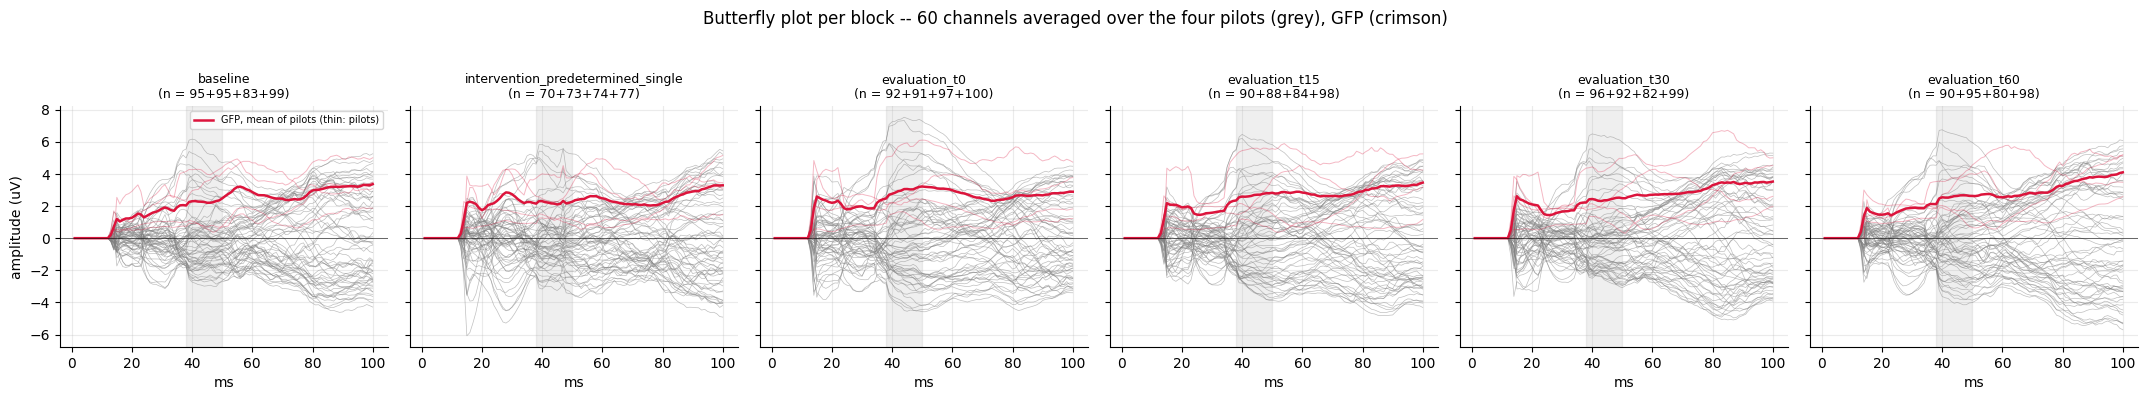

In [54]:
fig, axes = plt.subplots(1, len(ALL_BLOCK_LABELS), figsize=(3.6 * len(ALL_BLOCK_LABELS), 3.8), sharey=True, sharex=True)
for ax, b in zip(axes, ALL_BLOCK_LABELS):
    ax.plot(COMMON_TIME_MS, GRAND[b].T, lw=0.5, color="grey", alpha=0.5)
    for p in PILOTS:
        ax.plot(COMMON_TIME_MS, GFP[p][b], lw=0.7, color="crimson", alpha=0.3)
    ax.plot(COMMON_TIME_MS, MEAN_GFP[b], lw=1.8, color="crimson", label="GFP, mean of pilots (thin: pilots)")
    ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12)
    ax.axhline(0, color="black", lw=0.4)
    ax.set_title(f"{b}\n(n = {GRAND_N[b]})", fontsize=9)
    ax.set_xlabel("ms")
axes[0].set_ylabel("amplitude (uV)")
axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Butterfly plot per block -- 60 channels averaged over the four pilots (grey), GFP (crimson)", y=1.04)
fig.tight_layout()
plt.show()

### 4.2 · GFP per block

`GFP(t)` = population standard deviation across the 60 channels of a session's grand average,
averaged over the four pilots. It is polarity-blind, so it only shows that something happens at a
latency; 4.3 shows the signed voltage. As in the single-session notebook, a rise towards the
buffer's 100 ms edge cannot be told apart from a filter or epoch-boundary effect.

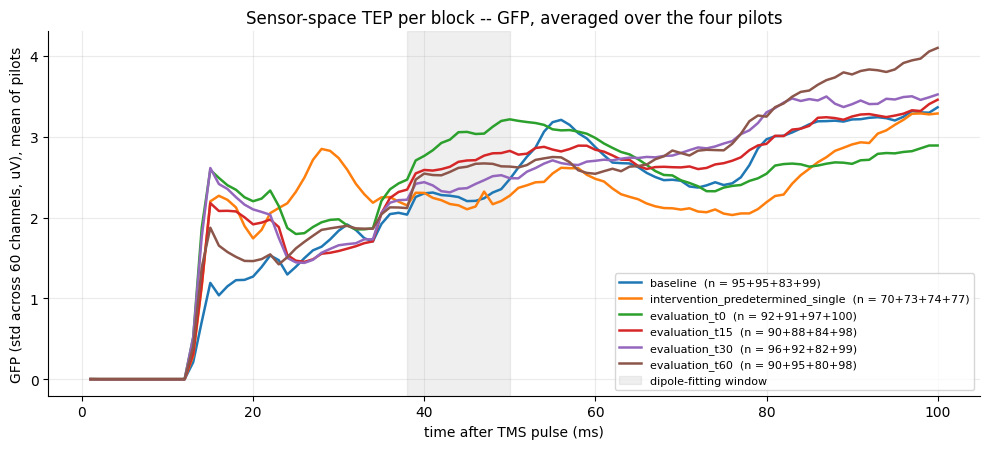

,mean GFP: peak,mean GFP: at (ms),pilot003: peak at (ms),pilot004: peak at (ms),pilot005: peak at (ms),pilot006: peak at (ms)
baseline,3.365,100.0,58.0,58.0,85.0,88.0
intervention_predetermined_single,3.289,98.0,97.0,100.0,95.0,47.0
evaluation_t0,3.216,50.0,44.0,14.0,48.0,50.0
evaluation_t15,3.458,100.0,40.0,59.0,100.0,54.0
evaluation_t30,3.524,100.0,100.0,61.0,100.0,85.0
evaluation_t60,4.100,100.0,100.0,62.0,100.0,89.0


In [55]:
fig, ax = plt.subplots(figsize=(10, 4.6))
for b in ALL_BLOCK_LABELS:
    ax.plot(COMMON_TIME_MS, MEAN_GFP[b], lw=1.8, label=f"{b}  (n = {GRAND_N[b]})")
ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12, label="dipole-fitting window")
ax.set_xlabel("time after TMS pulse (ms)")
ax.set_ylabel("GFP (std across 60 channels, uV), mean of pilots")
ax.set_title("Sensor-space TEP per block -- GFP, averaged over the four pilots")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

rows = {}
for b in ALL_BLOCK_LABELS:
    i = int(np.argmax(MEAN_GFP[b]))
    rows[b] = {"mean GFP: peak": MEAN_GFP[b][i], "mean GFP: at (ms)": COMMON_TIME_MS[i],
               **{f"{p}: peak at (ms)": COMMON_TIME_MS[int(np.argmax(GFP[p][b]))] for p in PILOTS}}
display(pd.DataFrame(rows).T.round(3))

### 4.3 · `FC3`, `C1`, `C3`, `C5`, `CP3`, `Cz` individually

One panel per channel, every block overlaid, each line the channel-wise mean of the four pilots'
grand averages. Candidate P30 / N45 / P60 peaks are marked where a local extremum of the expected
sign occurs in a fixed latency window (N45: the 38–50 ms dipole-fitting epoch); a window dominated
by the opposite polarity is left blank. Panel titles say in how many sessions the channel was
interpolated rather than measured.

FC3: interpolated (not measured) in 1/4 sessions -- pilot006
C1: measured in all four sessions
C3: interpolated (not measured) in 3/4 sessions -- pilot003, pilot005, pilot006
C5: measured in all four sessions
CP3: interpolated (not measured) in 2/4 sessions -- pilot003, pilot005
Cz: measured in all four sessions


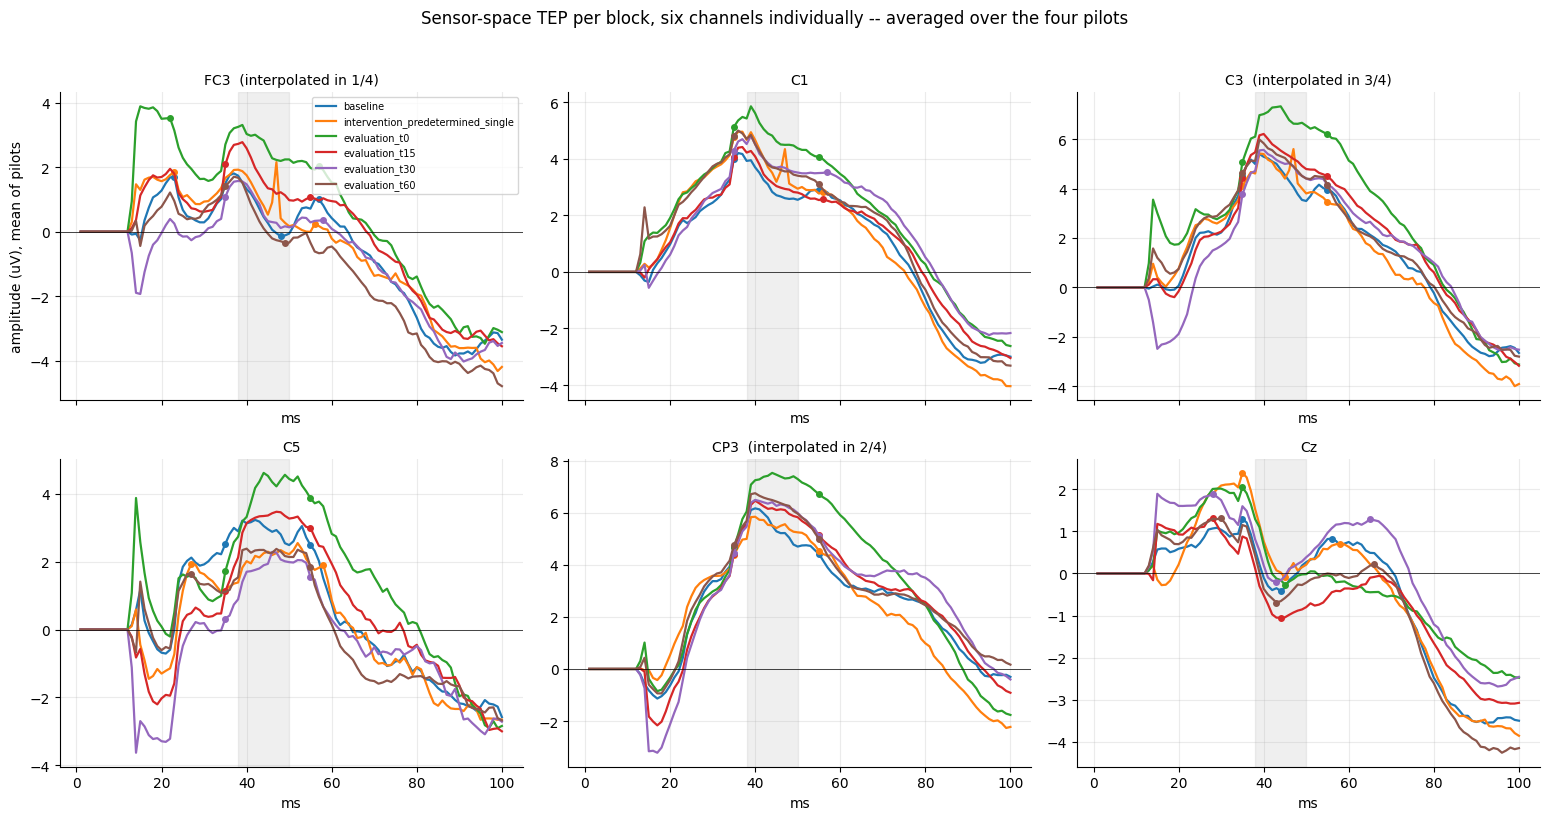

P30_latency_ms  P30_amplitude  N45_latency_ms  N45_amplitude  P60_latency_ms  P60_amplitude
channel block                                                                                                                         
FC3     baseline                                     23.0          1.700            48.0         -0.141            57.0          0.999
        intervention_predetermined_single            23.0          1.848             NaN            NaN            56.0          0.242
        evaluation_t0                                22.0          3.517             NaN            NaN            57.0          2.024
        evaluation_t15                               35.0          2.083             NaN            NaN            55.0          1.069
        evaluation_t30                               35.0          1.082             NaN            NaN            58.0          0.357
        evaluation_t60                               35.0          1.411            49.0         -0.342             NaN            NaN
C1      baseline                                     35.0          3.986             NaN            NaN            55.0          2.903
        intervention_predetermined_single            35.0          4.773             NaN            NaN            56.0          2.820
        evaluation_t0                                35.0          5.127             NaN            NaN            55.0          4.063
        evaluation_t15                               35.0          4.062             NaN            NaN            56.0          2.590
        evaluation_t30                               35.0          4.287             NaN            NaN            57.0          3.549
        evaluation_t60                               35.0          4.806             NaN            NaN            55.0          3.095
C3      baseline                                     35.0          4.519             NaN            NaN            55.0          3.947
        intervention_predetermined_single            35.0          4.107             NaN            NaN            55.0          3.450
        evaluation_t0                                35.0          5.072             NaN            NaN            55.0          6.195
        evaluation_t15                               35.0          4.438             NaN            NaN            55.0          4.496
        evaluation_t30                               35.0          3.760             NaN            NaN            55.0          4.151
        evaluation_t60                               35.0          4.618             NaN            NaN            55.0          4.155
C5      baseline                                     35.0          2.526             NaN            NaN            55.0          2.485
        intervention_predetermined_single            27.0          1.942             NaN            NaN            58.0          1.912
        evaluation_t0                                35.0          1.717             NaN            NaN            55.0          3.867
        evaluation_t15                               35.0          1.130             NaN            NaN            55.0          2.998
        evaluation_t30                               35.0          0.323             NaN            NaN            55.0          1.542
        evaluation_t60                               27.0          1.634             NaN            NaN            55.0          1.846
CP3     baseline                                     35.0          4.674             NaN            NaN            55.0          4.417
        intervention_predetermined_single            35.0          4.371             NaN            NaN            55.0          4.541
        evaluation_t0                                35.0          4.665             NaN            NaN            55.0          6.708
        evaluation_t15                               35.0          4.420             NaN            NaN            55.0         

In [56]:
CHANNELS_OF_INTEREST = [c for c in ["FC3", "C1", "C3", "C5", "CP3", "Cz"] if c in CH_NAMES]
for ch in CHANNELS_OF_INTEREST:
    if INTERPOLATED_IN[ch]:
        print(f"{ch}: interpolated (not measured) in {len(INTERPOLATED_IN[ch])}/4 sessions -- {', '.join(INTERPOLATED_IN[ch])}")
    else:
        print(f"{ch}: measured in all four sessions")

COMPONENT_WINDOWS = {
    "P30": (20.0, 35.0, "max"),
    "N45": (dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, "min"),
    "P60": (55.0, 75.0, "max"),
}

def _local_extremum(trace_1d, lo_ms, hi_ms, kind):
    win_idx = np.where((COMMON_TIME_MS >= lo_ms) & (COMMON_TIME_MS <= hi_ms))[0]
    seg = trace_1d[win_idx]
    i = win_idx[int(np.argmax(seg) if kind == "max" else np.argmin(seg))]
    lat, amp = COMMON_TIME_MS[i], trace_1d[i]
    if (kind == "max" and amp < 0) or (kind == "min" and amp > 0):
        return np.nan, np.nan
    return lat, amp

def _interp_note(ch):
    k = len(INTERPOLATED_IN[ch])
    return f"  (interpolated in {k}/4)" if k else ""

n_cols = min(3, len(CHANNELS_OF_INTEREST))
n_rows = int(np.ceil(len(CHANNELS_OF_INTEREST) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 4.0 * n_rows), sharex=True)
axes = np.atleast_1d(axes).ravel()
peak_records = []
for ax, ch in zip(axes, CHANNELS_OF_INTEREST):
    idx = CH_NAMES.index(ch)
    for b in ALL_BLOCK_LABELS:
        trace = GRAND[b][idx]
        line, = ax.plot(COMMON_TIME_MS, trace, lw=1.6, label=b)
        row = {"channel": ch, "block": b}
        for comp, (lo, hi, kind) in COMPONENT_WINDOWS.items():
            lat, amp = _local_extremum(trace, lo, hi, kind)
            if not np.isnan(amp):
                ax.plot(lat, amp, marker="o", ms=4, color=line.get_color())
            row[f"{comp}_latency_ms"], row[f"{comp}_amplitude"] = lat, amp
        peak_records.append(row)
    ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(ch + _interp_note(ch), fontsize=10)
    ax.set_xlabel("ms")
for ax in axes[len(CHANNELS_OF_INTEREST):]:
    ax.set_visible(False)
axes[0].set_ylabel("amplitude (uV), mean of pilots")
axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Sensor-space TEP per block, six channels individually -- averaged over the four pilots", y=1.02)
fig.tight_layout()
plt.show()

display(pd.DataFrame.from_records(peak_records).set_index(["channel", "block"]).round(3))

### 4.4 · `FC3`, `C1`, `C3`, `C5`, `CP3`, `Cz` together

The same six channels within each block's panel. Dashed lines mark channels interpolated in at
least one session (the legend gives how many); solid lines are measured in all four.

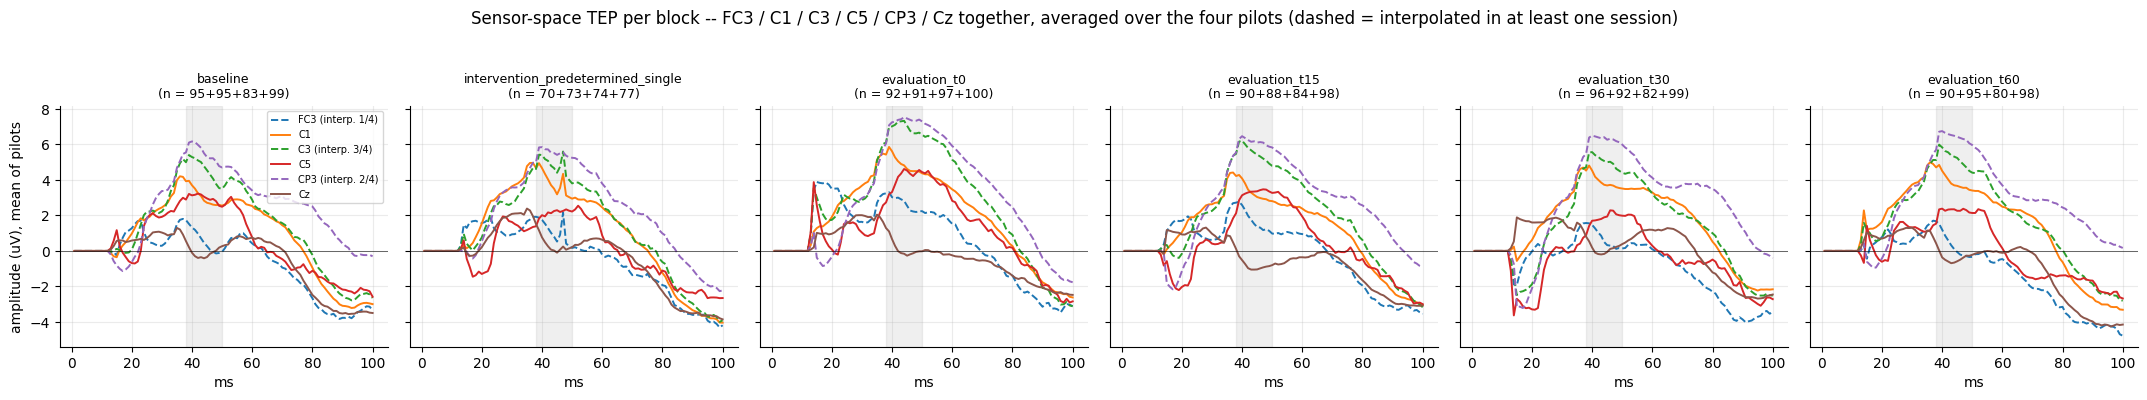

In [57]:
fig, axes = plt.subplots(1, len(ALL_BLOCK_LABELS), figsize=(3.6 * len(ALL_BLOCK_LABELS), 3.8), sharey=True, sharex=True)
channel_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for ax, b in zip(axes, ALL_BLOCK_LABELS):
    for ci, ch in enumerate(CHANNELS_OF_INTEREST):
        k = len(INTERPOLATED_IN[ch])
        ax.plot(COMMON_TIME_MS, GRAND[b][CH_NAMES.index(ch)], lw=1.4, ls="--" if k else "-",
                color=channel_colors[ci % len(channel_colors)], label=ch + (f" (interp. {k}/4)" if k else ""))
    ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12)
    ax.axhline(0, color="black", lw=0.4)
    ax.set_title(f"{b}\n(n = {GRAND_N[b]})", fontsize=9)
    ax.set_xlabel("ms")
axes[0].set_ylabel("amplitude (uV), mean of pilots")
axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Sensor-space TEP per block -- FC3 / C1 / C3 / C5 / CP3 / Cz together, averaged over the four pilots "
             "(dashed = interpolated in at least one session)", y=1.04)
fig.tight_layout()
plt.show()

### 4.5 · Sensor-space TEPs by prediction probability

Within each session, `prime_single_pulse` trials with a `prediction_probability` and
`~postprocessing_failed` are split at that session's own 25th and 75th percentiles (forced trials
have no probability and drop out), and compared with the session's `predetermined_single` average
from item 1.1. Quartiles are taken within each pilot because the probability scale drifts
differently in every session. The four pilots' GFPs are then averaged (as in 4.2), and `Cz` is
averaged channel-wise (as in 4.3).

,pilot003,pilot004,pilot005,pilot006,mean
prime_single_pulse trials,240.000,240.000,240.000,240.000,240.000
forced,18.000,21.000,9.000,5.000,13.250
without prediction_probability,18.000,21.000,9.000,5.000,13.250
usable for ranking,186.000,198.000,212.000,231.000,206.750
bottom quartile: p <=,0.599,0.599,0.617,0.598,0.603
top quartile: p >=,0.733,0.735,0.764,0.681,0.728
n predetermined_single,70.000,73.000,74.000,77.000,73.500
n prime_single_top25pct,47.000,50.000,53.000,58.000,52.000
n prime_single_bottom25pct,47.000,50.000,53.000,58.000,52.000
missing _post_proc.npy,0.000,0.000,0.000,0.000,0.000


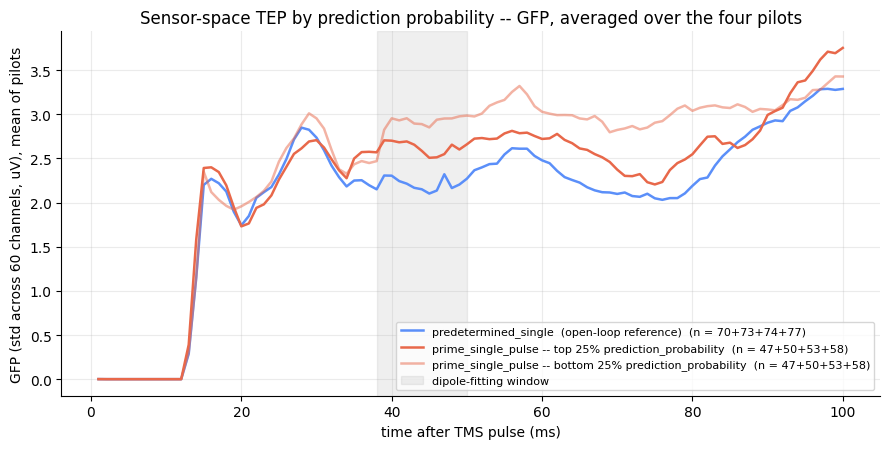

predetermined_single     mean GFP peak = 3.2890  at 98 ms
prime_single_top25pct    mean GFP peak = 3.7529  at 100 ms
prime_single_bottom25pct mean GFP peak = 3.4297  at 99 ms


In [58]:
PROB_KEYS = {"predetermined_single": INTERVENTION_LABEL,
             "prime_single_top25pct": "prime_single_top25pct",
             "prime_single_bottom25pct": "prime_single_bottom25pct"}
rows = {}
for p in PILOTS:
    R = REPLAYS[p]
    rows[p] = {"prime_single_pulse trials": R["n_prime_single"], "forced": R["n_forced"],
               "without prediction_probability": R["n_no_prob"], "usable for ranking": R["n_usable"],
               "bottom quartile: p <=": R["q25"], "top quartile: p >=": R["q75"],
               **{f"n {name}": R["n"].get(key, 0) for name, key in PROB_KEYS.items()},
               "missing _post_proc.npy": sum(R["group_missing"].values())}
display(with_mean(pd.DataFrame(rows)).round(3))

PROB_GROUP_LABELS = {
    "predetermined_single":     ("predetermined_single  (open-loop reference)", COLOR_PREDETERMINED, 1.0),
    "prime_single_top25pct":    ("prime_single_pulse -- top 25% prediction_probability", COLOR_PRIME_SINGLE, 1.0),
    "prime_single_bottom25pct": ("prime_single_pulse -- bottom 25% prediction_probability", COLOR_PRIME_SINGLE, 0.5),
}
fig, ax = plt.subplots(figsize=(9, 4.6))
for name, (label, color, alpha) in PROB_GROUP_LABELS.items():
    key = PROB_KEYS[name]
    ax.plot(COMMON_TIME_MS, MEAN_GFP[key], lw=1.8, color=color, alpha=alpha, label=f"{label}  (n = {GRAND_N[key]})")
ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12, label="dipole-fitting window")
ax.set_xlabel("time after TMS pulse (ms)")
ax.set_ylabel("GFP (std across 60 channels, uV), mean of pilots")
ax.set_title("Sensor-space TEP by prediction probability -- GFP, averaged over the four pilots")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for name in PROB_GROUP_LABELS:
    g = MEAN_GFP[PROB_KEYS[name]]
    i = int(np.argmax(g))
    print(f"{name:24s} mean GFP peak = {g[i]:.4f}  at {COMMON_TIME_MS[i]:.0f} ms")

Same three groups, `Cz` only — signed voltage, averaged channel-wise over the four pilots. The line
is dashed if `Cz` is interpolated in any session.

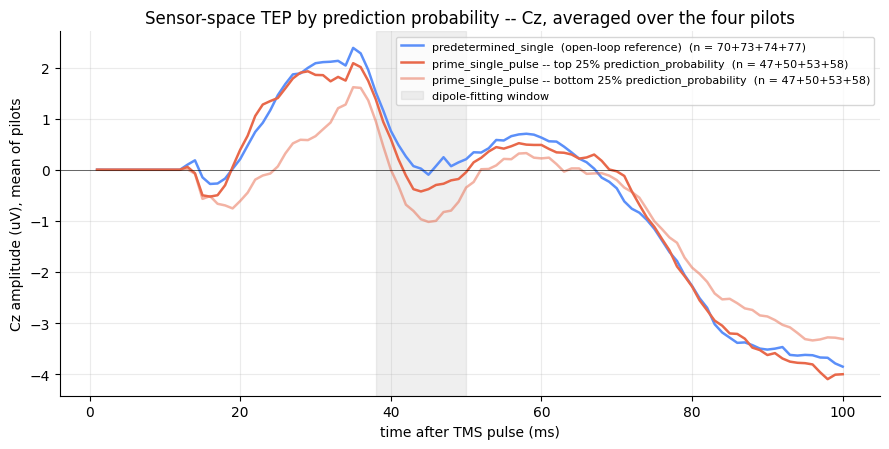

In [59]:
cz_idx = CH_NAMES.index("Cz")
cz_dashed = bool(INTERPOLATED_IN["Cz"])
fig, ax = plt.subplots(figsize=(9, 4.6))
for name, (label, color, alpha) in PROB_GROUP_LABELS.items():
    key = PROB_KEYS[name]
    ax.plot(COMMON_TIME_MS, GRAND[key][cz_idx], lw=1.8, ls="--" if cz_dashed else "-", color=color, alpha=alpha,
            label=f"{label}  (n = {GRAND_N[key]})")
ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12, label="dipole-fitting window")
ax.axhline(0, color="black", lw=0.4)
ax.set_xlabel("time after TMS pulse (ms)")
ax.set_ylabel("Cz amplitude (uV), mean of pilots")
ax.set_title("Sensor-space TEP by prediction probability -- Cz, averaged over the four pilots"
             + (f"  (Cz interpolated in {len(INTERPOLATED_IN['Cz'])}/4)" if cz_dashed else ""))
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

---
### Notes for reading and re-running

- To add or drop a session, edit `PILOTS` and `AS_RUN` in section 1 and re-run. A new session also
  needs its as-run settings. Chapter 2's replay check shows whether they reproduce the online data:
  every single pulse has to match its saved epoch, reject reason and amplitude.
- Chapter 2's cache (`cache/<pilot>_replay_check.pkl`, `cache/<pilot>_replay.pkl`) is refreshed
  automatically when the as-run settings, the checked-out `prime/decider` commit, or the size of a
  session's bundle or `trials_intervention.csv` changes. The `computed` column of the replay-check
  table shows where and when each cached result was made. Set `RECOMPUTE_REPLAY = True` to redo it
  regardless.
- Classifier predictions (item 2) are read from the per-session CSVs written by the single-session
  notebook; nothing here needs a GPU unless a session has none yet.
- Nothing in `prime/` is modified: the decider is imported with `sys.dont_write_bytecode = True`,
  and the as-run settings are set on this notebook's own `Preprocessor` instances.